In [5]:
# E01 — Verify the actual Google Colab runtime
import platform, importlib.util, subprocess, sys
if importlib.util.find_spec('pyspark') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'pyspark==4.0.4'], check=True)
from datetime import datetime, timezone

print('Run timestamp (UTC):', datetime.now(timezone.utc).isoformat())
print('Python:', platform.python_version())
print('Platform:', platform.platform())
print('PySpark installed:', importlib.util.find_spec('pyspark') is not None)
java_check = subprocess.run(['java', '-version'], capture_output=True, text=True)
print('Java:', (java_check.stderr or java_check.stdout).strip())


Run timestamp (UTC): 2026-10-15T04:39:22.833085+00:00
Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PySpark installed: True
Java: openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [6]:
# E02 — Start Spark and verify actual execution
import pyspark
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master('local[2]')
         .appName('INFOSYS722_I4_OnlineShoppers')
         .config('spark.sql.shuffle.partitions', '4')
         .getOrCreate())
spark.sparkContext.setLogLevel('WARN')
print('PySpark package:', pyspark.__version__)
print('Spark engine:', spark.version)
print('Execution master:', spark.sparkContext.master)
print('Parallelism:', spark.sparkContext.defaultParallelism)
print('Spark verification count:', spark.range(10).count())
print('Colab uses a single machine with 2 local Spark threads; this is not a multi-node cluster.')


PySpark package: 4.0.4
Spark engine: 4.0.4
Execution master: local[2]
Parallelism: 2
Spark verification count: 10
Colab uses a single machine with 2 local Spark threads; this is not a multi-node cluster.


In [7]:
# E03 — Connect Drive and verify the unchanged source file
from google.colab import drive
from pathlib import Path
import hashlib

drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/Infosys722_I4_BDAS')
DATA_PATH = PROJECT_ROOT / 'data' / 'online_shoppers_intention.csv'
assert DATA_PATH.is_file(), f'Missing data file: {DATA_PATH}'
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
expected_sha256 = 'b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9'
assert source_sha256 == expected_sha256, 'Source file differs from the locked I3 original'
print('Source path:', DATA_PATH)
print('File bytes:', DATA_PATH.stat().st_size)
print('SHA-256:', source_sha256)
print('Source matches the unchanged I3 original: PASS')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Source path: /content/drive/MyDrive/Infosys722_I4_BDAS/data/online_shoppers_intention.csv
File bytes: 1072063
SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Source matches the unchanged I3 original: PASS


In [8]:
# E04 — Read the unchanged CSV using Spark DataFrame
raw_df = (spark.read.options(header=True, inferSchema=True, mode='FAILFAST')
          .csv(str(DATA_PATH)).repartition(4).cache())
raw_rows = raw_df.count()
raw_columns = len(raw_df.columns)
print('DataFrame type:', type(raw_df).__module__ + '.' + type(raw_df).__name__)
print('Rows:', raw_rows)
print('Columns:', raw_columns)
print('Partitions:', raw_df.rdd.getNumPartitions())
assert raw_rows == 12330 and raw_columns == 18
print('Expected original dimensions: PASS')


DataFrame type: pyspark.sql.classic.dataframe.DataFrame
Rows: 12330
Columns: 18
Partitions: 4
Expected original dimensions: PASS


In [9]:
# E05 — Inspect the inferred schema before preprocessing
raw_df.printSchema()
assert dict(raw_df.dtypes)['Revenue'] == 'boolean'
print('Binary purchase target Revenue is Boolean: PASS')


root
 |-- Administrative: integer (nullable = true)
 |-- Administrative_Duration: double (nullable = true)
 |-- Informational: integer (nullable = true)
 |-- Informational_Duration: double (nullable = true)
 |-- ProductRelated: integer (nullable = true)
 |-- ProductRelated_Duration: double (nullable = true)
 |-- BounceRates: double (nullable = true)
 |-- ExitRates: double (nullable = true)
 |-- PageValues: double (nullable = true)
 |-- SpecialDay: double (nullable = true)
 |-- Month: string (nullable = true)
 |-- OperatingSystems: integer (nullable = true)
 |-- Browser: integer (nullable = true)
 |-- Region: integer (nullable = true)
 |-- TrafficType: integer (nullable = true)
 |-- VisitorType: string (nullable = true)
 |-- Weekend: boolean (nullable = true)
 |-- Revenue: boolean (nullable = true)

Binary purchase target Revenue is Boolean: PASS


In [10]:
# E06 — Verify readable records from the Spark DataFrame
preview_df = (raw_df.select('Administrative', 'ProductRelated', 'BounceRates',
                           'Month', 'VisitorType', 'Weekend', 'Revenue')
              .orderBy('Month', 'ProductRelated', 'Administrative', 'Revenue').limit(5))
preview_df.show(truncate=False)


+--------------+--------------+-----------+-----+-----------------+-------+-------+
|Administrative|ProductRelated|BounceRates|Month|VisitorType      |Weekend|Revenue|
+--------------+--------------+-----------+-----+-----------------+-------+-------+
|1             |0             |0.0        |Aug  |Returning_Visitor|true   |true   |
|0             |1             |0.2        |Aug  |Returning_Visitor|true   |false  |
|0             |1             |0.0        |Aug  |Returning_Visitor|false  |false  |
|0             |1             |0.2        |Aug  |Returning_Visitor|true   |false  |
|0             |1             |0.2        |Aug  |Returning_Visitor|false  |false  |
+--------------+--------------+-----------+-----+-----------------+-------+-------+



In [11]:
# E07 — Preserve native setup results in Google Drive
import json
setup_dir = PROJECT_ROOT / 'results' / 'setup'
setup_dir.mkdir(parents=True, exist_ok=True)
setup_receipt = {
    'run_utc': datetime.now(timezone.utc).isoformat(),
    'source_sha256': source_sha256, 'file_bytes': DATA_PATH.stat().st_size,
    'rows': raw_rows, 'columns': raw_columns, 'spark_version': spark.version,
    'master': spark.sparkContext.master, 'partitions': raw_df.rdd.getNumPartitions()}
(setup_dir / 'setup_receipt.json').write_text(json.dumps(setup_receipt, indent=2))
(setup_dir / 'spark_schema.json').write_text(raw_df.schema.json())
(setup_dir / 'record_preview.jsonl').write_text('\n'.join(preview_df.toJSON().collect()) + '\n')
print('Saved setup_receipt.json, spark_schema.json and record_preview.jsonl')
print('Directory:', setup_dir)


Saved setup_receipt.json, spark_schema.json and record_preview.jsonl
Directory: /content/drive/MyDrive/Infosys722_I4_BDAS/results/setup


### Setup verification and interpretation

The source file matches the locked I3 original byte for byte (SHA-256 check passed). Spark loaded **12,330 rows and 18 columns**, and inferred `Revenue` as a Boolean purchase outcome. `Month` and `VisitorType` are strings; numeric storage of fields such as `Browser`, `Region`, `OperatingSystems` and `TrafficType` does not make their codes continuous measurements.

`nullable = true` in the schema permits null values; it does **not** establish that null values occur. Missingness and duplicate checks are the next stage. This notebook uses Spark 4.0.4 with `local[2]` on one Colab machine and four DataFrame partitions. The small dataset and local execution demonstrate Spark processing, but do not establish large-scale speed or multi-node performance.

The same source was explored in I2/I3. Later I4 evaluation must isolate the final test from current model and preprocessing decisions, and acknowledge this prior exploration.


In [12]:
# E08 — Audit NULL, NaN and blank strings without changing the source
from pyspark.sql import functions as F
null_counts = raw_df.agg(*[F.count(F.when(F.col(c).isNull(), 1)).alias(c)
                          for c in raw_df.columns]).first().asDict()
float_cols = [c for c, t in raw_df.dtypes if t in ('double', 'float')]
text_cols = [c for c, t in raw_df.dtypes if t == 'string']
nan_counts = raw_df.agg(*[F.count(F.when(F.isnan(c), 1)).alias(c)
                         for c in float_cols]).first().asDict()
blank_counts = raw_df.agg(*[F.count(F.when(F.trim(F.col(c)) == '', 1)).alias(c)
                           for c in text_cols]).first().asDict()
missing_rows = [(c, t, null_counts[c], nan_counts.get(c, 0), blank_counts.get(c, 0))
                for c, t in raw_df.dtypes]
missing_profile = spark.createDataFrame(missing_rows,
    ['field', 'spark_type', 'nulls', 'NaNs', 'blanks'])
print('NULL cells:', sum(null_counts.values()))
print('NaN cells:', sum(nan_counts.values()))
print('Blank string cells:', sum(blank_counts.values()))
print('Source rows retained:', raw_df.count())


NULL cells: 0
NaN cells: 0
Blank string cells: 0
Source rows retained: 12330


In [13]:
# E09 — Print all 18 field-level completeness checks
missing_profile.orderBy('field').show(18, truncate=False)


+-----------------------+----------+-----+----+------+
|field                  |spark_type|nulls|NaNs|blanks|
+-----------------------+----------+-----+----+------+
|Administrative         |int       |0    |0   |0     |
|Administrative_Duration|double    |0    |0   |0     |
|BounceRates            |double    |0    |0   |0     |
|Browser                |int       |0    |0   |0     |
|ExitRates              |double    |0    |0   |0     |
|Informational          |int       |0    |0   |0     |
|Informational_Duration |double    |0    |0   |0     |
|Month                  |string    |0    |0   |0     |
|OperatingSystems       |int       |0    |0   |0     |
|PageValues             |double    |0    |0   |0     |
|ProductRelated         |int       |0    |0   |0     |
|ProductRelated_Duration|double    |0    |0   |0     |
|Region                 |int       |0    |0   |0     |
|Revenue                |boolean   |0    |0   |0     |
|SpecialDay             |double    |0    |0   |0     |
|TrafficTy

In [14]:
# E10 — Audit exact duplicate rows across all 18 fields
duplicate_groups = (raw_df.groupBy(raw_df.columns).count()
                    .withColumnRenamed('count', 'copies')
                    .filter(F.col('copies') > 1).cache())
duplicate_group_count = duplicate_groups.count()
duplicate_stats = duplicate_groups.agg(
    F.sum('copies').alias('affected_rows'),
    F.sum(F.col('copies') - 1).alias('excess_rows')).first().asDict()
affected_rows = int(duplicate_stats['affected_rows'] or 0)
excess_rows = int(duplicate_stats['excess_rows'] or 0)
unique_rows = raw_df.dropDuplicates().count()
assert raw_rows - unique_rows == excess_rows
print('Distinct full rows:', unique_rows)
print('Duplicate groups:', duplicate_group_count)
print('Rows in duplicate groups:', affected_rows)
print('Excess exact rows:', excess_rows)
print('Excess share of source: {:.4%}'.format(excess_rows / raw_rows))
print('Original DataFrame retained:', raw_df.count())


Distinct full rows: 12205
Duplicate groups: 76
Rows in duplicate groups: 201
Excess exact rows: 125
Excess share of source: 1.0138%
Original DataFrame retained: 12330


In [15]:
# E11 — Inspect repeated full-row profiles (display selected fields only)
duplicate_preview = (duplicate_groups.select('copies', 'ProductRelated', 'BounceRates',
                                             'Month', 'VisitorType', 'Revenue')
                     .orderBy(F.desc('copies'), 'Month', 'ProductRelated').limit(5))
duplicate_preview.show(truncate=False)
print('Grouping used all 18 fields; displayed columns are only a readable subset.')
print('Identical profiles are not proof of the same session: session IDs are absent.')


+------+--------------+-----------+-----+-----------------+-------+
|copies|ProductRelated|BounceRates|Month|VisitorType      |Revenue|
+------+--------------+-----------+-----+-----------------+-------+
|14    |1             |0.2        |Mar  |Returning_Visitor|false  |
|7     |1             |0.2        |Mar  |Returning_Visitor|false  |
|7     |1             |0.2        |May  |Returning_Visitor|false  |
|6     |1             |0.2        |May  |Returning_Visitor|false  |
|5     |1             |0.2        |Dec  |Other            |false  |
+------+--------------+-----------+-----+-----------------+-------+

Grouping used all 18 fields; displayed columns are only a readable subset.
Identical profiles are not proof of the same session: session IDs are absent.


In [16]:
# E12 — Audit purchase-class balance on the original source
class_profile = (raw_df.groupBy('Revenue').count()
                 .withColumn('percent', F.round(F.col('count') / F.lit(raw_rows) * 100, 4))
                 .orderBy('Revenue'))
class_profile.show(truncate=False)
positive_rows = class_profile.filter(F.col('Revenue')).first()['count']
print('Purchase share: {:.4%}'.format(positive_rows / raw_rows))
print('Non-purchase share: {:.4%} (source proportion, not test accuracy)'
      .format(1 - positive_rows / raw_rows))


+-------+-----+-------+
|Revenue|count|percent|
+-------+-----+-------+
|false  |10422|84.5255|
|true   |1908 |15.4745|
+-------+-----+-------+

Purchase share: 15.4745%
Non-purchase share: 84.5255% (source proportion, not test accuracy)


In [17]:
# E13 — Screen simple semantic ranges; preserve every original row
nonnegative_cols = ['Administrative', 'Administrative_Duration', 'Informational',
                    'Informational_Duration', 'ProductRelated',
                    'ProductRelated_Duration', 'PageValues']
range_rules = [(c, 'nonnegative', F.col(c) < 0) for c in nonnegative_cols]
range_rules += [(c, 'within [0,1]', (F.col(c) < 0) | (F.col(c) > 1))
                for c in ['BounceRates', 'ExitRates', 'SpecialDay']]
range_counts = raw_df.agg(*[F.count(F.when(condition, 1)).alias(f'r{i}')
    for i, (_, _, condition) in enumerate(range_rules)]).first().asDict()
range_profile = spark.createDataFrame(
    [(c, rule, range_counts[f'r{i}']) for i, (c, rule, _) in enumerate(range_rules)],
    ['field', 'screen_rule', 'flagged_rows'])
print('Range rules checked:', len(range_rules))
print('Total flagged field values:', sum(range_counts.values()))
print('This limited range screen does not prove absence of outliers or other errors.')


Range rules checked: 10
Total flagged field values: 0
This limited range screen does not prove absence of outliers or other errors.


In [18]:
# E14 — Print the ten documented range screens
range_profile.orderBy('field').show(10, truncate=False)


+-----------------------+------------+------------+
|field                  |screen_rule |flagged_rows|
+-----------------------+------------+------------+
|Administrative         |nonnegative |0           |
|Administrative_Duration|nonnegative |0           |
|BounceRates            |within [0,1]|0           |
|ExitRates              |within [0,1]|0           |
|Informational          |nonnegative |0           |
|Informational_Duration |nonnegative |0           |
|PageValues             |nonnegative |0           |
|ProductRelated         |nonnegative |0           |
|ProductRelated_Duration|nonnegative |0           |
|SpecialDay             |within [0,1]|0           |
+-----------------------+------------+------------+



In [19]:
# E15 — Check identical 17-predictor profiles for conflicting outcomes
predictor_cols = [c for c in raw_df.columns if c != 'Revenue']
predictor_profiles = (raw_df.groupBy(predictor_cols)
    .agg(F.count('*').alias('records'), F.countDistinct('Revenue').alias('label_count'))
    .cache())
conflicting_profiles = predictor_profiles.filter(F.col('label_count') > 1)
conflicting_profile_count = conflicting_profiles.count()
conflicting_rows = int(conflicting_profiles.agg(F.sum('records')).first()[0] or 0)
print('Repeated predictor profiles:', predictor_profiles.filter(F.col('records') > 1).count())
print('Profiles with both Revenue labels:', conflicting_profile_count)
print('Rows in conflicting profiles:', conflicting_rows)
print('Original rows retained:', raw_df.count())


Repeated predictor profiles: 76
Profiles with both Revenue labels: 0
Rows in conflicting profiles: 0
Original rows retained: 12330


In [20]:
# E16 — Save complete native quality results, not screenshots alone
quality_dir = PROJECT_ROOT / 'results' / 'data_quality'
quality_dir.mkdir(parents=True, exist_ok=True)
quality_tables = {'missingness': missing_profile, 'duplicates': duplicate_groups,
                  'class_balance': class_profile, 'range_checks': range_profile}
for name, frame in quality_tables.items():
    (quality_dir / f'{name}.jsonl').write_text('\n'.join(frame.toJSON().collect()) + '\n')
quality_summary = {
    'source_sha256': source_sha256, 'rows': raw_rows, 'unique_rows': unique_rows,
    'null_cells': sum(null_counts.values()), 'nan_cells': sum(nan_counts.values()),
    'blank_cells': sum(blank_counts.values()), 'duplicate_groups': duplicate_group_count,
    'duplicate_affected_rows': affected_rows, 'duplicate_excess_rows': excess_rows,
    'purchase_rows': positive_rows, 'purchase_share': positive_rows / raw_rows,
    'range_flags': sum(range_counts.values()), 'conflicting_profiles': conflicting_profile_count}
(quality_dir / 'quality_summary.json').write_text(json.dumps(quality_summary, indent=2))
print('Saved four complete JSONL audit tables and quality_summary.json')
print('Directory:', quality_dir)


Saved four complete JSONL audit tables and quality_summary.json
Directory: /content/drive/MyDrive/Infosys722_I4_BDAS/results/data_quality


### Raw-data quality findings and consequences

The 18-field audit found **0 NULL cells, 0 NaNs and 0 blank strings**. The ten basic range screens also flagged **0** values. These findings do not justify imputation or range-based removal; they do not prove that all outliers or measurement errors are absent. Zero page counts and durations are not automatically missing values.

There are **76 identical full-row groups**, containing **201 rows**, with **125 extra copies (1.0138%)** beyond one row per profile. The 17-predictor profile check found **0 groups with conflicting Revenue labels**. All **12,330 original rows remain retained**. The [UCI dataset description](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) describes sessions belonging to different users, while this extract supplies no user/session IDs. Identical profiles therefore do not establish duplicated real-world sessions. Their treatment and split-group assignment must be documented before model evaluation.

Only **1,908 rows (15.4745%)** are purchases. The source's **84.5255%** non-purchase share shows why accuracy alone could favour a model that misses buyers. Later evaluation should include purchase-class precision, recall and F1, alongside PR-AUC and ROC-AUC. No model performance or final-test result has been measured here. All preprocessing decisions and any outlier thresholds learned from data must be fitted within development training data.


In [21]:
# E18 — Check active runtime state before creating the locked split
required_names = ['spark', 'raw_df', 'raw_rows', 'source_sha256', 'F', 'predictor_cols']
missing_runtime_names = [name for name in required_names if name not in globals()]
print('Missing runtime variables:', missing_runtime_names)
print('Runtime ready for split:', not missing_runtime_names)
if not missing_runtime_names:
    print('Active source rows:', raw_df.count())
else:
    print('Re-run E01-E16 to restore the inspected source; saved outputs are not live variables.')


Missing runtime variables: []
Runtime ready for split: True
Active source rows: 12330


In [22]:
# E19 — Define exact input-profile groups before splitting
from pyspark.sql import functions as F
from pyspark.sql.window import Window
predictor_cols = [c for c in raw_df.columns if c != 'Revenue']
assert len(predictor_cols) == 17
profile_rows = (raw_df.withColumn('label', F.col('Revenue').cast('double'))
    .withColumn('profile_json', F.to_json(F.struct(*[F.col(c) for c in predictor_cols])))
    .withColumn('profile_id', F.sha2('profile_json', 256)).cache())
profiles = (profile_rows.groupBy('profile_id').agg(
    F.count('*').alias('records'), F.countDistinct('profile_json').alias('inputs'),
    F.countDistinct('label').alias('labels'), F.first('label').alias('label')).cache())
profile_count = profiles.count()
collision_count = profiles.filter(F.col('inputs') != 1).count()
conflict_count = profiles.filter(F.col('labels') != 1).count()
assert collision_count == 0 and conflict_count == 0
assert profile_rows.count() == raw_rows == 12330
print('Original rows retained:', raw_rows)
print('Distinct 17-predictor profiles:', profile_count)
print('Observed hash collisions:', collision_count)
print('Profiles with conflicting purchase labels:', conflict_count)
print('Group identifier is not a model predictor. No rows were removed.')


Original rows retained: 12330
Distinct 17-predictor profiles: 12205
Observed hash collisions: 0
Profiles with conflicting purchase labels: 0
Group identifier is not a model predictor. No rows were removed.


In [23]:
# E20 — Deterministic stratified split of whole input-profile groups
SPLIT_SEED = 42
TEST_GROUP_FRACTION = 0.20
VALIDATION_OF_DEVELOPMENT = 0.20
label_window = Window.partitionBy('label')
order_window = label_window.orderBy(
    F.sha2(F.concat(F.lit(str(SPLIT_SEED) + '|'), F.col('profile_id')), 256), 'profile_id')
assignments = (profiles.withColumn('group_total', F.count('*').over(label_window))
    .withColumn('group_rank', F.row_number().over(order_window))
    .withColumn('test_groups', F.floor(F.col('group_total') * TEST_GROUP_FRACTION))
    .withColumn('validation_groups', F.floor(
        (F.col('group_total') - F.col('test_groups')) * VALIDATION_OF_DEVELOPMENT))
    .withColumn('split', F.when(F.col('group_rank') <= F.col('test_groups'), 'test')
        .when(F.col('group_rank') <= F.col('test_groups') + F.col('validation_groups'), 'validation')
        .otherwise('train')).select('profile_id', 'label', 'records', 'split').cache())
assignment_summary = assignments.groupBy('split', 'label').agg(
    F.count('*').alias('profile_groups'), F.sum('records').alias('rows')).orderBy('split', 'label')
print('Seed:', SPLIT_SEED, '| final test: 20% groups; validation: 20% of remaining groups')
print('Nominal group proportions: train 64%, validation 16%, test 20% (rounded down per class).')
assignment_summary.show(truncate=False)


Seed: 42 | final test: 20% groups; validation: 20% of remaining groups
Nominal group proportions: train 64%, validation 16%, test 20% (rounded down per class).
+----------+-----+--------------+----+
|split     |label|profile_groups|rows|
+----------+-----+--------------+----+
|test      |0.0  |2059          |2096|
|test      |1.0  |381           |381 |
|train     |0.0  |6591          |6656|
|train     |1.0  |1222          |1222|
|validation|0.0  |1647          |1670|
|validation|1.0  |305           |305 |
+----------+-----+--------------+----+



In [24]:
# E21 — Attach assignments and verify every original row is retained
assert assignments.count() == assignments.select('profile_id').distinct().count() == profile_count
unassigned_groups = profiles.join(assignments.select('profile_id'), 'profile_id', 'left_anti').count()
split_df = profile_rows.join(assignments.select('profile_id', 'split'), 'profile_id', 'inner').cache()
joined_rows = split_df.count()
assert unassigned_groups == 0 and joined_rows == raw_rows
train_df = split_df.filter(F.col('split') == 'train').cache()
validation_df = split_df.filter(F.col('split') == 'validation').cache()
test_df = split_df.filter(F.col('split') == 'test').cache()
row_summary = split_df.groupBy('split').agg(
    F.count('*').alias('rows'), F.sum('label').cast('long').alias('purchases'),
    F.countDistinct('profile_id').alias('profile_groups'))
row_summary = (row_summary.withColumn('row_percent', F.round(F.col('rows') * 100.0 / raw_rows, 3))
    .withColumn('purchase_percent', F.round(F.col('purchases') * 100.0 / F.col('rows'), 3))
    .orderBy('split'))
assert train_df.count() + validation_df.count() + test_df.count() == raw_rows
print('Unique assignment per profile: PASS; unassigned profiles:', unassigned_groups)
print('Row conservation:', joined_rows, '/', raw_rows, 'PASS')
row_summary.show(truncate=False)


Unique assignment per profile: PASS; unassigned profiles: 0
Row conservation: 12330 / 12330 PASS
+----------+----+---------+--------------+-----------+----------------+
|split     |rows|purchases|profile_groups|row_percent|purchase_percent|
+----------+----+---------+--------------+-----------+----------------+
|test      |2477|381      |2440          |20.089     |15.382          |
|train     |7878|1222     |7813          |63.893     |15.512          |
|validation|1975|305      |1952          |16.018     |15.443          |
+----------+----+---------+--------------+-----------+----------------+



In [25]:
# E22 — Audit pairwise input-profile overlap and class conservation
split_names = ['train', 'validation', 'test']
profile_sets = {s: split_df.filter(F.col('split') == s).select('profile_id').distinct() for s in split_names}
overlap_records = []
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    shared = profile_sets[left].join(profile_sets[right], 'profile_id', 'inner').count()
    overlap_records.append((left, right, shared))
    assert shared == 0, (left, right, shared)
overlap_table = spark.createDataFrame(overlap_records, ['left_split', 'right_split', 'shared_profiles'])
original_classes = {r['label']: r['count'] for r in profile_rows.groupBy('label').count().collect()}
split_classes = {r['label']: r['count'] for r in split_df.groupBy('label').count().collect()}
assert original_classes == split_classes == {0.0: 10422, 1.0: 1908}
print('All three pairwise exact-input overlap checks: PASS')
overlap_table.show(truncate=False)
print('Purchase/non-purchase row counts conserved:', split_classes)
print('Only split-integrity metadata was inspected; no model was fitted or evaluated.')
print('No user IDs: this verifies feature-profile separation, not unseen-user separation.')


All three pairwise exact-input overlap checks: PASS
+----------+-----------+---------------+
|left_split|right_split|shared_profiles|
+----------+-----------+---------------+
|train     |validation |0              |
|train     |test       |0              |
|validation|test       |0              |
+----------+-----------+---------------+

Purchase/non-purchase row counts conserved: {0.0: 10422, 1.0: 1908}
Only split-integrity metadata was inspected; no model was fitted or evaluated.
No user IDs: this verifies feature-profile separation, not unseen-user separation.


In [26]:
# E23 — Preserve the fixed assignment table; refuse silent changes
import json
SPLIT_DIR = PROJECT_ROOT / 'results' / 'splits' / 'v1'
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
ASSIGNMENT_PATH = SPLIT_DIR / 'profile_assignments.jsonl'
assignment_records = [r.asDict() for r in assignments.orderBy('profile_id').collect()]
assignment_bytes = (''.join(json.dumps(r, sort_keys=True, separators=(',', ':')) + '\n'
    for r in assignment_records)).encode('utf-8')
assignment_sha256 = hashlib.sha256(assignment_bytes).hexdigest()
if ASSIGNMENT_PATH.exists():
    assert ASSIGNMENT_PATH.read_bytes() == assignment_bytes, 'Frozen split differs: stop and investigate.'
    print('Existing frozen assignments match: PASS')
else:
    with ASSIGNMENT_PATH.open('xb') as file:
        file.write(assignment_bytes)
    print('New frozen assignment table saved.')
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest() == assignment_sha256
print('Profile assignments:', len(assignment_records), '| SHA-256:', assignment_sha256)
print('Saved path:', ASSIGNMENT_PATH)


Existing frozen assignments match: PASS
Profile assignments: 12205 | SHA-256: c7c48386ea79b522998e151a7107bc949ed2fa36e23f15de944382f0f48a24a8
Saved path: /content/drive/MyDrive/Infosys722_I4_BDAS/results/splits/v1/profile_assignments.jsonl


In [27]:
# E24 — Bind the split to source, rules, counts and assignment fingerprint
MANIFEST_PATH = SPLIT_DIR / 'split_manifest.json'
manifest_core = {
    'version': 'v1', 'source_sha256': source_sha256, 'source_rows': raw_rows,
    'source_file': 'data/online_shoppers_intention.csv', 'spark_version': spark.version,
    'profile_columns_ordered': predictor_cols, 'profile_encoding': 'Spark to_json(struct), SHA-256',
    'seed': SPLIT_SEED, 'test_group_fraction': TEST_GROUP_FRACTION,
    'validation_of_development': VALIDATION_OF_DEVELOPMENT,
    'ordering': 'SHA-256(seed|profile_id), profile_id, within label; floor group quotas',
    'label_mapping': {'False': 0.0, 'True': 1.0}, 'original_rows_retained': True,
    'assignment_file': ASSIGNMENT_PATH.name, 'assignment_sha256': assignment_sha256,
    'counts': [r.asDict() for r in row_summary.collect()],
    'pairwise_overlaps': [r.asDict() for r in overlap_table.collect()],
    'final_test_model_evaluated_at_freeze': False}
if MANIFEST_PATH.exists():
    saved_manifest = json.loads(MANIFEST_PATH.read_text())
    assert {k: v for k, v in saved_manifest.items() if k != 'frozen_at_utc'} == manifest_core
else:
    saved_manifest = dict(manifest_core, frozen_at_utc=datetime.now(timezone.utc).isoformat())
    with MANIFEST_PATH.open('x', encoding='utf-8') as file:
        json.dump(saved_manifest, file, indent=2, sort_keys=True)
print('Split manifest verified:', MANIFEST_PATH)
print('Frozen at UTC:', saved_manifest['frozen_at_utc'])
print('Source and assignment fingerprints bound; later mismatches will stop execution.')


Split manifest verified: /content/drive/MyDrive/Infosys722_I4_BDAS/results/splits/v1/split_manifest.json
Frozen at UTC: 2026-10-14T08:52:41.511988+00:00
Source and assignment fingerprints bound; later mismatches will stop execution.


In [28]:
# E25 — Read saved files back through Spark and verify exact restoration
read_manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
assert read_manifest == saved_manifest
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == read_manifest['source_sha256']
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest() == read_manifest['assignment_sha256']
restored_assignments = spark.read.schema(assignments.schema).json(str(ASSIGNMENT_PATH)).cache()
assert restored_assignments.count() == profile_count
assert assignments.exceptAll(restored_assignments).count() == 0
assert restored_assignments.exceptAll(assignments).count() == 0
restored_split = profile_rows.join(restored_assignments.select('profile_id', 'split'), 'profile_id')
assert restored_split.count() == raw_rows
restored_summary = restored_split.groupBy('split').count().orderBy('split')
print('Saved manifest, source and assignment checksums: PASS')
print('Spark read-back: exact assignment equality and row conservation PASS')
restored_summary.show(truncate=False)
print('Final test is reserved: use train for fitted preprocessing and validation for choices.')


Saved manifest, source and assignment checksums: PASS
Spark read-back: exact assignment equality and row conservation PASS
+----------+-----+
|split     |count|
+----------+-----+
|test      |2477 |
|train     |7878 |
|validation|1975 |
+----------+-----+

Final test is reserved: use train for fitted preprocessing and validation for choices.


### Fixed split: rationale, results and limits
The source retains all 12,330 session rows. Identical vectors of the 17 predictors are grouped before splitting; all 12,205 groups have a consistent Revenue label. A seed-42 hash ordering within each label assigns approximately 20% of groups to the final test and 20% of the remaining groups to validation. Whole groups stay together, so row proportions differ slightly from the nominal 64/16/20 group proportions.

| Set | Rows | Purchases | Purchase rate |
|---|---:|---:|---:|
| Train | 7,878 | 1,222 | 15.512% |
| Validation | 1,975 | 305 | 15.443% |
| Final test | 2,477 | 381 | 15.382% |

All pairwise exact-input overlaps are zero. Every original row and class count is conserved. The assignment table and manifest are saved under results/splits/v1; source and assignment fingerprints and a Spark read-back check bind the restored split to this version. These files freeze the data allocation, not the future modeling workflow.

Fit learned preprocessing on training data and choose models, parameters and thresholds using development data only. Freeze the completed modeling workflow before final test evaluation. The source was explored in earlier iterations, so this is not an entirely new external test. Without user IDs, this design measures separation of exact input profiles rather than separation of identifiable users. If model inputs are reduced, audit their overlap again. Only allocation metadata and class counts were inspected here; no model has been fitted or tested.

Runtime note: E01–E04 were re-executed after the runtime expired. Earlier quality outputs remain preserved from the preceding execution of the same checksum-verified source.


In [29]:
# E27 — Verify live variables and unchanged frozen allocation before preparation
required_live = ['spark', 'split_df', 'train_df', 'validation_df', 'test_df', 'read_manifest']
missing_live = [name for name in required_live if name not in globals()]
print('Missing live variables:', missing_live)
assert not missing_live, 'Restore setup and saved v1 allocation before continuing.'
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == read_manifest['source_sha256']
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest() == read_manifest['assignment_sha256']
assert train_df.count() == 7878 and validation_df.count() == 1975 and test_df.count() == 2477
print('Source and frozen allocation unchanged: PASS')
print('Live train/validation/test rows:', train_df.count(), validation_df.count(), test_df.count())
print('Reconnection preserved this Spark runtime; no allocation was regenerated.')


Missing live variables: []
Source and frozen allocation unchanged: PASS
Live train/validation/test rows: 7878 1975 2477
Reconnection preserved this Spark runtime; no allocation was regenerated.


In [30]:
# E28 — Apply the I3 primary feature choice; preserve source and allocation
categorical_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
numeric_cols = ['Administrative', 'Administrative_Duration', 'Informational',
    'Informational_Duration', 'ProductRelated', 'BounceRates', 'ExitRates',
    'SpecialDay', 'log_ProductRelated_Duration']
selected_source_cols = [c for c in predictor_cols if c != 'PageValues']
selected_df = split_df.select('profile_id', 'split', 'label', *selected_source_cols)
assert len(selected_source_cols) == 16 and 'PageValues' not in selected_df.columns
assert 'Revenue' not in selected_df.columns
assert selected_df.count() == raw_rows
print('Source predictors reduced from 17 to:', len(selected_source_cols))
print('Excluded: PageValues (decision-time availability unverified, as in I3).')
print('Categorical fields:', ', '.join(categorical_cols))
print('Nine numeric fields after duration transformation: declared above.')
print('Label, profile_id and split are metadata, never assembled as predictors.')
print('All original rows and the frozen allocation retained: PASS')


Source predictors reduced from 17 to: 16
Excluded: PageValues (decision-time availability unverified, as in I3).
Categorical fields: Month, OperatingSystems, Browser, Region, TrafficType, VisitorType, Weekend
Nine numeric fields after duration transformation: declared above.
Label, profile_id and split are metadata, never assembled as predictors.
All original rows and the frozen allocation retained: PASS


In [31]:
# E29 — Construct log duration and format category codes without fitting data
assert selected_df.filter(F.col('ProductRelated_Duration') < 0).count() == 0
prepared_df = selected_df.select('profile_id', 'split', 'label',
    *[F.trim(F.col(c).cast('string')).alias(c) for c in categorical_cols],
    *[F.col(c).cast('double').alias(c) for c in numeric_cols if c != 'log_ProductRelated_Duration'],
    F.log1p(F.col('ProductRelated_Duration')).alias('log_ProductRelated_Duration')).cache()
model_input_cols = numeric_cols + categorical_cols
assert len(model_input_cols) == 16 and len(set(model_input_cols)) == 16
assert prepared_df.count() == raw_rows
bad_numeric = prepared_df.filter(F.isnan('log_ProductRelated_Duration') |
    F.col('log_ProductRelated_Duration').isNull()).count()
assert bad_numeric == 0
print('Constructed log(1 + ProductRelated_Duration); raw duration omitted from model inputs.')
print('Seven category fields are strings; nine numeric fields are doubles.')
print('Invalid constructed values:', bad_numeric, '| original rows retained:', prepared_df.count())
print('No imputation or row removal: source audit found no missing values or screened range violations.')


Constructed log(1 + ProductRelated_Duration); raw duration omitted from model inputs.
Seven category fields are strings; nine numeric fields are doubles.
Invalid constructed values: 0 | original rows retained: 12330
No imputation or row removal: source audit found no missing values or screened range violations.


In [32]:
# E30 — Re-audit exact model-input overlap after PageValues exclusion
input_profile_df = prepared_df.withColumn('model_input_id',
    F.sha2(F.to_json(F.struct(*[F.col(c) for c in model_input_cols])), 256)).cache()
model_profile_sets = {s: input_profile_df.filter(F.col('split') == s)
    .select('model_input_id').distinct() for s in ['train', 'validation', 'test']}
reduced_overlap_records = []
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    overlap = model_profile_sets[left].join(model_profile_sets[right], 'model_input_id').count()
    reduced_overlap_records.append((left, right, overlap))
reduced_overlap_table = spark.createDataFrame(reduced_overlap_records,
    ['left_split', 'right_split', 'shared_model_inputs'])
reduced_overlap_table.show(truncate=False)
preparation_overlap_pass = all(row[2] == 0 for row in reduced_overlap_records)
print('Reduced-feature overlap gate:', 'PASS' if preparation_overlap_pass else 'STOP: review allocation before fitting')
print('Integrity check only; final-test predictions and performance remain unexamined.')


+----------+-----------+-------------------+
|left_split|right_split|shared_model_inputs|
+----------+-----------+-------------------+
|train     |validation |0                  |
|train     |test       |0                  |
|validation|test       |0                  |
+----------+-----------+-------------------+

Reduced-feature overlap gate: PASS
Integrity check only; final-test predictions and performance remain unexamined.


In [33]:
# E31 — Check numeric validity and log projection using training rows only
assert preparation_overlap_pass
prepared_train = prepared_df.filter(F.col('split') == 'train').cache()
prepared_validation = prepared_df.filter(F.col('split') == 'validation').cache()
invalid_counts = prepared_train.agg(*[F.count(F.when(F.col(c).isNull() |
    F.isnan(c) | (F.abs(F.col(c)) == float('inf')), 1)).alias(c) for c in numeric_cols]).first().asDict()
assert sum(invalid_counts.values()) == 0
training_projection = []
for name, expression in [('raw_duration', F.col('ProductRelated_Duration')),
    ('log1p_duration', F.log1p(F.col('ProductRelated_Duration')))]:
    row = train_df.select(expression.alias('x')).agg(F.count('*').alias('n'),
        F.min('x').alias('minimum'), F.max('x').alias('maximum'),
        F.avg('x').alias('mean'), F.skewness('x').alias('skewness')).first()
    training_projection.append((name, row['n'], *[round(row[c], 4) for c in ['minimum', 'maximum', 'mean', 'skewness']]))
projection_table = spark.createDataFrame(training_projection, ['representation', 'train_rows', 'minimum', 'maximum', 'mean', 'skewness'])
projection_table.show(truncate=False)
print('Invalid training numeric values:', sum(invalid_counts.values()), '| fields checked:', len(numeric_cols))
print('Log projection compresses the upper tail; reduced skew does not establish normality or better prediction.')


+--------------+----------+-------+----------+---------+--------+
|representation|train_rows|minimum|maximum   |mean     |skewness|
+--------------+----------+-------+----------+---------+--------+
|raw_duration  |7878      |0.0    |63973.5222|1214.3019|8.4003  |
|log1p_duration|7878      |0.0    |11.0662   |5.9838   |-1.4184 |
+--------------+----------+-------+----------+---------+--------+

Invalid training numeric values: 0 | fields checked: 9
Log projection compresses the upper tail; reduced skew does not establish normality or better prediction.


In [34]:
# E32 — Fit feature preprocessing on training rows only (not a purchase model)
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
indexed_cols = [c + '_index' for c in categorical_cols]
encoded_cols = [c + '_ohe' for c in categorical_cols]
category_indexer = StringIndexer(inputCols=categorical_cols, outputCols=indexed_cols,
    handleInvalid='keep', stringOrderType='alphabetAsc')
category_encoder = OneHotEncoder(inputCols=indexed_cols, outputCols=encoded_cols,
    handleInvalid='keep', dropLast=True)
numeric_assembler = VectorAssembler(inputCols=numeric_cols, outputCol='numeric_vector', handleInvalid='error')
numeric_scaler = StandardScaler(inputCol='numeric_vector', outputCol='numeric_scaled',
    withMean=False, withStd=True)
feature_assembler = VectorAssembler(inputCols=['numeric_scaled'] + encoded_cols,
    outputCol='features', handleInvalid='error')
preprocessing = Pipeline(stages=[category_indexer, category_encoder,
    numeric_assembler, numeric_scaler, feature_assembler])
preprocessing_model = preprocessing.fit(prepared_train)
print('Preprocessing fit completed on TRAIN ONLY:', prepared_train.count(), 'rows')
print('Stages:', ' -> '.join(type(stage).__name__ for stage in preprocessing_model.stages))
print('Indexer: alphabetAsc/keep; encoder: dropLast=True/keep; scaler: withMean=False/withStd=True')
print('Label, profile_id, split and PageValues are excluded from assembled features.')


Preprocessing fit completed on TRAIN ONLY: 7878 rows
Stages: StringIndexerModel -> OneHotEncoderModel -> VectorAssembler -> StandardScalerModel -> VectorAssembler
Indexer: alphabetAsc/keep; encoder: dropLast=True/keep; scaler: withMean=False/withStd=True
Label, profile_id, split and PageValues are excluded from assembled features.


In [35]:
# E33 — Print fitted category dictionaries and reserve unseen categories
fitted_indexer = preprocessing_model.stages[0]
fitted_encoder = preprocessing_model.stages[1]
category_rows = [(c, len(labels), ', '.join(labels), int(fitted_encoder.categorySizes[i]))
    for i, (c, labels) in enumerate(zip(categorical_cols, fitted_indexer.labelsArray))]
category_dictionary = spark.createDataFrame(category_rows,
    ['field', 'known_train_levels', 'training_labels_alphabetical', 'encoder_input_categories'])
category_dictionary.show(7, truncate=False)
print('Dictionaries were learned from 7,878 training rows only.')
print('Unseen input labels use the StringIndexer reserved category; no row is silently skipped.')
print('One-hot encoding avoids treating category code distances as numerical magnitudes.')


+----------------+------------------+-----------------------------------------------------------------+------------------------+
|field           |known_train_levels|training_labels_alphabetical                                     |encoder_input_categories|
+----------------+------------------+-----------------------------------------------------------------+------------------------+
|Month           |10                |Aug, Dec, Feb, Jul, June, Mar, May, Nov, Oct, Sep                |11                      |
|OperatingSystems|8                 |1, 2, 3, 4, 5, 6, 7, 8                                           |9                       |
|Browser         |13                |1, 10, 11, 12, 13, 2, 3, 4, 5, 6, 7, 8, 9                        |14                      |
|Region          |9                 |1, 2, 3, 4, 5, 6, 7, 8, 9                                        |10                      |
|TrafficType     |19                |1, 10, 11, 12, 13, 14, 15, 16, 18, 19, 2, 20, 3, 4, 5, 6, 7,

In [36]:
# E34 — Print the fitted numeric standardisation parameters
fitted_scaler = preprocessing_model.stages[3]
scale_records = [(c, round(float(fitted_scaler.mean[i]), 6),
    round(float(fitted_scaler.std[i]), 6)) for i, c in enumerate(numeric_cols)]
scale_table = spark.createDataFrame(scale_records, ['field', 'training_mean_recorded', 'training_sample_std'])
scale_table.show(9, truncate=False)
print('withMean=False: recorded means are not subtracted; numeric values are divided by training std.')
print('withStd=True; category one-hot vectors are not passed through this scaler.')
print('Validation and test rows did not estimate these parameters.')


+---------------------------+----------------------+-------------------+
|field                      |training_mean_recorded|training_sample_std|
+---------------------------+----------------------+-------------------+
|Administrative             |2.311881              |3.319183           |
|Administrative_Duration    |81.264968             |182.42689          |
|Informational              |0.50952               |1.304322           |
|Informational_Duration     |35.179468             |144.416146         |
|ProductRelated             |32.037954             |44.941565          |
|BounceRates                |0.021449              |0.047531           |
|ExitRates                  |0.042475              |0.047816           |
|SpecialDay                 |0.062452              |0.20072            |
|log_ProductRelated_Duration|5.983778              |2.030357           |
+---------------------------+----------------------+-------------------+

withMean=False: recorded means are not subtracted;

In [37]:
# E35 — Apply the fitted preprocessing to train and validation only
from pyspark.ml.functions import vector_to_array
train_features = preprocessing_model.transform(prepared_train).select('profile_id', 'split', 'label', 'features').cache()
validation_features = preprocessing_model.transform(prepared_validation).select('profile_id', 'split', 'label', 'features').cache()
feature_metadata = train_features.schema['features'].metadata
feature_dimension = int(feature_metadata['ml_attr']['num_attrs'])
feature_audit_records = []
for split_name, frame, expected_rows in [('train', train_features, 7878), ('validation', validation_features, 1975)]:
    checked = frame.select(vector_to_array('features').alias('values'))
    rows = checked.count()
    bad = checked.filter(F.exists('values', lambda x: x.isNull() | F.isnan(x) | (F.abs(x) == float('inf')))).count()
    wrong_size = checked.filter(F.size('values') != feature_dimension).count()
    assert rows == expected_rows and bad == 0 and wrong_size == 0
    feature_audit_records.append((split_name, rows, feature_dimension, bad, wrong_size))
feature_audit_table = spark.createDataFrame(feature_audit_records,
    ['split', 'rows', 'feature_dimensions', 'nonfinite_rows', 'wrong_size_rows'])
feature_audit_table.show(truncate=False)
print('Row preservation and finite equal-size feature vectors: PASS')
print('No purchase classifier has been fitted. Final test has not been transformed by the fitted pipeline.')


+----------+----+------------------+--------------+---------------+
|split     |rows|feature_dimensions|nonfinite_rows|wrong_size_rows|
+----------+----+------------------+--------------+---------------+
|train     |7878|80                |0             |0              |
|validation|1975|80                |0             |0              |
+----------+----+------------------+--------------+---------------+

Row preservation and finite equal-size feature vectors: PASS
No purchase classifier has been fitted. Final test has not been transformed by the fitted pipeline.


In [38]:
# E36 — Preserve the fitted preprocessing and complete native parameter tables
save_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
PREP_DIR = PROJECT_ROOT / 'results' / 'preparation' / save_stamp
PREP_DIR.mkdir(parents=True, exist_ok=False)
PREPROCESSOR_PATH = PREP_DIR / 'preprocessing_model'
preprocessing_model.write().save(str(PREPROCESSOR_PATH))
preparation_tables = {'categories': category_dictionary, 'numeric_scaling': scale_table,
    'training_projection': projection_table, 'reduced_input_overlap': reduced_overlap_table,
    'feature_vector_audit': feature_audit_table}
for name, frame in preparation_tables.items():
    (PREP_DIR / (name + '.jsonl')).write_text('\n'.join(frame.toJSON().collect()) + '\n')
feature_attributes = sorted([a for values in feature_metadata['ml_attr']['attrs'].values()
    for a in values], key=lambda a: a['idx'])
assert len(feature_attributes) == feature_dimension
preparation_receipt = {'saved_at_utc': save_stamp, 'fit_split': 'train', 'fit_rows': 7878,
    'source_sha256': source_sha256, 'assignment_sha256': assignment_sha256,
    'numeric_inputs': numeric_cols, 'categorical_inputs': categorical_cols,
    'excluded': ['PageValues', 'Revenue', 'profile_id', 'split'], 'feature_dimensions': feature_dimension,
    'scaler_mean': fitted_scaler.mean.toArray().tolist(), 'scaler_std': fitted_scaler.std.toArray().tolist(),
    'feature_attributes': feature_attributes, 'test_pipeline_applied': False}
(PREP_DIR / 'preparation_receipt.json').write_text(json.dumps(preparation_receipt, indent=2))
print('Saved native Spark preprocessing model, five full JSONL tables and feature metadata.')
print('Directory:', PREP_DIR)


Saved native Spark preprocessing model, five full JSONL tables and feature metadata.
Directory: /content/drive/MyDrive/Infosys722_I4_BDAS/results/preparation/20261015T044045612269Z


In [39]:
# E37 — Reload the saved preprocessing and compare every validation feature vector
from pyspark.ml import PipelineModel
reloaded_preprocessing = PipelineModel.load(str(PREPROCESSOR_PATH))
read_preparation_receipt = json.loads((PREP_DIR / 'preparation_receipt.json').read_text())
assert read_preparation_receipt == preparation_receipt
assert reloaded_preprocessing.stages[0].labelsArray == fitted_indexer.labelsArray
assert reloaded_preprocessing.stages[3].std.toArray().tolist() == fitted_scaler.std.toArray().tolist()
reloaded_validation = reloaded_preprocessing.transform(prepared_validation)
expected_vectors = validation_features.select('profile_id', 'label', vector_to_array('features').alias('values'))
restored_vectors = reloaded_validation.select('profile_id', 'label', vector_to_array('features').alias('values'))
left_difference = expected_vectors.exceptAll(restored_vectors).count()
right_difference = restored_vectors.exceptAll(expected_vectors).count()
assert left_difference == right_difference == 0 and restored_vectors.count() == 1975
print('Saved receipt, category dictionaries and scaling parameters reloaded: PASS')
print('All validation vectors restored exactly:', restored_vectors.count())
print('Multiset differences (original vs restored / restored vs original):', left_difference, right_difference)
print('No classifier prediction or final-test performance was computed.')


Saved receipt, category dictionaries and scaling parameters reloaded: PASS
All validation vectors restored exactly: 1975
Multiset differences (original vs restored / restored vs original): 0 0
No classifier prediction or final-test performance was computed.


### Preparation decisions and observed results
The primary feature treatment continues I3: exclude timing-uncertain PageValues, replace ProductRelated_Duration with log(1+x), and treat the seven category fields as categories. This selects 16 of the original 17 predictors. One-hot encoding later expands the feature vector to 80 components; the raw-field reduction is not a claim that the final vector has fewer dimensions.

Four routes were considered: (A) continue this I3 primary treatment; (B) include PageValues, whose pre-decision availability remains unverified; (C) also exclude BounceRates/ExitRates, which would require a separately controlled sensitivity run and overlap audit; (D) learn a smaller feature subset or PCA from training data, adding complexity and reducing direct interpretability. Route A is the current reference, not evidence that it is empirically optimal.

Training duration skewness changes from 8.4003 to -1.4184 under log1p: the right tail is compressed, but the transformed field remains left-skewed. The nine training numeric fields contain no null, NaN or infinite values. Previous source checks found no missing values or screened range errors, so no imputation, clipping or row deletion is applied. Formatting casts numeric category codes to strings and uses a fixed trimming rule.

StringIndexer uses alphabetical ordering and a reserved unseen-category bucket; one-hot encoding avoids numerical distances between codes. The numeric scaler divides by training sample standard deviations without subtracting means. Only 7,878 training rows estimate these parameters. Train and validation vectors retain all 7,878 and 1,975 rows, respectively, with 80 finite components each. The saved Spark preprocessing model restores every validation vector exactly (both multiset differences zero).

The reduced-input cross-split overlap checks remain zero. Final-test data has only deterministic preparation and integrity checks so far; the fitted pipeline has not been applied to it. No purchase classifier or classifier performance exists yet. Whole-session feature availability for live intervention remains unverified. See [UCI metadata](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) and [Spark 4.0.4 feature documentation](https://spark.apache.org/docs/4.0.4/ml-features.html).

Step 3.4 remains open: integration from different source origins has not been performed. Joining allocation tables or splitting the same source into tables does not establish independent source integration.


In [40]:
# E39 — Read a fixed Unicode CLDR source, independently of session outcomes
from urllib.request import urlopen
assert 'split_df' in globals() and raw_rows == 12330
CLDR_COMMIT = '91c267402229a59e3ef2774544f001bf959e8809'
CLDR_BASE = 'https://raw.githubusercontent.com/unicode-org/cldr-json/' + CLDR_COMMIT + '/'
CLDR_URL = CLDR_BASE + 'cldr-json/cldr-dates-full/main/en/ca-gregorian.json'
CLDR_SHA256 = '099b5dadb358c1d951f228ad97758467dac872af845cada3019cf56ce5455c9c'
REFERENCE_DIR = PROJECT_ROOT / 'data' / 'reference' / 'unicode_cldr'
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)
CLDR_PATH = REFERENCE_DIR / 'ca-gregorian.json'
cldr_bytes = CLDR_PATH.read_bytes() if CLDR_PATH.exists() else urlopen(CLDR_URL, timeout=30).read()
assert hashlib.sha256(cldr_bytes).hexdigest() == CLDR_SHA256
if not CLDR_PATH.exists():
    CLDR_PATH.write_bytes(cldr_bytes)
cldr_source = json.loads(cldr_bytes)
print('Source: Unicode CLDR English Gregorian calendar, commit:', CLDR_COMMIT)
print('Source bytes:', len(cldr_bytes), '| SHA-256:', CLDR_SHA256)
print('Fixed-source checksum: PASS; no session data was sent to the source.')


Source: Unicode CLDR English Gregorian calendar, commit: 91c267402229a59e3ef2774544f001bf959e8809
Source bytes: 19266 | SHA-256: 099b5dadb358c1d951f228ad97758467dac872af845cada3019cf56ce5455c9c
Fixed-source checksum: PASS; no session data was sent to the source.


In [41]:
# E40 — Preserve the original Unicode license and source provenance
LICENSE_PATH = REFERENCE_DIR / 'Unicode_LICENSE.txt'
LICENSE_SHA256 = '220ba0e1c43b99530d2d5bdb892a99dca0989414f51ab695ecd90163eaa1ec3b'
license_bytes = LICENSE_PATH.read_bytes() if LICENSE_PATH.exists() else urlopen(CLDR_BASE + 'LICENSE', timeout=30).read()
assert hashlib.sha256(license_bytes).hexdigest() == LICENSE_SHA256
if not LICENSE_PATH.exists():
    LICENSE_PATH.write_bytes(license_bytes)
reference_manifest = {'repository': 'https://github.com/unicode-org/cldr-json',
    'commit': CLDR_COMMIT, 'data_url': CLDR_URL, 'data_sha256': CLDR_SHA256,
    'data_bytes': len(cldr_bytes), 'license_url': CLDR_BASE + 'LICENSE',
    'license_sha256': LICENSE_SHA256, 'locale': 'en', 'calendar': 'gregorian'}
REFERENCE_MANIFEST_PATH = REFERENCE_DIR / 'source_manifest.json'
if REFERENCE_MANIFEST_PATH.exists():
    assert json.loads(REFERENCE_MANIFEST_PATH.read_text()) == reference_manifest
else:
    REFERENCE_MANIFEST_PATH.write_text(json.dumps(reference_manifest, indent=2))
print('Unicode license retained unchanged:', len(license_bytes), 'bytes; checksum PASS')
print('Original reference JSON, license and source manifest preserved in:', REFERENCE_DIR)
print('This source supplies month labels, not new shopper observations or outcome statistics.')


Unicode license retained unchanged: 2033 bytes; checksum PASS
Original reference JSON, license and source manifest preserved in: /content/drive/MyDrive/Infosys722_I4_BDAS/data/reference/unicode_cldr
This source supplies month labels, not new shopper observations or outcome statistics.


In [42]:
# E41 — Extract canonical month names and aliases from the second source
months_format = cldr_source['main']['en']['dates']['calendars']['gregorian']['months']['format']
wide_months, abbreviated_months = months_format['wide'], months_format['abbreviated']
assert set(wide_months) == set(abbreviated_months) == {str(i) for i in range(1, 13)}
calendar_records = [(i, wide_months[str(i)], abbreviated_months[str(i)]) for i in range(1, 13)]
calendar_dimension = spark.createDataFrame(calendar_records,
    ['calendar_month_number', 'calendar_month_name', 'calendar_month_abbreviation'])
alias_records = sorted({(alias.strip().lower(), i, full, short)
    for i, full, short in calendar_records for alias in [full, short]})
calendar_aliases = spark.createDataFrame(alias_records,
    ['month_alias_key', 'calendar_month_number', 'calendar_month_name', 'calendar_month_abbreviation'])
assert calendar_aliases.count() == calendar_aliases.select('month_alias_key').distinct().count()
print('Canonical months:', calendar_dimension.count(), '| unique alias keys:', calendar_aliases.count())
calendar_dimension.orderBy('calendar_month_number').show(12, truncate=False)
print('Fixed full-name/abbreviation mapping only; no target or session aggregates used.')


Canonical months: 12 | unique alias keys: 23
+---------------------+-------------------+---------------------------+
|calendar_month_number|calendar_month_name|calendar_month_abbreviation|
+---------------------+-------------------+---------------------------+
|1                    |January            |Jan                        |
|2                    |February           |Feb                        |
|3                    |March              |Mar                        |
|4                    |April              |Apr                        |
|5                    |May                |May                        |
|6                    |June               |Jun                        |
|7                    |July               |Jul                        |
|8                    |August             |Aug                        |
|9                    |September          |Sep                        |
|10                   |October            |Oct                        |
|11                

In [43]:
# E42 — Many-to-one Spark left join between shopper sessions and CLDR aliases
assert calendar_aliases.count() == calendar_aliases.select('month_alias_key').distinct().count()
integrated_df = (split_df.withColumn('month_alias_key', F.lower(F.trim(F.col('Month'))))
    .join(F.broadcast(calendar_aliases), 'month_alias_key', 'left').cache())
join_audit = integrated_df.groupBy('split').agg(F.count('*').alias('joined_rows'),
    F.count(F.when(F.col('calendar_month_number').isNotNull(), 1)).alias('matched_rows'),
    F.count(F.when(F.col('calendar_month_number').isNull(), 1)).alias('unmatched_rows')).orderBy('split')
join_audit.show(truncate=False)
assert integrated_df.count() == split_df.count() == raw_rows
assert integrated_df.filter(F.col('calendar_month_number').isNull()).count() == 0
print('Many-to-one reference join: PASS; all 12,330 original session rows retained.')
print('Original Month is retained; canonical name, abbreviation and calendar order are added.')
print('Calendar fields are interpretation metadata, not new model inputs or outcome information.')


+----------+-----------+------------+--------------+
|split     |joined_rows|matched_rows|unmatched_rows|
+----------+-----------+------------+--------------+
|test      |2477       |2477        |0             |
|train     |7878       |7878        |0             |
|validation|1975       |1975        |0             |
+----------+-----------+------------+--------------+

Many-to-one reference join: PASS; all 12,330 original session rows retained.
Original Month is retained; canonical name, abbreviation and calendar order are added.
Calendar fields are interpretation metadata, not new model inputs or outcome information.


In [44]:
# E43 — Verify complete row multisets, labels and frozen allocation after joining
original_columns = split_df.columns
original_rows_view = split_df.select(*original_columns)
joined_rows_view = integrated_df.select(*original_columns)
missing_original_rows = original_rows_view.exceptAll(joined_rows_view).count()
extra_original_rows = joined_rows_view.exceptAll(original_rows_view).count()
assert missing_original_rows == extra_original_rows == 0
before_classes = split_df.groupBy('split', 'label').count()
after_classes = integrated_df.groupBy('split', 'label').count()
assert before_classes.exceptAll(after_classes).count() == after_classes.exceptAll(before_classes).count() == 0
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest() == assignment_sha256
calendar_fields = {'month_alias_key', 'calendar_month_number', 'calendar_month_name', 'calendar_month_abbreviation'}
assert not calendar_fields.intersection(model_input_cols)
print('Original row multiset differences (missing / added):', missing_original_rows, extra_original_rows)
print('Original fields, labels and frozen split allocation preserved: PASS')
print('Raw-source and assignment checksums unchanged: PASS')
print('Sixteen existing model inputs unchanged; four calendar fields excluded from predictors: PASS')


Original row multiset differences (missing / added): 0 0
Original fields, labels and frozen split allocation preserved: PASS
Raw-source and assignment checksums unchanged: PASS
Sixteen existing model inputs unchanged; four calendar fields excluded from predictors: PASS


In [45]:
# E44 — Inspect canonical month mapping using training rows only
month_mapping_preview = (integrated_df.filter(F.col('split') == 'train')
    .select('Month', 'calendar_month_number', 'calendar_month_name', 'calendar_month_abbreviation')
    .distinct().orderBy('calendar_month_number'))
month_mapping_preview.show(12, truncate=False)
print('Original Month is preserved; June maps to calendar month 6 and standard abbreviation Jun.')
print('Calendar order supports interpretation; no year, day, holiday or session timestamp was inferred.')


+-----+---------------------+-------------------+---------------------------+
|Month|calendar_month_number|calendar_month_name|calendar_month_abbreviation|
+-----+---------------------+-------------------+---------------------------+
|Feb  |2                    |February           |Feb                        |
|Mar  |3                    |March              |Mar                        |
|May  |5                    |May                |May                        |
|June |6                    |June               |Jun                        |
|Jul  |7                    |July               |Jul                        |
|Aug  |8                    |August             |Aug                        |
|Sep  |9                    |September          |Sep                        |
|Oct  |10                   |October            |Oct                        |
|Nov  |11                   |November           |Nov                        |
|Dec  |12                   |December           |Dec            

In [46]:
# E45 — Preserve the integrated data, lookup tables and source-bound join receipt
integration_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
INTEGRATION_DIR = PROJECT_ROOT / 'results' / 'integration' / integration_stamp
INTEGRATION_DIR.mkdir(parents=True, exist_ok=False)
INTEGRATED_PATH = INTEGRATION_DIR / 'integrated_sessions.parquet'
integrated_df.write.mode('errorifexists').parquet(str(INTEGRATED_PATH))
integration_tables = {'calendar_months': calendar_dimension, 'calendar_aliases': calendar_aliases,
    'join_audit': join_audit, 'training_month_mapping': month_mapping_preview}
for name, frame in integration_tables.items():
    (INTEGRATION_DIR / (name + '.jsonl')).write_text('\n'.join(frame.toJSON().collect()) + '\n')
integration_receipt = {'saved_at_utc': integration_stamp, 'source_csv_sha256': source_sha256,
    'assignment_sha256': assignment_sha256, 'cldr_commit': CLDR_COMMIT, 'cldr_sha256': CLDR_SHA256,
    'unicode_license_sha256': LICENSE_SHA256, 'join_key': 'lower(trim(Month)) -> CLDR full/abbreviated aliases',
    'join_type': 'many-to-one left reference join', 'calendar_months': 12, 'alias_keys': 23,
    'original_rows': raw_rows, 'integrated_rows': integrated_df.count(),
    'original_columns': original_columns, 'added_metadata_fields': sorted(calendar_fields),
    'join_audit': [r.asDict() for r in join_audit.collect()],
    'missing_original_rows': missing_original_rows, 'extra_original_rows': extra_original_rows,
    'model_input_cols_unchanged': model_input_cols, 'calendar_fields_used_as_model_predictors': False}
(INTEGRATION_DIR / 'integration_receipt.json').write_text(json.dumps(integration_receipt, indent=2))
print('Saved integrated Parquet data, four full JSONL tables and integration_receipt.json.')
print('Original reference JSON and license remain included under data/reference/unicode_cldr.')
print('Directory:', INTEGRATION_DIR)


Saved integrated Parquet data, four full JSONL tables and integration_receipt.json.
Original reference JSON and license remain included under data/reference/unicode_cldr.
Directory: /content/drive/MyDrive/Infosys722_I4_BDAS/results/integration/20261015T044113388391Z


In [47]:
# E46 — Reload integrated Parquet and verify every saved row and metadata field
restored_integrated = spark.read.parquet(str(INTEGRATED_PATH)).select(*integrated_df.columns).cache()
read_integration_receipt = json.loads((INTEGRATION_DIR / 'integration_receipt.json').read_text())
assert read_integration_receipt == integration_receipt
lost_after_save = integrated_df.exceptAll(restored_integrated).count()
added_after_save = restored_integrated.exceptAll(integrated_df).count()
assert lost_after_save == added_after_save == 0 and restored_integrated.count() == raw_rows
restored_aliases = spark.read.schema(calendar_aliases.schema).json(str(INTEGRATION_DIR / 'calendar_aliases.jsonl'))
assert calendar_aliases.exceptAll(restored_aliases).count() == restored_aliases.exceptAll(calendar_aliases).count() == 0
assert hashlib.sha256(CLDR_PATH.read_bytes()).hexdigest() == CLDR_SHA256
assert hashlib.sha256(LICENSE_PATH.read_bytes()).hexdigest() == LICENSE_SHA256
print('Integrated data and source-bound receipt reloaded: PASS')
print('Rows / fields restored:', restored_integrated.count(), '/', len(restored_integrated.columns))
print('Full integrated row differences (missing / added):', lost_after_save, added_after_save)
print('All 23 reference aliases and original reference/license checksums verified: PASS')
print('No purchase classifier prediction or final-test performance was computed.')


Integrated data and source-bound receipt reloaded: PASS
Rows / fields restored: 12330 / 26
Full integrated row differences (missing / added): 0 0
All 23 reference aliases and original reference/license checksums verified: PASS
No purchase classifier prediction or final-test performance was computed.


### Two-source reference integration: purpose, execution and limits
The primary source is the unchanged UCI shopping-session CSV. The second source is the [Unicode CLDR English Gregorian calendar JSON](https://github.com/unicode-org/cldr-json/blob/91c267402229a59e3ef2774544f001bf959e8809/cldr-json/cldr-dates-full/main/en/ca-gregorian.json), fixed to commit 91c267402229a59e3ef2774544f001bf959e8809. The original JSON, complete Unicode license and checksum manifest are retained under data/reference/unicode_cldr.

This integration gives a traceable calendar order and consistent display names for monthly interpretation. CLDR supplies 12 canonical months and 23 unique full-name/abbreviation aliases. A Spark many-to-one left join matches lower(trim(Month)) to those aliases. The original Month remains intact; for example, June maps to month number 6, canonical June and abbreviation Jun. June is a valid full name, not a fabricated data error. No year, day, holiday or country was inferred.

| Split | Original/joined rows | Matched | Unmatched |
|---|---:|---:|---:|
| Train | 7,878 | 7,878 | 0 |
| Validation | 1,975 | 1,975 | 0 |
| Final test | 2,477 | 2,477 | 0 |

All 12,330 sessions are retained without unmatched keys or record expansion. Both original-row multiset differences are zero, and every original field, label and split assignment is preserved. The saved Parquet file restores all 12,330 rows and 26 fields exactly. All 23 persisted aliases also match the original reference table. Native lookup tables, the join audit, training-only mapping preview and the source-bound integration receipt are saved alongside the Parquet result.

The four added calendar fields are interpretation metadata and are excluded from the existing 16 model inputs. The reference does not add shopper observations, transaction values, campaign context or independent outcome evidence, and has not demonstrated better prediction. Final-test labels have only been used for integrity checks; no classifier or final-test performance has been computed. The earlier preparation note that 3.4 was open records the state before this integration. The report should present this as calendar-reference enrichment from a different source origin, with its limited analytical role made explicit.


In [48]:
# E48 — Check live model-stage prerequisites without opening final test
required_model_names = ['spark', 'train_features', 'validation_features', 'preprocessing_model', 'feature_attributes', 'integrated_df', 'source_sha256', 'assignment_sha256']
missing_model_names = [name for name in required_model_names if name not in globals()]
print('Missing live model-stage variables:', missing_model_names)
print('Runtime ready for baseline models:', not missing_model_names)
if not missing_model_names:
    assert train_features.count() == 7878 and validation_features.count() == 1975
    print('Training / validation rows: 7878 / 1975; final test remains sealed.')

Missing live model-stage variables: []
Runtime ready for baseline models: True
Training / validation rows: 7878 / 1975; final test remains sealed.


### E49 — Fixed baseline comparison and evaluation protocol

The task is supervised binary purchase classification and historical session ranking (Revenue=1). Continuous regression would need a different outcome, and clustering describes segments without directly predicting observed purchase. Continue the three I3 algorithm families in Spark: logistic regression for additive log-odds associations, a bounded decision tree for readable nonlinear paths, and a random forest for ensemble interactions. These are reference candidates, not an exact replication of scikit-learn.

Before fitting, fix the same 80-component training-fitted representation, 7,878 training rows and 1,975 validation rows. Balance training loss using weights n/(2*n_class); evaluate the original validation population without weights. Initial settings: LR L2=0.1, maxIter=100, tol=1e-6; tree maxDepth=4/minInstancesPerNode=100; forest 100 trees/maxDepth=6/minInstancesPerNode=50/sqrt feature subsets. Limits constrain complexity; they are not established optimal choices.

Continue I3's analytical 20% contact-capacity scenario: rank by positive-class score, then profile_id to resolve ties without looking at labels. Compare validation recall among ceil(20%*N) rows first, Spark PR-AUC second, then model name. This scenario is not a teacher or company rule. Also report ROC-AUC, unweighted confusion counts, purchase precision/recall/F1 and accuracy at the fixed 0.5 classification threshold. Spark areaUnderPR is not labelled average precision. Balanced-loss scores are not established calibrated population probabilities. Historical concentration does not establish causal conversion uplift or live intervention feasibility.

Final-test performance stays sealed. Assess this baseline before later controlled build-run-compare iterations; runtime restoration and coding repairs do not count as methodological iterations. Native parameter maps, model outputs, predictions and screenshots are retained. [Spark classification documentation](https://spark.apache.org/docs/4.0.4/ml-classification-regression.html).

In [49]:
# E50 — Training-only balanced loss weights and fixed initial settings
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
import time, math
assert not missing_model_names and feature_dimension == 80
train_class_counts = {int(r['label']): int(r['count']) for r in train_features.groupBy('label').count().collect()}
train_n = sum(train_class_counts.values())
class_weights = {k: train_n / (2.0*v) for k,v in train_class_counts.items()}
weighted_train = train_features.withColumn('class_weight', F.when(F.col('label') == 1.0, class_weights[1]).otherwise(class_weights[0])).cache()
assert weighted_train.count() == 7878
weight_audit = weighted_train.groupBy('label', 'class_weight').count().orderBy('label')
weight_audit.show(truncate=False)
common_params = dict(featuresCol='features', labelCol='label', weightCol='class_weight')
lr_estimator = LogisticRegression(**common_params, family='binomial', maxIter=100, regParam=0.1, elasticNetParam=0.0, tol=1e-6, standardization=False, fitIntercept=True, threshold=0.5)
dt_estimator = DecisionTreeClassifier(**common_params, maxDepth=4, minInstancesPerNode=100, maxBins=32, impurity='gini', seed=42)
rf_estimator = RandomForestClassifier(**common_params, numTrees=100, maxDepth=6, minInstancesPerNode=50, maxBins=32, featureSubsetStrategy='sqrt', subsamplingRate=1.0, impurity='gini', seed=42)
baseline_estimators = {'logistic_regression': lr_estimator, 'decision_tree': dt_estimator, 'random_forest': rf_estimator}
parameter_maps = {name: {p.name: value for p,value in est.extractParamMap().items()} for name,est in baseline_estimators.items()}
BASELINE_DIR = PROJECT_ROOT / 'results' / 'baseline' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
BASELINE_DIR.mkdir(parents=True, exist_ok=False)
(BASELINE_DIR / 'fixed_parameters.json').write_text(json.dumps(parameter_maps, indent=2))
(BASELINE_DIR / 'weight_audit.jsonl').write_text('\n'.join(weight_audit.toJSON().collect())+'\n')
print('Fixed settings saved before model fitting:', BASELINE_DIR)
print('Weights fitted from TRAIN ONLY; evaluation remains unweighted; final test sealed.')

+-----+-----------------+-----+
|label|class_weight     |count|
+-----+-----------------+-----+
|0.0  |0.591796875      |6656 |
|1.0  |3.223404255319149|1222 |
+-----+-----------------+-----+

Fixed settings saved before model fitting: /content/drive/MyDrive/Infosys722_I4_BDAS/results/baseline/20261015T044125299364Z
Weights fitted from TRAIN ONLY; evaluation remains unweighted; final test sealed.


In [50]:
# E51 — Actually fit logistic regression on training rows only
print('Logistic regression settings:', json.dumps(parameter_maps['logistic_regression'], sort_keys=True))
lr_started = time.perf_counter()
lr_model = lr_estimator.fit(weighted_train)
lr_fit_seconds = time.perf_counter() - lr_started
lr_objectives = [float(x) for x in lr_model.summary.objectiveHistory]
print('Logistic regression fit completed; seconds:', round(lr_fit_seconds, 3))
print('Actual iterations / maximum:', lr_model.summary.totalIterations, '/', lr_model.getMaxIter())
print('Intercept:', lr_model.intercept, '| coefficient dimensions:', len(lr_model.coefficients))
print('First / last training objective:', lr_objectives[0], '/', lr_objectives[-1])
print('Reached maxIter:', lr_model.summary.totalIterations >= lr_model.getMaxIter())
print('Training objective is an optimization diagnostic, not validation performance.')

Logistic regression settings: {"aggregationDepth": 2, "elasticNetParam": 0.0, "family": "binomial", "featuresCol": "features", "fitIntercept": true, "labelCol": "label", "maxBlockSizeInMB": 0.0, "maxIter": 100, "predictionCol": "prediction", "probabilityCol": "probability", "rawPredictionCol": "rawPrediction", "regParam": 0.1, "standardization": false, "threshold": 0.5, "tol": 1e-06, "weightCol": "class_weight"}
Logistic regression fit completed; seconds: 15.032
Actual iterations / maximum: 100 / 100
Intercept: -0.6486979141849707 | coefficient dimensions: 80
First / last training objective: 0.6931471805599559 / 0.6191056484485953
Reached maxIter: True
Training objective is an optimization diagnostic, not validation performance.


In [51]:
# E52 — Preserve all LR coefficients; inspect strongest fitted associations
lr_coefficients = spark.createDataFrame(
    [(int(a['idx']), a['name'], float(lr_model.coefficients[a['idx']]))
     for a in feature_attributes], ['index', 'feature', 'coefficient'])
(BASELINE_DIR / 'lr_coefficients.jsonl').write_text(
    '\n'.join(lr_coefficients.orderBy('index').toJSON().collect())+'\n')
(BASELINE_DIR / 'lr_objective_history.json').write_text(json.dumps(lr_objectives))
print('LR: family=binomial, L2=0.1, maxIter=100, tol=1e-6')
print('fitIntercept=True; standardization=False; threshold=0.5; training weights applied')
lr_coefficients.orderBy(F.desc(F.abs('coefficient')), 'index').show(12, truncate=False)
print('All 80 named coefficients saved; magnitude is not causal importance.')
print('LR reached its iteration cap. Convergence must be checked in a later controlled run.')

LR: family=binomial, L2=0.1, maxIter=100, tol=1e-6
fitIntercept=True; standardization=False; threshold=0.5; training weights applied
+-----+---------------------------------+--------------------+
|index|feature                          |coefficient         |
+-----+---------------------------------+--------------------+
|6    |numeric_scaled_6                 |-0.34662954788806855|
|8    |numeric_scaled_8                 |0.2713896548922991  |
|5    |numeric_scaled_5                 |-0.19115788486879712|
|16   |Month_ohe_Nov                    |0.18706651928455525 |
|75   |VisitorType_ohe_Returning_Visitor|-0.14929656811925227|
|73   |VisitorType_ohe_New_Visitor      |0.1434605389903737  |
|7    |numeric_scaled_7                 |-0.11484675051246944|
|4    |numeric_scaled_4                 |0.09851286675406869 |
|14   |Month_ohe_Mar                    |-0.09788651965058716|
|63   |TrafficType_ohe_2                |0.09586191272025174 |
|65   |TrafficType_ohe_3                |-0.0898

In [52]:
# E53 — Actually fit a bounded decision tree on training rows only
print('Tree: maxDepth=4; minInstancesPerNode=100; maxBins=32; gini; seed=42')
print('features=features; label=label; weight=class_weight; train rows=', weighted_train.count())
dt_started = time.perf_counter()
dt_model = dt_estimator.fit(weighted_train)
dt_fit_seconds = time.perf_counter() - dt_started
print('Decision tree fit completed; seconds:', round(dt_fit_seconds, 3))
print('Actual depth / nodes / feature dimensions:', dt_model.depth, '/', dt_model.numNodes, '/', dt_model.numFeatures)
(BASELINE_DIR / 'decision_tree_debug.txt').write_text(dt_model.toDebugString)
print('Complete native tree saved; no final-test data fitted or predicted.')

Tree: maxDepth=4; minInstancesPerNode=100; maxBins=32; gini; seed=42
features=features; label=label; weight=class_weight; train rows= 7878
Decision tree fit completed; seconds: 3.265
Actual depth / nodes / feature dimensions: 4 / 13 / 80
Complete native tree saved; no final-test data fitted or predicted.


In [53]:
# E54 — Inspect the actual native decision-tree structure
print(dt_model.toDebugString)
dt_importances = spark.createDataFrame(
    [(int(a['idx']), a['name'], float(dt_model.featureImportances[a['idx']]))
     for a in feature_attributes], ['index', 'feature', 'importance'])
(BASELINE_DIR / 'dt_importances.jsonl').write_text(
    '\n'.join(dt_importances.orderBy('index').toJSON().collect())+'\n')
print('Native feature indices correspond to the saved 80 named preprocessing attributes.')
print('Thresholds for numeric features use training-standard-deviation units.')
print('Tree branches are fitted associations; leaves are not causal response estimates.')

DecisionTreeClassificationModel: uid=DecisionTreeClassifier_75106ae6c6ac, depth=4, numNodes=13, numClasses=2, numFeatures=80
  If (feature 6 <= 0.836433762779321)
   If (feature 8 <= 3.047322395549558)
    If (feature 73 in {1.0})
     If (feature 1 <= 0.3395195735096228)
      Predict: 1.0
     Else (feature 1 > 0.3395195735096228)
      Predict: 0.0
    Else (feature 73 not in {1.0})
     Predict: 0.0
   Else (feature 8 > 3.047322395549558)
    If (feature 16 in {1.0})
     Predict: 1.0
    Else (feature 16 not in {1.0})
     If (feature 5 <= 0.0011602916392155476)
      Predict: 1.0
     Else (feature 5 > 0.0011602916392155476)
      Predict: 0.0
  Else (feature 6 > 0.836433762779321)
   Predict: 0.0

Native feature indices correspond to the saved 80 named preprocessing attributes.
Thresholds for numeric features use training-standard-deviation units.
Tree branches are fitted associations; leaves are not causal response estimates.


In [54]:
# E55 — Actually fit the random forest on training rows only
print('Forest: numTrees=100; maxDepth=6; minInstancesPerNode=50; maxBins=32')
print('featureSubsetStrategy=sqrt; subsamplingRate=1.0; gini; seed=42; class weights')
rf_started = time.perf_counter()
rf_model = rf_estimator.fit(weighted_train)
rf_fit_seconds = time.perf_counter() - rf_started
print('Random forest fit completed; seconds:', round(rf_fit_seconds, 3))
print('Actual trees / feature dimensions:', rf_model.getNumTrees, '/', rf_model.numFeatures)
print('Actual tree-depth range:', min(t.depth for t in rf_model.trees), max(t.depth for t in rf_model.trees))
(BASELINE_DIR / 'random_forest_debug.txt').write_text(rf_model.toDebugString)
print('Complete native forest saved; final-test data remains sealed.')

Forest: numTrees=100; maxDepth=6; minInstancesPerNode=50; maxBins=32
featureSubsetStrategy=sqrt; subsamplingRate=1.0; gini; seed=42; class weights
Random forest fit completed; seconds: 11.18
Actual trees / feature dimensions: 100 / 80
Actual tree-depth range: 5 6
Complete native forest saved; final-test data remains sealed.


In [55]:
# E56 — Resolve native feature indices and preserve model pattern tables
feature_name_map = {int(a['idx']): (numeric_cols[a['idx']] if a['idx'] < len(numeric_cols) else a['name']) for a in feature_attributes}
rf_importances = spark.createDataFrame(
    [(i, feature_name_map[i], float(rf_model.featureImportances[i]))
     for i in range(feature_dimension)], ['index', 'feature', 'importance'])
lr_coefficients_named = lr_coefficients.withColumnRenamed('feature', 'native_feature')
name_table = spark.createDataFrame(sorted(feature_name_map.items()), ['index', 'feature'])
lr_coefficients_named = lr_coefficients_named.join(name_table, 'index')
dt_importances_named = dt_importances.withColumnRenamed('feature', 'native_feature').join(name_table, 'index')
pattern_tables = {'lr_named_coefficients': lr_coefficients_named,
    'dt_named_importances': dt_importances_named, 'rf_importances': rf_importances, 'feature_index_map': name_table}
for name,frame in pattern_tables.items():
    (BASELINE_DIR / (name+'.jsonl')).write_text('\n'.join(frame.orderBy('index').toJSON().collect())+'\n')
rf_importances.orderBy(F.desc('importance'), 'index').show(10, truncate=False)
print('Native indices mapped to source names; all 80 components saved for every model.')
print('Impurity importance is model-specific and can favour some features; it is not causal.')

+-----+---------------------------------+--------------------+
|index|feature                          |importance          |
+-----+---------------------------------+--------------------+
|6    |ExitRates                        |0.2959773660779082  |
|8    |log_ProductRelated_Duration      |0.14687576760964452 |
|5    |BounceRates                      |0.10142234701642182 |
|4    |ProductRelated                   |0.0984243283172595  |
|1    |Administrative_Duration          |0.06263506687957295 |
|16   |Month_ohe_Nov                    |0.05179684233124264 |
|0    |Administrative                   |0.04766614320624172 |
|75   |VisitorType_ohe_Returning_Visitor|0.029323871138401358|
|73   |VisitorType_ohe_New_Visitor      |0.026303858769056356|
|7    |SpecialDay                       |0.017613457752341993|
+-----+---------------------------------+--------------------+
only showing top 10 rows
Native indices mapped to source names; all 80 components saved for every model.
Impurity impo

In [56]:
# E57 — Define identical unweighted evaluation; never read final-test features
from pyspark.ml.evaluation import BinaryClassificationEvaluator
def evaluate_predictions(predictions, split_name):
    n = predictions.count()
    assert n == {'train': 7878, 'validation': 1975}[split_name]
    invalid = predictions.filter(F.col('score').isNull() | F.isnan('score') | (F.col('score') < 0) | (F.col('score') > 1)).count()
    assert invalid == 0
    counts = {(int(r['label']), int(r['prediction'])): int(r['count'])
              for r in predictions.groupBy('label', 'prediction').count().collect()}
    tn, fp, fn, tp = [counts.get(pair, 0) for pair in [(0,0), (0,1), (1,0), (1,1)]]
    assert tn+fp+fn+tp == n
    purchases = tp+fn
    precision, recall = tp/(tp+fp) if tp+fp else 0.0, tp/purchases
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    auc = {m: BinaryClassificationEvaluator(labelCol='label', rawPredictionCol='score',
             metricName=m, numBins=0).evaluate(predictions) for m in ['areaUnderROC', 'areaUnderPR']}
    k = math.ceil(0.20*n)
    top = predictions.orderBy(F.desc('score'), 'profile_id').limit(k)
    selected_buyers = int(top.agg(F.sum('label')).first()[0])
    return dict(split=split_name, rows=n, purchases=purchases, TN=tn, FP=fp, FN=fn, TP=tp,
        precision=precision, recall=recall, F1=f1, accuracy=(tn+tp)/n, **auc,
        selected_rows=k, selected_buyers=selected_buyers, recall_at_20=selected_buyers/purchases,
        precision_at_20=selected_buyers/k, lift_at_20=(selected_buyers/k)/(purchases/n))
def print_metrics(model_name, metrics):
    print(model_name, metrics['split'], '| rows / purchases:', metrics['rows'], '/', metrics['purchases'])
    for keys in [('areaUnderROC','areaUnderPR'), ('TN','FP','FN','TP'),
                 ('precision','recall','F1','accuracy'), ('selected_rows','selected_buyers'),
                 ('recall_at_20','precision_at_20','lift_at_20')]:
        print(' | '.join(k+'='+str(round(metrics[k],6)) for k in keys))
print('Identical evaluator ready: native predictions; exact Spark ROC/PR integration; 20% label-free ranking ties.')

Identical evaluator ready: native predictions; exact Spark ROC/PR integration; 20% label-free ranking ties.


In [57]:
# E58 — Run LR predictions and unweighted train/validation assessment
baseline_models = {'logistic_regression': lr_model, 'decision_tree': dt_model, 'random_forest': rf_model}
baseline_predictions, baseline_metrics = {}, []
for split_name,frame in [('train', train_features), ('validation', validation_features)]:
    prediction_frame = lr_model.transform(frame).select('profile_id', 'label', 'prediction',
        vector_to_array('probability')[1].alias('score')).cache()
    baseline_predictions[('logistic_regression',split_name)] = prediction_frame
    metric = dict(model='logistic_regression', **evaluate_predictions(prediction_frame, split_name))
    baseline_metrics.append(metric)
    print_metrics('Logistic regression', metric)
print('LR assessment complete. No final-test predictions computed.')

Logistic regression train | rows / purchases: 7878 / 1222
areaUnderROC=0.749427 | areaUnderPR=0.319339
TN=3960 | FP=2696 | FN=277 | TP=945
precision=0.259544 | recall=0.773322 | F1=0.388649 | accuracy=0.62262
selected_rows=1576 | selected_buyers=527
recall_at_20=0.43126 | precision_at_20=0.334391 | lift_at_20=2.155754
Logistic regression validation | rows / purchases: 1975 / 305
areaUnderROC=0.746575 | areaUnderPR=0.303913
TN=1024 | FP=646 | FN=72 | TP=233
precision=0.265074 | recall=0.763934 | F1=0.393581 | accuracy=0.636456
selected_rows=395 | selected_buyers=128
recall_at_20=0.419672 | precision_at_20=0.324051 | lift_at_20=2.098361
LR assessment complete. No final-test predictions computed.


In [58]:
# E59 — Run decision-tree predictions under the same assessment protocol
for split_name,frame in [('train', train_features), ('validation', validation_features)]:
    prediction_frame = dt_model.transform(frame).select('profile_id', 'label', 'prediction',
        vector_to_array('probability')[1].alias('score')).cache()
    baseline_predictions[('decision_tree',split_name)] = prediction_frame
    metric = dict(model='decision_tree', **evaluate_predictions(prediction_frame, split_name))
    baseline_metrics.append(metric)
    print_metrics('Decision tree', metric)
print('Tree assessment complete. No final-test predictions computed.')

Decision tree train | rows / purchases: 7878 / 1222
areaUnderROC=0.741033 | areaUnderPR=0.307455
TN=4868 | FP=1788 | FN=431 | TP=791
precision=0.306708 | recall=0.6473 | F1=0.416206 | accuracy=0.71833
selected_rows=1576 | selected_buyers=527
recall_at_20=0.43126 | precision_at_20=0.334391 | lift_at_20=2.155754
Decision tree validation | rows / purchases: 1975 / 305
areaUnderROC=0.74752 | areaUnderPR=0.317851
TN=1257 | FP=413 | FN=108 | TP=197
precision=0.322951 | recall=0.645902 | F1=0.430601 | accuracy=0.736203
selected_rows=395 | selected_buyers=145
recall_at_20=0.47541 | precision_at_20=0.367089 | lift_at_20=2.377049
Tree assessment complete. No final-test predictions computed.


In [59]:
# E60 — Run random-forest predictions under the same assessment protocol
for split_name,frame in [('train', train_features), ('validation', validation_features)]:
    prediction_frame = rf_model.transform(frame).select('profile_id', 'label', 'prediction',
        vector_to_array('probability')[1].alias('score')).cache()
    baseline_predictions[('random_forest',split_name)] = prediction_frame
    metric = dict(model='random_forest', **evaluate_predictions(prediction_frame, split_name))
    baseline_metrics.append(metric)
    print_metrics('Random forest', metric)
print('Forest assessment complete. No final-test predictions computed.')

Random forest train | rows / purchases: 7878 / 1222
areaUnderROC=0.787234 | areaUnderPR=0.390967
TN=4036 | FP=2620 | FN=231 | TP=991
precision=0.274439 | recall=0.810966 | F1=0.410097 | accuracy=0.638106
selected_rows=1576 | selected_buyers=595
recall_at_20=0.486907 | precision_at_20=0.377538 | lift_at_20=2.433916
Random forest validation | rows / purchases: 1975 / 305
areaUnderROC=0.76782 | areaUnderPR=0.35605
TN=1036 | FP=634 | FN=66 | TP=239
precision=0.273769 | recall=0.783607 | F1=0.405772 | accuracy=0.64557
selected_rows=395 | selected_buyers=139
recall_at_20=0.455738 | precision_at_20=0.351899 | lift_at_20=2.278689
Forest assessment complete. No final-test predictions computed.


In [60]:
# E61 — Compare actual validation results using the predeclared ranking rule
assert len(baseline_metrics) == 6
metrics_table = spark.createDataFrame(baseline_metrics)
validation_comparison = (metrics_table.filter(F.col('split') == 'validation')
    .orderBy(F.desc('recall_at_20'), F.desc('areaUnderPR'), 'model'))
validation_comparison.select('model', 'selected_rows', 'selected_buyers',
    F.round('recall_at_20', 4).alias('capture_at_20'),
    F.round('lift_at_20', 4).alias('lift_at_20'),
    F.round('areaUnderPR', 4).alias('Spark_PR_AUC'),
    F.round('areaUnderROC', 4).alias('ROC_AUC')).show(truncate=False)
initial_leader = validation_comparison.first()['model']
(BASELINE_DIR / 'baseline_metrics.json').write_text(json.dumps(baseline_metrics, indent=2))
print('Initial validation leader:', initial_leader, '(not final selection)')
print('Validation: 305 purchasers / 1975 rows; uniform 20% selection expects 61 purchasers.')
print('These are historical ranking results, not causal uplift or final-test estimates.')

+-------------------+-------------+---------------+-------------+----------+------------+-------+
|model              |selected_rows|selected_buyers|capture_at_20|lift_at_20|Spark_PR_AUC|ROC_AUC|
+-------------------+-------------+---------------+-------------+----------+------------+-------+
|decision_tree      |395          |145            |0.4754       |2.377     |0.3179      |0.7475 |
|random_forest      |395          |139            |0.4557       |2.2787    |0.356       |0.7678 |
|logistic_regression|395          |128            |0.4197       |2.0984    |0.3039      |0.7466 |
+-------------------+-------------+---------------+-------------+----------+------------+-------+

Initial validation leader: decision_tree (not final selection)
Validation: 305 purchasers / 1975 rows; uniform 20% selection expects 61 purchasers.
These are historical ranking results, not causal uplift or final-test estimates.


In [61]:
# E62 — Independently check validation counts/ranking/ROC and audit capacity ties
from collections import Counter
validation_checks = []
for model_name in baseline_models:
    rows = [r.asDict() for r in baseline_predictions[(model_name,'validation')].collect()]
    metric = next(m for m in baseline_metrics if m['model']==model_name and m['split']=='validation')
    ordered = sorted(rows, key=lambda r: (-r['score'], r['profile_id']))
    selected = ordered[:395]; cutoff = selected[-1]['score']
    direct_confusion = Counter((int(r['label']),int(r['prediction'])) for r in rows)
    assert [direct_confusion[(0,0)], direct_confusion[(0,1)], direct_confusion[(1,0)], direct_confusion[(1,1)]] == [metric[k] for k in ['TN','FP','FN','TP']]
    assert sum(r['label'] for r in selected) == metric['selected_buyers']
    positive_scores = [r['score'] for r in rows if r['label']==1]
    negative_scores = [r['score'] for r in rows if r['label']==0]
    pair_auc = sum((p>q)+0.5*(p==q) for p in positive_scores for q in negative_scores)/(len(positive_scores)*len(negative_scores))
    assert abs(pair_auc-metric['areaUnderROC']) < 1e-12
    tied_rows = sum(r['score']==cutoff for r in rows)
    selected_tied = sum(r['score']==cutoff for r in selected)
    validation_checks.append((model_name, len(rows), tied_rows, selected_tied))
validation_check_table = spark.createDataFrame(validation_checks,
    ['model', 'independently_checked_rows', 'cutoff_tied_rows', 'selected_from_cutoff_tie'])
validation_check_table.show(truncate=False)
(BASELINE_DIR / 'validation_checks.jsonl').write_text('\n'.join(validation_check_table.toJSON().collect())+'\n')
print('All native confusion counts, 395-row rankings and pairwise ROC-AUC independently agree: PASS')
print('Ties are resolved by profile_id without using labels; large ties limit capacity-ranking precision.')

+-------------------+--------------------------+----------------+------------------------+
|model              |independently_checked_rows|cutoff_tied_rows|selected_from_cutoff_tie|
+-------------------+--------------------------+----------------+------------------------+
|logistic_regression|1975                      |1               |1                       |
|decision_tree      |1975                      |305             |149                     |
|random_forest      |1975                      |1               |1                       |
+-------------------+--------------------------+----------------+------------------------+

All native confusion counts, 395-row rankings and pairwise ROC-AUC independently agree: PASS
Ties are resolved by profile_id without using labels; large ties limit capacity-ranking precision.


In [62]:
# E63 — Save native fitted models, predictions and source-bound baseline receipt
for model_name,model in baseline_models.items():
    model.write().save(str(BASELINE_DIR / (model_name+'_model')))
    for split_name in ['train', 'validation']:
        baseline_predictions[(model_name,split_name)].write.mode('errorifexists').parquet(
            str(BASELINE_DIR / (model_name+'_'+split_name+'_predictions.parquet')))
    print('Saved native model and both prediction tables:', model_name)
baseline_receipt = dict(run_utc=datetime.now(timezone.utc).isoformat(),
    source_sha256=source_sha256, assignment_sha256=assignment_sha256,
    preprocessing_model=str(PREPROCESSOR_PATH), integrated_data=str(INTEGRATED_PATH),
    spark_version=spark.version, train_rows=7878, validation_rows=1975, feature_dimensions=80,
    class_weights=class_weights, fitted_parameter_maps=parameter_maps,
    fit_seconds=dict(logistic_regression=lr_fit_seconds, decision_tree=dt_fit_seconds, random_forest=rf_fit_seconds),
    lr_iterations=lr_model.summary.totalIterations, lr_reached_cap=True,
    primary_metric='validation recall_at_20', tie_break_metric='Spark areaUnderPR, then model name',
    score_tie_policy='score descending, profile_id ascending; no label used',
    initial_validation_leader=initial_leader, final_test_predicted=False)
(BASELINE_DIR / 'baseline_receipt.json').write_text(json.dumps(baseline_receipt, indent=2))
print('Saved full parameter maps, native patterns, metrics, independent checks and receipt.')
print('Baseline directory:', BASELINE_DIR)
print('NOT SUBMISSION READY: later iterations, figures, interpretation and final test remain.')

Saved native model and both prediction tables: logistic_regression
Saved native model and both prediction tables: decision_tree
Saved native model and both prediction tables: random_forest
Saved full parameter maps, native patterns, metrics, independent checks and receipt.
Baseline directory: /content/drive/MyDrive/Infosys722_I4_BDAS/results/baseline/20261015T044125299364Z
NOT SUBMISSION READY: later iterations, figures, interpretation and final test remain.


In [63]:
# E64 — Reload all three native models and verify every validation prediction
read_baseline_receipt = json.loads((BASELINE_DIR / 'baseline_receipt.json').read_text())
# JSON object keys are strings; normalize the in-memory integer class keys.
assert read_baseline_receipt == json.loads(json.dumps(baseline_receipt))
model_readback_checks = []
for model_name,model in baseline_models.items():
    restored_model = type(model).load(str(BASELINE_DIR / (model_name+'_model')))
    restored_predictions = restored_model.transform(validation_features).select(
        'profile_id', 'label', 'prediction', vector_to_array('probability')[1].alias('score'))
    saved_predictions = spark.read.parquet(
        str(BASELINE_DIR / (model_name+'_validation_predictions.parquet')))
    expected_predictions = baseline_predictions[(model_name,'validation')]
    lost = expected_predictions.exceptAll(restored_predictions).count()
    added = restored_predictions.exceptAll(expected_predictions).count()
    assert lost == added == 0 and restored_predictions.count() == 1975
    assert saved_predictions.exceptAll(expected_predictions).count() == expected_predictions.exceptAll(saved_predictions).count() == 0
    model_readback_checks.append((model_name,1975,lost,added))
model_readback_table = spark.createDataFrame(model_readback_checks,
    ['model', 'validation_rows_restored', 'missing_predictions', 'extra_predictions'])
model_readback_table.show(truncate=False)
(BASELINE_DIR / 'native_model_readback.jsonl').write_text('\n'.join(model_readback_table.toJSON().collect())+'\n')
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest() == assignment_sha256
print('All models and saved prediction tables restored exactly; source/allocation unchanged: PASS')
print('No final-test predictions or performance computed.')

+-------------------+------------------------+-------------------+-----------------+
|model              |validation_rows_restored|missing_predictions|extra_predictions|
+-------------------+------------------------+-------------------+-----------------+
|logistic_regression|1975                    |0                  |0                |
|decision_tree      |1975                    |0                  |0                |
|random_forest      |1975                    |0                  |0                |
+-------------------+------------------------+-------------------+-----------------+

All models and saved prediction tables restored exactly; source/allocation unchanged: PASS
No final-test predictions or performance computed.


In [64]:
# E65 — Download a portable native-results snapshot; notebook saved separately
import zipfile
from google.colab import files
CHECKPOINT_DIR = PROJECT_ROOT / 'results' / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
NATIVE_ZIP = CHECKPOINT_DIR / ('baseline-'+BASELINE_DIR.name+'.zip')
assert not NATIVE_ZIP.exists()
archive_sources = [(BASELINE_DIR,'baseline'), (PREP_DIR,'preparation'),
    (SPLIT_DIR,'splits'), (REFERENCE_DIR,'reference')]
with zipfile.ZipFile(NATIVE_ZIP, 'w', compression=zipfile.ZIP_DEFLATED) as bundle:
    bundle.write(DATA_PATH, 'data/online_shoppers_intention.csv')
    for folder,prefix in archive_sources:
        for source_file in sorted(folder.rglob('*')):
            if source_file.is_file():
                bundle.write(source_file, str(Path(prefix)/source_file.relative_to(folder)))
with zipfile.ZipFile(NATIVE_ZIP) as bundle:
    assert bundle.testzip() is None
    print('Native archive files:', len(bundle.namelist()))
print('Archive bytes:', NATIVE_ZIP.stat().st_size)
print('Archive SHA-256:', hashlib.sha256(NATIVE_ZIP.read_bytes()).hexdigest())
print('Includes native models/results, fitted preprocessing, split assignments and original inputs.')
print('Baseline checkpoint only; report, later iterations and final test remain pending.')
files.download(str(NATIVE_ZIP))

Native archive files: 151
Archive bytes: 2412961
Archive SHA-256: ec514e9ab8f7c583aea28403d15efba0bd6de994c6df11d98c401b115f49e989
Includes native models/results, fitted preprocessing, split assignments and original inputs.
Baseline checkpoint only; report, later iterations and final test remain pending.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### E66 — Baseline assessment and reasons for further iterations

All three classifiers ran on the same 7,878 training rows with the same 80-component representation. On 1,975 validation rows (305 purchases), selecting 395 sessions captures 145 purchases for the decision tree (47.54%, lift 2.377), 139 for the forest (45.57%, lift 2.279), and 128 for LR (41.97%, lift 2.098). Uniform selection of 20% would capture 61 purchases in expectation. This lift describes historical purchaser concentration, not additional purchases caused by contacting these sessions.

The tree leads the predeclared capacity metric, while the forest has the strongest validation PR-AUC (0.3560 versus tree 0.3179 and LR 0.3039) and ROC-AUC (0.7678). The tree's capacity boundary contains 305 tied scores; 149 are selected by the declared label-free profile ordering. Its six-buyer advantage over the forest therefore needs a tie/robustness check. No uncertainty interval or definitive superiority has been established. The forest's PR-AUC falls from 0.3910 in training to 0.3560 in validation, suggesting some optimism. Tree train/validation PR-AUC is 0.3075/0.3179; LR is 0.3193/0.3039. LR reached its 100-iteration limit, so convergence is not established.

Patterns also differ by model. LR associates lower ExitRates with higher fitted purchase odds (scaled coefficient -0.3466), and larger log product duration with higher odds (+0.2714), conditional on its other inputs. The tree first splits on scaled ExitRates and also uses duration, visitor category and November. The forest's largest impurity importances are ExitRates (0.2960), log product duration (0.1469) and BounceRates (0.1014). These are conditional fitted associations, not causal explanations; correlated rate fields complicate attribution, and session-end feature availability for live intervention remains unverified. Balanced-loss scores have not been calibrated for the natural purchaser prevalence. Native 0.5 predictions produce many false positives, so they are not the same decision as the capacity-constrained top-20% ranking.

Independent direct calculations agree with all validation confusion counts, selected-buyer counts and exact pairwise ROC-AUC. Each saved model restores all 1,975 validation predictions exactly, and saved prediction tables match their originals. Source and allocation checksums remain unchanged. Native results, fitted preprocessing, original inputs and split assignments are downloaded in a 151-file snapshot; the executed notebook is preserved separately.

Next, repeat build–run–compare after this assessment: (1) increase only LR's iteration allowance to test convergence; (2) increase only the tree depth to test discrimination and boundary ties; (3) test a less restrictive forest leaf size while monitoring train–validation gaps. Keep sources, features, split, weights, seed and evaluation rule fixed. These proposed runs are not yet completed. Freeze the final workflow before one final-test evaluation; earlier source exploration must remain disclosed. Figures, full report and final-test results are still pending.

In [65]:
# E67 — Lock controlled post-assessment runs before observing their results
needed = ['baseline_models', 'baseline_metrics', 'weighted_train', 'validation_features',
    'BASELINE_DIR', 'train_features', 'feature_name_map', 'evaluate_predictions']
missing = [name for name in needed if name not in globals()]
print('Missing live iteration variables:', missing)
assert not missing, 'Restore the saved baseline workflow before proceeding.'
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest() == assignment_sha256
assert weighted_train.count() == 7878 and validation_features.count() == 1975
ITERATION_DIR = PROJECT_ROOT / 'results' / 'iterations' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
ITERATION_DIR.mkdir(parents=True, exist_ok=False)
iteration_plan = [
    dict(run='LR_iter300', baseline='logistic_regression', parameter='maxIter', old=100, new=300,
         hypothesis='Check whether the LR optimization cap limits convergence or ranking.'),
    dict(run='DT_depth6', baseline='decision_tree', parameter='maxDepth', old=4, new=6,
         hypothesis='Test added tree discrimination and fewer capacity-boundary ties.'),
    dict(run='RF_leaf20', baseline='random_forest', parameter='minInstancesPerNode', old=50, new=20,
         hypothesis='Test finer forest partitions while checking validation and fit gaps.')]
(ITERATION_DIR / 'plan_before_runs.json').write_text(json.dumps(iteration_plan, indent=2))
iteration_models, iteration_metrics, iteration_predictions = {}, [], {}
print('Frozen source, split, inputs, preprocessing, weights, seed and evaluator: PASS')
print('Three single-parameter runs registered:', ITERATION_DIR)
print('These follow E66 baseline assessment; final-test performance remains sealed.')

Missing live iteration variables: []
Frozen source, split, inputs, preprocessing, weights, seed and evaluator: PASS
Three single-parameter runs registered: /content/drive/MyDrive/Infosys722_I4_BDAS/results/iterations/20261015T044301654002Z
These follow E66 baseline assessment; final-test performance remains sealed.


In [66]:
# E68 — Iteration 1: change only the LR iteration allowance, then actually refit
lr300_estimator = lr_estimator.copy({lr_estimator.maxIter: 300})
lr300_params = {p.name: value for p,value in lr300_estimator.extractParamMap().items()}
lr300_changes = {k: (parameter_maps['logistic_regression'][k],v)
    for k,v in lr300_params.items() if v != parameter_maps['logistic_regression'][k]}
assert lr300_changes == {'maxIter': (100,300)}
print('Only changed parameter:', lr300_changes)
print('Same L2=0.1, tol=1e-6, training inputs and loss weights.')
started = time.perf_counter()
lr300_model = lr300_estimator.fit(weighted_train)
lr300_fit_seconds = time.perf_counter()-started
iteration_models['LR_iter300'] = lr300_model
lr300_objectives = [float(x) for x in lr300_model.summary.objectiveHistory]
print('LR refit completed; seconds:', round(lr300_fit_seconds,3))
print('Actual iterations / allowance:', lr300_model.summary.totalIterations, '/', 300)
print('Reached allowance:', lr300_model.summary.totalIterations >= 300)
print('Last objective: baseline / rerun:', lr_objectives[-1], '/', lr300_objectives[-1])
print('Intercept: baseline / rerun:', lr_model.intercept, '/', lr300_model.intercept)

Only changed parameter: {'maxIter': (100, 300)}
Same L2=0.1, tol=1e-6, training inputs and loss weights.
LR refit completed; seconds: 17.442
Actual iterations / allowance: 188 / 300
Reached allowance: False
Last objective: baseline / rerun: 0.6191056484485953 / 0.619036910062222
Intercept: baseline / rerun: -0.6486979141849707 / -0.6767728327780143


In [67]:
# E69 — Iteration 1 assessment: predict, evaluate and compare using unchanged rules
for split_name,frame in [('train',train_features), ('validation',validation_features)]:
    predicted = lr300_model.transform(frame).select('profile_id','label','prediction',
        vector_to_array('probability')[1].alias('score')).cache()
    iteration_predictions[('LR_iter300',split_name)] = predicted
    metric = dict(run='LR_iter300', baseline='logistic_regression',
                  **evaluate_predictions(predicted,split_name))
    iteration_metrics.append(metric)
    print_metrics('LR iteration allowance 300',metric)
print('Controlled LR assessment complete; no final-test prediction.')

LR iteration allowance 300 train | rows / purchases: 7878 / 1222
areaUnderROC=0.749175 | areaUnderPR=0.318707
TN=4036 | FP=2620 | FN=296 | TP=926
precision=0.261139 | recall=0.757774 | F1=0.388423 | accuracy=0.629855
selected_rows=1576 | selected_buyers=525
recall_at_20=0.429624 | precision_at_20=0.333122 | lift_at_20=2.147573
LR iteration allowance 300 validation | rows / purchases: 1975 / 305
areaUnderROC=0.74676 | areaUnderPR=0.30212
TN=1037 | FP=633 | FN=73 | TP=232
precision=0.268208 | recall=0.760656 | F1=0.396581 | accuracy=0.642532
selected_rows=395 | selected_buyers=127
recall_at_20=0.416393 | precision_at_20=0.321519 | lift_at_20=2.081967
Controlled LR assessment complete; no final-test prediction.


In [68]:
# E70 — Iteration 1: preserve actual model and explicitly compare with baseline
def preserve_iteration(run_name, model):
    run_dir = ITERATION_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    model.write().save(str(run_dir / 'model'))
    for split_name in ['train','validation']:
        iteration_predictions[(run_name,split_name)].write.mode('errorifexists').parquet(
            str(run_dir / (split_name+'_predictions.parquet')))
    params = {p.name:v for p,v in model.extractParamMap().items()}
    (run_dir / 'fitted_parameters.json').write_text(json.dumps(params,indent=2))
    (run_dir / 'metrics.json').write_text(json.dumps(
        [m for m in iteration_metrics if m['run']==run_name],indent=2))
    return run_dir
LR300_DIR = preserve_iteration('LR_iter300',lr300_model)
lr300_coefficients = spark.createDataFrame(
    [(i,feature_name_map[i],float(lr300_model.coefficients[i])) for i in range(80)],
    ['index','feature','coefficient'])
(LR300_DIR/'coefficients.jsonl').write_text('\n'.join(lr300_coefficients.toJSON().collect())+'\n')
(LR300_DIR/'objective_history.json').write_text(json.dumps(lr300_objectives))
lr_before = next(m for m in baseline_metrics if m['model']=='logistic_regression' and m['split']=='validation')
lr_after = next(m for m in iteration_metrics if m['run']=='LR_iter300' and m['split']=='validation')
for key in ['selected_buyers','recall_at_20','areaUnderPR','areaUnderROC']:
    print(key, 'baseline=',round(lr_before[key],6), 'rerun=',round(lr_after[key],6),
          'change=',round(lr_after[key]-lr_before[key],6))
print('Iteration 1 model, predictions, coefficients, objectives and comparison preserved:',LR300_DIR)
print('Stopping below the cap supports the optimizer termination check; it is not proof of better validation.')

selected_buyers baseline= 128 rerun= 127 change= -1
recall_at_20 baseline= 0.419672 rerun= 0.416393 change= -0.003279
areaUnderPR baseline= 0.303913 rerun= 0.30212 change= -0.001793
areaUnderROC baseline= 0.746575 rerun= 0.74676 change= 0.000185
Iteration 1 model, predictions, coefficients, objectives and comparison preserved: /content/drive/MyDrive/Infosys722_I4_BDAS/results/iterations/20261015T044301654002Z/LR_iter300
Stopping below the cap supports the optimizer termination check; it is not proof of better validation.


In [69]:
# E71 — Iteration 2: change only tree depth, then actually refit
dt6_estimator = dt_estimator.copy({dt_estimator.maxDepth: 6})
dt6_params = {p.name:v for p,v in dt6_estimator.extractParamMap().items()}
dt6_changes = {k:(parameter_maps['decision_tree'][k],v)
    for k,v in dt6_params.items() if v != parameter_maps['decision_tree'][k]}
assert dt6_changes == {'maxDepth': (4,6)}
print('Only changed parameter:',dt6_changes)
print('Same minInstancesPerNode=100, maxBins=32, gini, seed=42 and training weights.')
started = time.perf_counter()
dt6_model = dt6_estimator.fit(weighted_train)
dt6_fit_seconds = time.perf_counter()-started
iteration_models['DT_depth6'] = dt6_model
print('Tree refit completed; seconds:',round(dt6_fit_seconds,3))
print('Actual depth / nodes: baseline=',dt_model.depth,dt_model.numNodes,
      'rerun=',dt6_model.depth,dt6_model.numNodes)
print('Extra depth can fit finer patterns but also increases variance; validation decides.')

Only changed parameter: {'maxDepth': (4, 6)}
Same minInstancesPerNode=100, maxBins=32, gini, seed=42 and training weights.
Tree refit completed; seconds: 3.578
Actual depth / nodes: baseline= 4 13 rerun= 6 35
Extra depth can fit finer patterns but also increases variance; validation decides.


In [70]:
# E72 — Iteration 2 assessment under the unchanged evaluation rules
for split_name,frame in [('train',train_features), ('validation',validation_features)]:
    predicted = dt6_model.transform(frame).select('profile_id','label','prediction',
        vector_to_array('probability')[1].alias('score')).cache()
    iteration_predictions[('DT_depth6',split_name)] = predicted
    metric = dict(run='DT_depth6', baseline='decision_tree',
                  **evaluate_predictions(predicted,split_name))
    iteration_metrics.append(metric)
    print_metrics('Tree depth 6',metric)
print('Controlled tree assessment complete; final test remains sealed.')

Tree depth 6 train | rows / purchases: 7878 / 1222
areaUnderROC=0.760175 | areaUnderPR=0.312977
TN=4232 | FP=2424 | FN=273 | TP=949
precision=0.281352 | recall=0.776596 | F1=0.413058 | accuracy=0.657654
selected_rows=1576 | selected_buyers=527
recall_at_20=0.43126 | precision_at_20=0.334391 | lift_at_20=2.155754
Tree depth 6 validation | rows / purchases: 1975 / 305
areaUnderROC=0.76105 | areaUnderPR=0.321807
TN=1091 | FP=579 | FN=76 | TP=229
precision=0.283416 | recall=0.75082 | F1=0.4115 | accuracy=0.668354
selected_rows=395 | selected_buyers=145
recall_at_20=0.47541 | precision_at_20=0.367089 | lift_at_20=2.377049
Controlled tree assessment complete; final test remains sealed.


In [71]:
# E73 — Iteration 2: preserve the actual tree and compare with the baseline
DT6_DIR = preserve_iteration('DT_depth6',dt6_model)
(DT6_DIR/'native_tree.txt').write_text(dt6_model.toDebugString)
dt6_importances = spark.createDataFrame(
    [(i,feature_name_map[i],float(dt6_model.featureImportances[i])) for i in range(80)],
    ['index','feature','importance'])
(DT6_DIR/'importances.jsonl').write_text('\n'.join(dt6_importances.toJSON().collect())+'\n')
dt_before = next(m for m in baseline_metrics if m['model']=='decision_tree' and m['split']=='validation')
dt_after = next(m for m in iteration_metrics if m['run']=='DT_depth6' and m['split']=='validation')
for key in ['selected_buyers','recall_at_20','areaUnderPR','areaUnderROC']:
    print(key,'baseline=',round(dt_before[key],6),'rerun=',round(dt_after[key],6),
          'change=',round(dt_after[key]-dt_before[key],6))
print('Actual 35-node tree, 80 importances, predictions and comparison retained:',DT6_DIR)
print('Assess the train-validation gap and remaining score ties before adoption.')

selected_buyers baseline= 145 rerun= 145 change= 0
recall_at_20 baseline= 0.47541 rerun= 0.47541 change= 0.0
areaUnderPR baseline= 0.317851 rerun= 0.321807 change= 0.003957
areaUnderROC baseline= 0.74752 rerun= 0.76105 change= 0.01353
Actual 35-node tree, 80 importances, predictions and comparison retained: /content/drive/MyDrive/Infosys722_I4_BDAS/results/iterations/20261015T044301654002Z/DT_depth6
Assess the train-validation gap and remaining score ties before adoption.


In [72]:
# E74 — Inspect native patterns from the deeper tree
print('Depth:',dt6_model.depth,'| Nodes:',dt6_model.numNodes,'| Feature dimensions:',dt6_model.numFeatures)
print('First 16 lines of native tree; complete structure retained in native_tree.txt:')
print('\n'.join(dt6_model.toDebugString.splitlines()[:16]))
print('Largest nonzero impurity importances (all 80 stored):')
dt6_importances.orderBy(F.desc('importance'),'index').show(10,truncate=False)
print('Additional depth refines fitted paths; these are associations, not causal effects.')

Depth: 6 | Nodes: 35 | Feature dimensions: 80
First 16 lines of native tree; complete structure retained in native_tree.txt:
DecisionTreeClassificationModel: uid=DecisionTreeClassifier_75106ae6c6ac, depth=6, numNodes=35, numClasses=2, numFeatures=80
  If (feature 6 <= 0.836433762779321)
   If (feature 8 <= 3.047322395549558)
    If (feature 73 in {1.0})
     If (feature 1 <= 0.3395195735096228)
      Predict: 1.0
     Else (feature 1 > 0.3395195735096228)
      Predict: 0.0
    Else (feature 73 not in {1.0})
     If (feature 1 <= 0.05801410809621592)
      Predict: 0.0
     Else (feature 1 > 0.05801410809621592)
      If (feature 15 in {1.0})
       Predict: 0.0
      Else (feature 15 not in {1.0})
       If (feature 4 <= 0.3226411889287925)
Largest nonzero impurity importances (all 80 stored):
+-----+---------------------------+--------------------+
|index|feature                    |importance          |
+-----+---------------------------+--------------------+
|6    |ExitRates       

In [73]:
# E75 — Iteration 3: change only forest minimum leaf instances, then refit
rf20_estimator = rf_estimator.copy({rf_estimator.minInstancesPerNode: 20})
rf20_params = {p.name:v for p,v in rf20_estimator.extractParamMap().items()}
rf20_changes = {k:(parameter_maps['random_forest'][k],v)
    for k,v in rf20_params.items() if v != parameter_maps['random_forest'][k]}
assert rf20_changes == {'minInstancesPerNode': (50,20)}
print('Only changed parameter:',rf20_changes)
print('Same 100 trees, depth6, maxBins32, sqrt feature subsets, bootstrap=True, seed42.')
started = time.perf_counter()
rf20_model = rf20_estimator.fit(weighted_train)
rf20_fit_seconds = time.perf_counter()-started
iteration_models['RF_leaf20'] = rf20_model
print('Forest refit completed; seconds:',round(rf20_fit_seconds,3))
print('Actual trees:',rf20_model.getNumTrees,'| Depth range:',
      min(t.depth for t in rf20_model.trees),max(t.depth for t in rf20_model.trees))
print('Smaller leaves can learn finer partitions; check fit gaps and validation ranking.')

Only changed parameter: {'minInstancesPerNode': (50, 20)}
Same 100 trees, depth6, maxBins32, sqrt feature subsets, bootstrap=True, seed42.
Forest refit completed; seconds: 9.518
Actual trees: 100 | Depth range: 5 6
Smaller leaves can learn finer partitions; check fit gaps and validation ranking.


In [74]:
# E76 — Iteration 3 assessment using identical unweighted metrics
for split_name,frame in [('train',train_features), ('validation',validation_features)]:
    predicted = rf20_model.transform(frame).select('profile_id','label','prediction',
        vector_to_array('probability')[1].alias('score')).cache()
    iteration_predictions[('RF_leaf20',split_name)] = predicted
    metric = dict(run='RF_leaf20', baseline='random_forest',
                  **evaluate_predictions(predicted,split_name))
    iteration_metrics.append(metric)
    print_metrics('Forest minimum leaf instances 20',metric)
print('Controlled forest assessment complete; no final-test prediction.')

Forest minimum leaf instances 20 train | rows / purchases: 7878 / 1222
areaUnderROC=0.795371 | areaUnderPR=0.409463
TN=4101 | FP=2555 | FN=225 | TP=997
precision=0.280687 | recall=0.815876 | F1=0.417679 | accuracy=0.647119
selected_rows=1576 | selected_buyers=605
recall_at_20=0.49509 | precision_at_20=0.383883 | lift_at_20=2.474822
Forest minimum leaf instances 20 validation | rows / purchases: 1975 / 305
areaUnderROC=0.770076 | areaUnderPR=0.366618
TN=1039 | FP=631 | FN=67 | TP=238
precision=0.273878 | recall=0.780328 | F1=0.405451 | accuracy=0.646582
selected_rows=395 | selected_buyers=136
recall_at_20=0.445902 | precision_at_20=0.344304 | lift_at_20=2.229508
Controlled forest assessment complete; no final-test prediction.


In [75]:
# E77 — Iteration 3: preserve actual forest patterns and compare with baseline
RF20_DIR = preserve_iteration('RF_leaf20',rf20_model)
(RF20_DIR/'native_forest.txt').write_text(rf20_model.toDebugString)
rf20_importances = spark.createDataFrame(
    [(i,feature_name_map[i],float(rf20_model.featureImportances[i])) for i in range(80)],
    ['index','feature','importance'])
(RF20_DIR/'importances.jsonl').write_text('\n'.join(rf20_importances.toJSON().collect())+'\n')
rf_before = next(m for m in baseline_metrics if m['model']=='random_forest' and m['split']=='validation')
rf_after = next(m for m in iteration_metrics if m['run']=='RF_leaf20' and m['split']=='validation')
for key in ['selected_buyers','recall_at_20','areaUnderPR','areaUnderROC']:
    print(key,'baseline=',round(rf_before[key],6),'rerun=',round(rf_after[key],6),
          'change=',round(rf_after[key]-rf_before[key],6))
print('Native 100-tree forest, all 80 importances and prediction tables preserved:',RF20_DIR)
print('Keep positive and negative changes; the parameter change is not automatically an improvement.')

selected_buyers baseline= 139 rerun= 136 change= -3
recall_at_20 baseline= 0.455738 rerun= 0.445902 change= -0.009836
areaUnderPR baseline= 0.35605 rerun= 0.366618 change= 0.010569
areaUnderROC baseline= 0.76782 rerun= 0.770076 change= 0.002256
Native 100-tree forest, all 80 importances and prediction tables preserved: /content/drive/MyDrive/Infosys722_I4_BDAS/results/iterations/20261015T044301654002Z/RF_leaf20
Keep positive and negative changes; the parameter change is not automatically an improvement.


In [76]:
# E78 — Compare all baselines and controlled reruns, including fit gaps and ties
assert len(iteration_metrics) == 6 and len(iteration_models) == 3
all_models = {**baseline_models, **iteration_models}
all_predictions = {**baseline_predictions, **iteration_predictions}
all_metrics = [dict(variant=m['model'], **{k:v for k,v in m.items() if k!='model'})
               for m in baseline_metrics]
all_metrics += [dict(variant=m['run'], **{k:v for k,v in m.items() if k not in ['run','baseline']})
                for m in iteration_metrics]
comparison_rows = []
for variant in all_models:
    train_metric = next(m for m in all_metrics if m['variant']==variant and m['split']=='train')
    val_metric = next(m for m in all_metrics if m['variant']==variant and m['split']=='validation')
    predicted = all_predictions[(variant,'validation')]
    selected = predicted.orderBy(F.desc('score'),'profile_id').limit(395)
    cutoff = min(r['score'] for r in selected.select('score').collect())
    tied_rows = predicted.filter(F.col('score')==cutoff).count()
    comparison_rows.append((variant, train_metric['areaUnderPR'], val_metric['areaUnderPR'],
        train_metric['areaUnderPR']-val_metric['areaUnderPR'], val_metric['selected_buyers'],
        val_metric['recall_at_20'], tied_rows))
iteration_comparison = spark.createDataFrame(comparison_rows,
    ['variant','train_PR_AUC','validation_PR_AUC','PR_fit_gap','selected_buyers','capture_at20','cutoff_ties'])
iteration_comparison.orderBy(F.desc('capture_at20'),F.desc('validation_PR_AUC'),'variant').select(
    'variant', *[F.round(c,4).alias(c) for c in ['train_PR_AUC','validation_PR_AUC','PR_fit_gap']],
    'selected_buyers',F.round('capture_at20',4).alias('capture_at20'),'cutoff_ties').show(truncate=False)
(ITERATION_DIR/'all_metrics.json').write_text(json.dumps(all_metrics,indent=2))
(ITERATION_DIR/'comparison.jsonl').write_text('\n'.join(iteration_comparison.toJSON().collect())+'\n')
print('Three actual single-parameter build-run-compare cycles complete; not all changes improved ranking.')
print('A positive PR fit gap is training minus validation PR-AUC, not a confidence interval.')
print('Final-test predictions remain absent; model choice not yet frozen.')

+-------------------+------------+-----------------+----------+---------------+------------+-----------+
|variant            |train_PR_AUC|validation_PR_AUC|PR_fit_gap|selected_buyers|capture_at20|cutoff_ties|
+-------------------+------------+-----------------+----------+---------------+------------+-----------+
|DT_depth6          |0.313       |0.3218           |-0.0088   |145            |0.4754      |305        |
|decision_tree      |0.3075      |0.3179           |-0.0104   |145            |0.4754      |305        |
|random_forest      |0.391       |0.356            |0.0349    |139            |0.4557      |1          |
|RF_leaf20          |0.4095      |0.3666           |0.0428    |136            |0.4459      |1          |
|logistic_regression|0.3193      |0.3039           |0.0154    |128            |0.4197      |1          |
|LR_iter300         |0.3187      |0.3021           |0.0166    |127            |0.4164      |1          |
+-------------------+------------+-----------------+---

In [77]:
# E79 — Validation-only tie sensitivity; keep the predeclared primary ordering
TIE_AUDIT_SEEDS = [7,19,42,73,101]
tie_sensitivity_records, tie_bound_records = [], []
for variant in ['decision_tree','DT_depth6']:
    frame = all_predictions[(variant,'validation')]
    original_top = frame.orderBy(F.desc('score'),'profile_id').limit(395)
    cutoff = min(r['score'] for r in original_top.select('score').collect())
    above = frame.filter(F.col('score')>cutoff)
    tied = frame.filter(F.col('score')==cutoff)
    above_n, tied_n = above.count(), tied.count()
    above_buyers = int(above.agg(F.sum('label')).first()[0] or 0)
    tied_buyers = int(tied.agg(F.sum('label')).first()[0] or 0)
    slots = 395-above_n
    expected = above_buyers+slots*tied_buyers/tied_n
    minimum = above_buyers+max(0,slots-(tied_n-tied_buyers))
    maximum = above_buyers+min(slots,tied_buyers)
    tie_bound_records.append((variant,above_n,above_buyers,tied_n,tied_buyers,slots,
                              expected,minimum,maximum))
    for audit_seed in TIE_AUDIT_SEEDS:
        altered = frame.withColumn('audit_tie_key',F.sha2(
            F.concat(F.lit(str(audit_seed)+'|'),F.col('profile_id')),256))
        altered_top = altered.orderBy(F.desc('score'),'audit_tie_key','profile_id').limit(395)
        assert altered_top.count()==395
        buyers = int(altered_top.agg(F.sum('label')).first()[0])
        tie_sensitivity_records.append((variant,audit_seed,buyers,buyers/305))
tie_sensitivity_table = spark.createDataFrame(tie_sensitivity_records,
    ['variant','audit_seed','selected_buyers','capture_at20'])
tie_bounds_table = spark.createDataFrame(tie_bound_records,
    ['variant','above_rows','above_buyers','tied_rows','tied_buyers','tie_slots',
     'uniform_tie_expected_buyers','minimum_possible_buyers','maximum_possible_buyers'])
for name,frame in [('tie_sensitivity',tie_sensitivity_table),('tie_bounds',tie_bounds_table)]:
    (ITERATION_DIR/(name+'.jsonl')).write_text('\n'.join(frame.toJSON().collect())+'\n')
print('Five label-free tie orders tested for each tree; original primary order retained.')
print('No seed is selected to maximize capture. Bounds are sensitivity bounds, not confidence intervals.')
print('Only validation labels assess results; final test remains sealed.')

Five label-free tie orders tested for each tree; original primary order retained.
No seed is selected to maximize capture. Bounds are sensitivity bounds, not confidence intervals.
Only validation labels assess results; final test remains sealed.


In [78]:
# E80 — Display tie sensitivity results without selecting a favourable seed
tie_sensitivity_table.select('variant','audit_seed','selected_buyers',
    F.round('capture_at20',4).alias('capture_at20')).orderBy('variant','audit_seed').show(10,truncate=False)
print('Sensitivity summary across five prelisted tie orders:')
tie_sensitivity_summary = tie_sensitivity_table.groupBy('variant').agg(
    F.min('selected_buyers').alias('five_order_min'),
    F.max('selected_buyers').alias('five_order_max'),
    F.round(F.avg('selected_buyers'),2).alias('five_order_mean'))
tie_sensitivity_summary.show(truncate=False)
print('Uniform-random selection within the boundary tie: expectation and mathematical bounds')
tie_bounds_table.select('variant',F.round('uniform_tie_expected_buyers',2).alias('expected_buyers'),
    'minimum_possible_buyers','maximum_possible_buyers').show(truncate=False)
(ITERATION_DIR/'tie_sensitivity_summary.jsonl').write_text(
    '\n'.join(tie_sensitivity_summary.toJSON().collect())+'\n')
print('Five sampled orders and mathematical bounds do not quantify unseen-data uncertainty.')
print('Keep the original 145-buyer primary result, disclose ordering sensitivity; no seed cherry-picking.')
print('Final-test performance remains sealed.')

+-------------+----------+---------------+------------+
|variant      |audit_seed|selected_buyers|capture_at20|
+-------------+----------+---------------+------------+
|DT_depth6    |7         |143            |0.4689      |
|DT_depth6    |19        |135            |0.4426      |
|DT_depth6    |42        |140            |0.459       |
|DT_depth6    |73        |134            |0.4393      |
|DT_depth6    |101       |136            |0.4459      |
|decision_tree|7         |143            |0.4689      |
|decision_tree|19        |135            |0.4426      |
|decision_tree|42        |140            |0.459       |
|decision_tree|73        |134            |0.4393      |
|decision_tree|101       |136            |0.4459      |
+-------------+----------+---------------+------------+

Sensitivity summary across five prelisted tie orders:
+-------------+--------------+--------------+---------------+
|variant      |five_order_min|five_order_max|five_order_mean|
+-------------+--------------+-------

In [79]:
# E81 — Independently verify every controlled-run validation result
from collections import Counter
iteration_independent_checks = []
for variant in iteration_models:
    rows = [r.asDict() for r in all_predictions[(variant,'validation')].collect()]
    metric = next(m for m in all_metrics if m['variant']==variant and m['split']=='validation')
    assert len(rows)==1975
    direct = Counter((int(r['label']),int(r['prediction'])) for r in rows)
    assert [direct[(0,0)],direct[(0,1)],direct[(1,0)],direct[(1,1)]] == [metric[k] for k in ['TN','FP','FN','TP']]
    top = sorted(rows,key=lambda r:(-r['score'],r['profile_id']))[:395]
    selected_buyers = int(sum(r['label'] for r in top))
    assert selected_buyers == metric['selected_buyers']
    positives = [r['score'] for r in rows if r['label']==1]
    negatives = [r['score'] for r in rows if r['label']==0]
    pair_auc = sum((p>q)+0.5*(p==q) for p in positives for q in negatives)/(len(positives)*len(negatives))
    auc_difference = abs(pair_auc-metric['areaUnderROC'])
    assert auc_difference < 1e-12
    iteration_independent_checks.append((variant,len(rows),selected_buyers,auc_difference))
iteration_independent_table = spark.createDataFrame(iteration_independent_checks,
    ['variant','validation_rows','selected_buyers','absolute_ROC_difference'])
iteration_independent_table.show(truncate=False)
(ITERATION_DIR/'independent_checks.jsonl').write_text(
    '\n'.join(iteration_independent_table.toJSON().collect())+'\n')
print('All controlled-run confusion counts and capacity rankings agree; ROC agrees within 1e-12: PASS')
print('Only bounded validation predictions were collected for this independent check.')

+----------+---------------+---------------+-----------------------+
|variant   |validation_rows|selected_buyers|absolute_ROC_difference|
+----------+---------------+---------------+-----------------------+
|LR_iter300|1975           |127            |6.661338147750939E-16  |
|DT_depth6 |1975           |145            |1.1102230246251565E-16 |
|RF_leaf20 |1975           |136            |6.661338147750939E-16  |
+----------+---------------+---------------+-----------------------+

All controlled-run confusion counts and capacity rankings agree; ROC agrees within 1e-12: PASS
Only bounded validation predictions were collected for this independent check.


In [80]:
# E82 — Reload controlled models; verify saved train/validation results and parameter isolation
iteration_readback_records, verified_parameter_changes = [], {}
for variant,model in iteration_models.items():
    run_dir = ITERATION_DIR/variant
    restored_model = type(model).load(str(run_dir/'model'))
    restored = restored_model.transform(validation_features).select('profile_id','label','prediction',
        vector_to_array('probability')[1].alias('score'))
    expected = all_predictions[(variant,'validation')]
    missing_count, added_count = expected.exceptAll(restored).count(), restored.exceptAll(expected).count()
    assert missing_count == added_count == 0 and restored.count()==1975
    for split_name,expected_n in [('train',7878),('validation',1975)]:
        saved = spark.read.parquet(str(run_dir/(split_name+'_predictions.parquet')))
        original = all_predictions[(variant,split_name)]
        assert saved.count()==expected_n
        assert saved.exceptAll(original).count()==original.exceptAll(saved).count()==0
    saved_params = json.loads((run_dir/'fitted_parameters.json').read_text())
    fitted_params = {p.name:v for p,v in model.extractParamMap().items()}
    assert saved_params == json.loads(json.dumps(fitted_params))
    plan = next(p for p in iteration_plan if p['run']==variant)
    baseline_params = parameter_maps[plan['baseline']]
    changes = {k:(baseline_params[k],v) for k,v in fitted_params.items() if v!=baseline_params[k]}
    assert changes == {plan['parameter']:(plan['old'],plan['new'])}
    verified_parameter_changes[variant] = changes
    iteration_readback_records.append((variant,1975,missing_count,added_count))
iteration_readback_table = spark.createDataFrame(iteration_readback_records,
    ['variant','restored_validation_rows','missing_predictions','extra_predictions'])
iteration_readback_table.show(truncate=False)
(ITERATION_DIR/'model_readback.jsonl').write_text(
    '\n'.join(iteration_readback_table.toJSON().collect())+'\n')
(ITERATION_DIR/'verified_parameter_changes.json').write_text(json.dumps(verified_parameter_changes,indent=2))
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==source_sha256
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest()==assignment_sha256
assert all(split_name in ['train','validation'] for variant,split_name in all_predictions)
print('All controlled models/parameters and both saved split tables restored: PASS')
print('One-parameter changes verified; original source/allocation unchanged; no final-test predictions.')

+----------+------------------------+-------------------+-----------------+
|variant   |restored_validation_rows|missing_predictions|extra_predictions|
+----------+------------------------+-------------------+-----------------+
|LR_iter300|1975                    |0                  |0                |
|DT_depth6 |1975                    |0                  |0                |
|RF_leaf20 |1975                    |0                  |0                |
+----------+------------------------+-------------------+-----------------+

All controlled models/parameters and both saved split tables restored: PASS
One-parameter changes verified; original source/allocation unchanged; no final-test predictions.


In [81]:
# E83 — Preserve a source-bound iteration receipt and download complete native results
iteration_receipt = dict(run_utc=datetime.now(timezone.utc).isoformat(),
    baseline_directory=str(BASELINE_DIR), source_sha256=source_sha256,
    assignment_sha256=assignment_sha256, preprocessing_model=str(PREPROCESSOR_PATH),
    train_rows=7878, validation_rows=1975, feature_dimensions=80, plan=iteration_plan,
    verified_parameter_changes=verified_parameter_changes,
    fit_seconds=dict(LR_iter300=lr300_fit_seconds,DT_depth6=dt6_fit_seconds,RF_leaf20=rf20_fit_seconds),
    lr_iterations=lr300_model.summary.totalIterations, lr_reached_cap=lr300_model.summary.totalIterations>=300,
    tie_audit_seeds=TIE_AUDIT_SEEDS, original_primary_tie_order='score descending, profile_id ascending',
    source_previously_explored=True, final_choice_frozen=False, final_test_predicted=False)
(ITERATION_DIR/'iteration_receipt.json').write_text(json.dumps(iteration_receipt,indent=2))
NATIVE_ITERATION_ZIP = CHECKPOINT_DIR/('iterations-'+ITERATION_DIR.name+'.zip')
assert not NATIVE_ITERATION_ZIP.exists()
archive_sources = [(BASELINE_DIR,'baseline'),(ITERATION_DIR,'iterations'),
    (PREP_DIR,'preparation'),(SPLIT_DIR,'splits'),(REFERENCE_DIR,'reference'),
    (INTEGRATION_DIR,'integration')]
with zipfile.ZipFile(NATIVE_ITERATION_ZIP,'w',compression=zipfile.ZIP_DEFLATED) as bundle:
    bundle.write(DATA_PATH,'data/online_shoppers_intention.csv')
    for folder,prefix in archive_sources:
        for source_file in sorted(folder.rglob('*')):
            if source_file.is_file():
                bundle.write(source_file,str(Path(prefix)/source_file.relative_to(folder)))
with zipfile.ZipFile(NATIVE_ITERATION_ZIP) as bundle:
    assert bundle.testzip() is None
    print('Complete experiment archive files:',len(bundle.namelist()))
print('Archive bytes:',NATIVE_ITERATION_ZIP.stat().st_size)
print('Archive SHA-256:',hashlib.sha256(NATIVE_ITERATION_ZIP.read_bytes()).hexdigest())
print('Original inputs, integration, splits, preprocessing, six models and native results included.')
print('This is a checkpoint; final choice, final test, figures and full report remain pending.')
files.download(str(NATIVE_ITERATION_ZIP))

Complete experiment archive files: 276
Archive bytes: 5625737
Archive SHA-256: 8597397607c9a5dce363d1b34d97de802dd85f078af972457ef12ed1d5dbdd0b
Original inputs, integration, splits, preprocessing, six models and native results included.
This is a checkpoint; final choice, final test, figures and full report remain pending.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### E84 — Completed controlled iterations and unresolved final choice

Three post-assessment build–run–compare cycles were completed, each changing one verified parameter while holding source, split, inputs, preprocessing, class weights, seed and evaluation fixed. LR's allowance increased from 100 to 300; it stopped at iteration 186, with validation capture falling from 128 to 127 buyers and PR-AUC from 0.3039 to 0.3021. This addresses the stopping-cap concern without showing a predictive improvement. Increasing tree depth from 4 to 6 changes the fitted structure from 13 to 35 nodes; PR-AUC increases from 0.3179 to 0.3218, but capacity capture stays at 145 and the 305-row boundary tie remains. Reducing forest minimum leaf instances from 50 to 20 improves PR-AUC from 0.3560 to 0.3666, but lowers capacity capture from 139 to 136 and increases the PR fit gap from 0.0349 to 0.0428. More fitting or complexity is therefore not automatically better for the capacity goal.

The tree's nominal 145-buyer result is sensitive to arbitrary ordering inside the capacity-boundary tie. Both trees place 246 rows containing 91 buyers above this boundary and leave 149 places for a 305-row tie containing 92 buyers. Uniform selection within this observed tie would capture 135.94 buyers in expectation; the mathematical range is 91–183. Five prelisted label-free hash orders capture 134–143 buyers (mean 137.6) for both trees. These are validation sensitivity results, not confidence intervals or unseen-data guarantees. The original primary ordering and its 145-buyer result remain recorded; no favourable seed is selected.

The original forest remains a defensible final candidate because its validation capacity boundary is unique and it captures 139 buyers, while the larger tree's nominal advantage is not stable to tie order. This is a proposed robustness tradeoff, not an adopted final decision. Adopting it would explicitly override the original metric-only ordering during development validation, before final test, and must be justified in the report. Alternatives are the depth6 tree under the original rule, with its tie limitation, or the leaf20 forest if broader PR discrimination is prioritised over capacity capture.

Independent checks reproduce all controlled validation confusion counts, capacity rankings and ROC-AUC within numerical tolerance. All three saved models restore every validation prediction, and saved train/validation tables match their originals exactly. Fitted parameter maps verify exactly one change per run. Original source and allocation checksums remain unchanged. A 276-file native snapshot includes original inputs, reference integration, split assignments, fitted preprocessing, all six models, predictions, native pattern tables and receipts. Each step also has screenshot evidence. Runtime and coding repairs do not count as methodological iterations.

Final candidate choice and subsequent figures/report scope await learner confirmation. The workflow is not frozen, and no final-test predictions or performance exist. The same source was explored in earlier iterations, and only one development validation partition was used here. Finalisation still requires the approved development work, one frozen final-test evaluation, complete rubric coverage, a clean current-notebook run, exact-artifact independent reviews and document rendering checks.

In [82]:
# E85 — Record adopted candidate before any final-test evaluation
required=['rf_model','all_metrics','ITERATION_DIR','preprocessing_model','assignment_sha256']
missing=[n for n in required if n not in globals()]
print('Missing live variables:',missing)
assert not missing,'Restore the executed workflow; do not run final test.'
SELECTED_VARIANT='random_forest'
selected_model=rf_model
selection_record=dict(selected_variant=SELECTED_VARIANT,learner_decision='Adopt original random forest',
 decision_utc=datetime.now(timezone.utc).isoformat(),source_sha256=source_sha256,
 assignment_sha256=assignment_sha256,model_directory=str(BASELINE_DIR/'random_forest_model'),
 parameters={p.name:v for p,v in selected_model.extractParamMap().items()},
 training_rows=7878,validation_rows=1975,refit_on_validation=False,
 initial_nominal_tree_buyers=145,forest_buyers=139,tree_tie_order_range=[134,143],
 selection_reason='Validation-only robustness override: preserve nominal tree result; forest unique capacity boundary avoids arbitrary tied ordering.',
 final_test_predicted=False,workflow_frozen=False)
(ITERATION_DIR/'adopted_candidate.json').write_text(json.dumps(selection_record,indent=2))
print('ADOPTED: original random forest | 100 trees | depth6 | minimum node50 | seed42')
print('Original 145-buyer tree result retained; robustness tradeoff explicitly recorded.')
print('Final test untouched. Complete development evidence before workflow freeze.')

Missing live variables: []
ADOPTED: original random forest | 100 trees | depth6 | minimum node50 | seed42
Original 145-buyer tree result retained; robustness tradeoff explicitly recorded.
Final test untouched. Complete development evidence before workflow freeze.


In [83]:
# E86 — Actual Spark plotting/export trial and training-only chart source
FIGURE_DIR=PROJECT_ROOT/'results'/'figures'/ITERATION_DIR.name
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
eda_train=integrated_df.filter(F.col('split')=='train').cache()
assert eda_train.count()==7878
class_chart=eda_train.groupBy('Revenue').count().orderBy('Revenue')
class_chart.show()
plot_trial=dict(spark_version=spark.version,rows=7878,api='Spark DataFrame.plot.bar',
 documentation='https://spark.apache.org/docs/4.0.1/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.plot.html')
try:
    spark_figure=class_chart.plot.bar(x='Revenue',y='count',title='Raw training labels (n=7,878)')
    spark_figure.write_html(str(FIGURE_DIR/'spark_native_labels.html'))
    spark_figure.write_image(str(FIGURE_DIR/'spark_native_labels.png'))
    plot_trial['static_export']='success'
except Exception as error:
    plot_trial['static_export']='failed'
    plot_trial['error_type']=type(error).__name__
    plot_trial['error_message']=str(error)[:1200]
print(json.dumps(plot_trial,indent=2))
(FIGURE_DIR/'spark_plot_trial.json').write_text(json.dumps(plot_trial,indent=2))
print('Spark4 includes experimental plotting. This trial records actual static-export support.')
print('All chart aggregations and model computations remain Spark; no scikit-learn models.')

+-------+-----+
|Revenue|count|
+-------+-----+
|  false| 6656|
|   true| 1222|
+-------+-----+

{
  "spark_version": "4.0.4",
  "rows": 7878,
  "api": "Spark DataFrame.plot.bar",
  "documentation": "https://spark.apache.org/docs/4.0.1/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.plot.html",
  "static_export": "failed",
  "error_type": "ValueError",
  "error_message": "\nImage export using the \"kaleido\" engine requires the kaleido package,\nwhich can be installed using pip:\n    $ pip install -U kaleido\n"
}
Spark4 includes experimental plotting. This trial records actual static-export support.
All chart aggregations and model computations remain Spark; no scikit-learn models.


+-----------------+--------+------+-------------------+
|VisitorType      |sessions|buyers|purchase_rate      |
+-----------------+--------+------+-------------------+
|New_Visitor      |1109    |287   |0.2587917042380523 |
|Other            |55      |10    |0.18181818181818182|
|Returning_Visitor|6714    |925   |0.1377718200774501 |
+-----------------+--------+------+-------------------+

+---------------------+---------------------------+--------+------+--------------------+
|calendar_month_number|calendar_month_abbreviation|sessions|buyers|purchase_rate       |
+---------------------+---------------------------+--------+------+--------------------+
|2                    |Feb                        |117     |2     |0.017094017094017096|
|3                    |Mar                        |1207    |124   |0.10273405136702568 |
|5                    |May                        |2157    |241   |0.11172925359295317 |
|6                    |Jun                        |180     |18    |0.1   

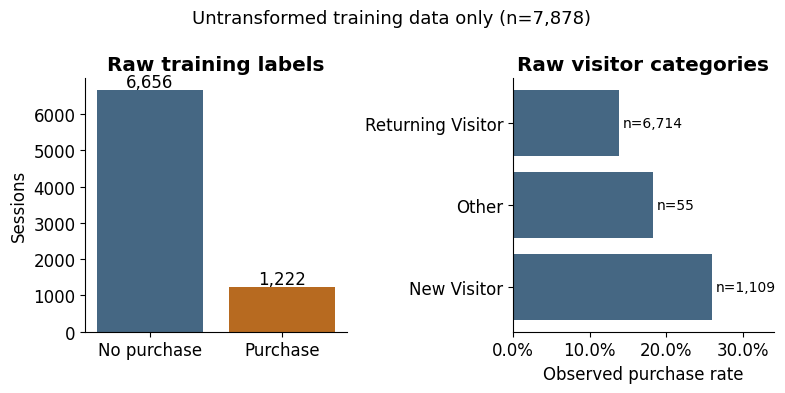

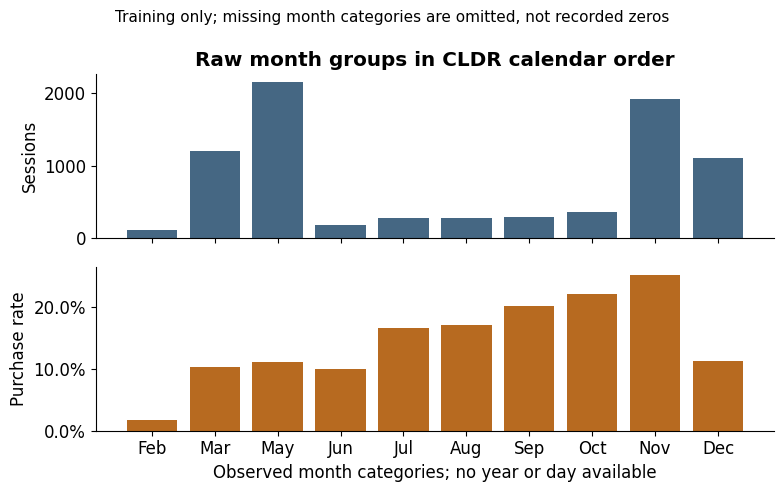

F01–F02 saved as PNG/PDF with native Spark chart tables. No test exploration.


In [84]:
# E87 — Raw training EDA: target, visitor groups and independently ordered months
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False,
 'figure.facecolor':'white','axes.titleweight':'bold'})
COLORS={'no':'#456783','yes':'#B76A20','lr':'#456783','dt':'#B76A20','rf':'#597647'}
def preserve_chart(name,fig):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/(name+'.png'),dpi=220,bbox_inches='tight')
    fig.savefig(FIGURE_DIR/(name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)
def preserve_table(name,frame):
    (FIGURE_DIR/(name+'.jsonl')).write_text('\n'.join(frame.toJSON().collect())+'\n')
visitor_chart=eda_train.groupBy('VisitorType').agg(F.count('*').alias('sessions'),
 F.sum('label').cast('long').alias('buyers')).withColumn('purchase_rate',F.col('buyers')/F.col('sessions')).orderBy('VisitorType')
month_chart=eda_train.groupBy('calendar_month_number','calendar_month_abbreviation').agg(
 F.count('*').alias('sessions'),F.sum('label').cast('long').alias('buyers')).withColumn(
 'purchase_rate',F.col('buyers')/F.col('sessions')).orderBy('calendar_month_number')
assert sum(r['sessions'] for r in month_chart.collect())==7878
for name,frame in [('eda_classes',class_chart),('eda_visitors',visitor_chart),('eda_months',month_chart)]:preserve_table(name,frame)
visitor_chart.show(truncate=False); month_chart.show(12,truncate=False)
fig,axes=plt.subplots(1,2,figsize=(8,4))
axes[0].bar(['No purchase','Purchase'],[6656,1222],color=[COLORS['no'],COLORS['yes']])
axes[0].set(title='Raw training labels',ylabel='Sessions')
for i,v in enumerate([6656,1222]):axes[0].text(i,v+100,f'{v:,}',ha='center')
vr=visitor_chart.collect(); axes[1].barh([r['VisitorType'].replace('_',' ') for r in vr],
 [r['purchase_rate'] for r in vr],color=COLORS['no'])
axes[1].xaxis.set_major_formatter(PercentFormatter(1));axes[1].set(xlabel='Observed purchase rate',title='Raw visitor categories',xlim=(0,.34))
for i,r in enumerate(vr):axes[1].text(r['purchase_rate']+.005,i,f"n={r['sessions']:,}",va='center',fontsize=10)
fig.suptitle('Untransformed training data only (n=7,878)',fontsize=13)
preserve_chart('F01_raw_labels_visitors',fig)
mr=month_chart.collect();labels=[r['calendar_month_abbreviation'] for r in mr]
fig,axes=plt.subplots(2,1,figsize=(8,5),sharex=True)
axes[0].bar(labels,[r['sessions'] for r in mr],color=COLORS['no']);axes[0].set(ylabel='Sessions',title='Raw month groups in CLDR calendar order')
axes[1].bar(labels,[r['purchase_rate'] for r in mr],color=COLORS['yes']);axes[1].set(ylabel='Purchase rate',xlabel='Observed month categories; no year or day available')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Training only; missing month categories are omitted, not recorded zeros',fontsize=11)
preserve_chart('F02_raw_months_calendar',fig)
print('F01–F02 saved as PNG/PDF with native Spark chart tables. No test exploration.')

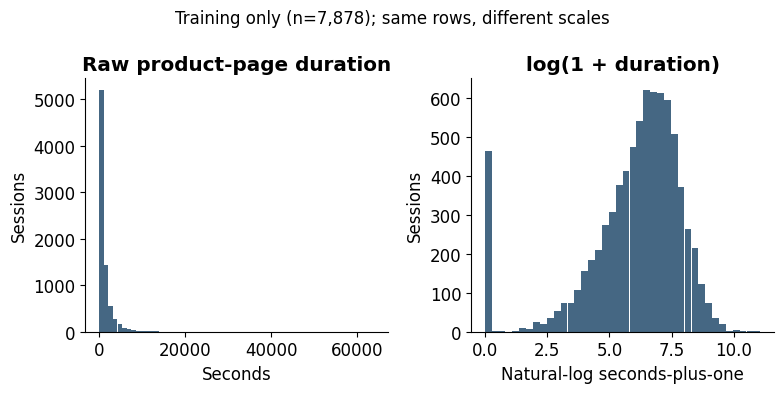

+-------+--------+--------------------+---------------------+-----------------------+
|Revenue|sessions|mean_ExitRates      |mean_BounceRates     |median_product_duration|
+-------+--------+--------------------+---------------------+-----------------------+
|true   |1222    |0.01945061914484452 |0.0048950098715220955|1165.84                |
|false  |6656    |0.046701590946664866|0.024487996276141864 |523.6                  |
+-------+--------+--------------------+---------------------+-----------------------+



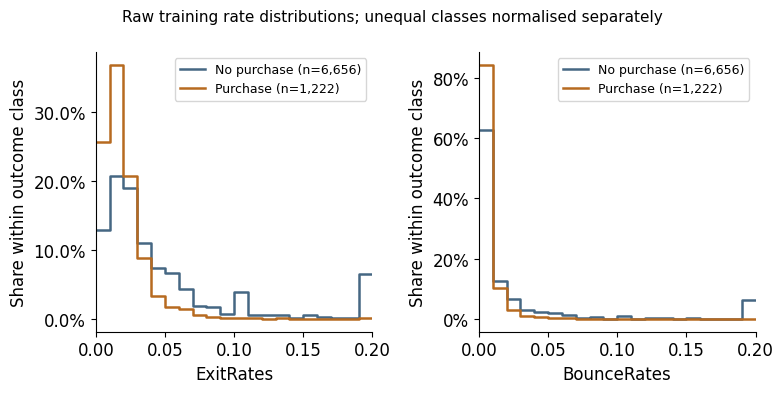

F03–F04 and native histogram tables saved; no rows trimmed or test-derived bins.


In [85]:
# E88 — Raw numeric distributions and duration projection (training only)
def spark_hist(frame,column,upper,bins,label=None):
    width=upper/bins
    bucketed=frame.withColumn('bin',F.least(F.lit(bins-1),F.floor(F.col(column)/width).cast('int')))
    group=['bin'] if label is None else [label,'bin']
    counts=bucketed.groupBy(*group).count().orderBy(*group)
    preserve_table('hist_'+column,counts)
    return counts,width
raw_max=float(eda_train.agg(F.max('ProductRelated_Duration')).first()[0])
duration_counts,duration_width=spark_hist(eda_train,'ProductRelated_Duration',raw_max,60)
log_counts,log_width=spark_hist(prepared_train,'log_ProductRelated_Duration',math.log1p(raw_max),40)
fig,axes=plt.subplots(1,2,figsize=(8,4))
for ax,counts,width,title in [(axes[0],duration_counts,duration_width,'Raw product-page duration'),
 (axes[1],log_counts,log_width,'log(1 + duration)')]:
    records=counts.collect();ax.bar([r['bin']*width for r in records],[r['count'] for r in records],
 width=width*.98,align='edge',color=COLORS['no']);ax.set(title=title,ylabel='Sessions')
axes[0].set_xlabel('Seconds');axes[1].set_xlabel('Natural-log seconds-plus-one')
fig.suptitle('Training only (n=7,878); same rows, different scales',fontsize=12)
preserve_chart('F03_duration_raw_and_log',fig)
rate_summary=eda_train.groupBy('Revenue').agg(F.count('*').alias('sessions'),
 F.avg('ExitRates').alias('mean_ExitRates'),F.avg('BounceRates').alias('mean_BounceRates'),
 F.expr('percentile_approx(ProductRelated_Duration,0.5,10000)').alias('median_product_duration'))
rate_summary.show(truncate=False);preserve_table('eda_rate_summary',rate_summary)
fig,axes=plt.subplots(1,2,figsize=(8,4))
for ax,column in zip(axes,['ExitRates','BounceRates']):
    counts,width=spark_hist(eda_train,column,.2,20,'Revenue')
    for bought,n,color in [(False,6656,COLORS['no']),(True,1222,COLORS['yes'])]:
        records=counts.filter(F.col('Revenue')==bought).collect();values={r['bin']:r['count']/n for r in records}
        ax.step([i*width for i in range(21)],[values.get(min(i,19),0) for i in range(21)],
 where='post',label=('Purchase' if bought else 'No purchase')+f' (n={n:,})',color=color,lw=1.8)
    ax.set(xlabel=column,ylabel='Share within outcome class',xlim=(0,.2));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(fontsize=9)
fig.suptitle('Raw training rate distributions; unequal classes normalised separately',fontsize=11)
preserve_chart('F04_raw_rate_distributions',fig)
print('F03–F04 and native histogram tables saved; no rows trimmed or test-derived bins.')

+-------------------+-----------------------+----------------------+
|variant            |ROC_area_abs_difference|PR_area_abs_difference|
+-------------------+-----------------------+----------------------+
|logistic_regression|4.440892098500626E-16  |5.551115123125783E-17 |
|decision_tree      |1.1102230246251565E-16 |0.0                   |
|random_forest      |5.551115123125783E-16  |0.0                   |
+-------------------+-----------------------+----------------------+



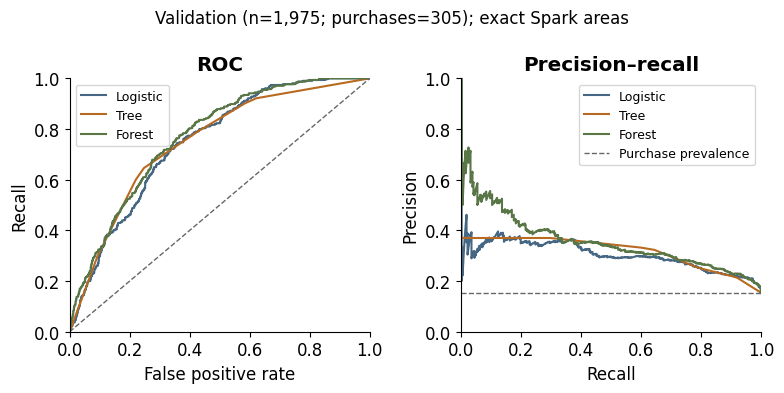

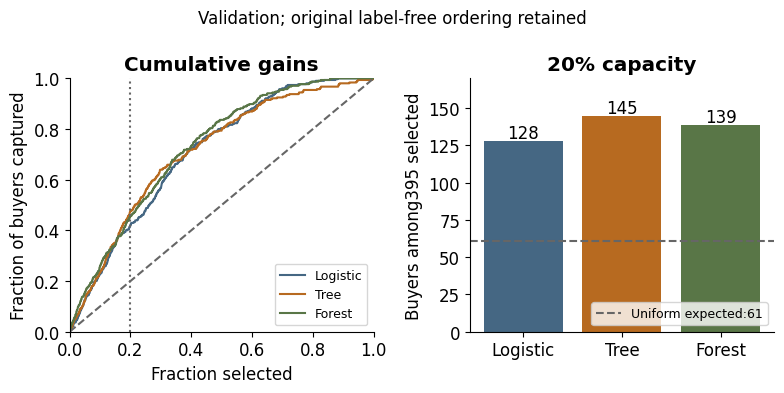

Curve areas independently match Spark evaluators. PR-AUC is not average precision.


In [86]:
# E89 — Exact Spark ROC/PR curves and capacity gains (validation only)
from pyspark.sql import Window
curve_tables={};curve_checks=[]
def trapezoid_area(xs,ys):
    return math.fsum((xs[i]-xs[i-1])*(ys[i]+ys[i-1])/2 for i in range(1,len(xs)))
for variant in baseline_models:
    pred=all_predictions[(variant,'validation')]
    grouped=pred.groupBy('score').agg(F.sum('label').alias('positive'),
        (F.count('*')-F.sum('label')).alias('negative'))
    window=Window.orderBy(F.desc('score')).rowsBetween(Window.unboundedPreceding,Window.currentRow)
    curve=grouped.withColumn('TP',F.sum('positive').over(window)).withColumn('FP',F.sum('negative').over(window))
    curve=curve.withColumn('recall',F.col('TP')/305).withColumn('FPR',F.col('FP')/1670).withColumn('precision',F.col('TP')/(F.col('TP')+F.col('FP'))).orderBy(F.desc('score'))
    cr=curve.collect();curve_tables[variant]=cr
    roc_x=[0.]+[r['FPR'] for r in cr];roc_y=[0.]+[r['recall'] for r in cr]
    pr_x=[0.]+[r['recall'] for r in cr];pr_y=[cr[0]['precision']]+[r['precision'] for r in cr]
    metric=next(m for m in all_metrics if m['variant']==variant and m['split']=='validation')
    roc_diff=abs(trapezoid_area(roc_x,roc_y)-metric['areaUnderROC'])
    pr_diff=abs(trapezoid_area(pr_x,pr_y)-metric['areaUnderPR'])
    assert roc_diff<1e-10 and pr_diff<1e-10,(variant,roc_diff,pr_diff)
    curve_checks.append((variant,roc_diff,pr_diff));preserve_table('curve_'+variant,curve)
    order=Window.orderBy(F.desc('score'),'profile_id')
    gains=pred.withColumn('selected',F.row_number().over(order)).withColumn('buyers',F.sum('label').over(order.rowsBetween(Window.unboundedPreceding,Window.currentRow)))
    gains=gains.withColumn('contact_fraction',F.col('selected')/1975).withColumn('capture',F.col('buyers')/305)
    preserve_table('gains_'+variant,gains.select('selected','buyers','contact_fraction','capture').orderBy('selected'))
spark.createDataFrame(curve_checks,['variant','ROC_area_abs_difference','PR_area_abs_difference']).show(truncate=False)
fig,axes=plt.subplots(1,2,figsize=(8,4))
model_labels={'logistic_regression':'Logistic','decision_tree':'Tree','random_forest':'Forest'}
for variant,color in zip(baseline_models,[COLORS['lr'],COLORS['dt'],COLORS['rf']]):
    cr=curve_tables[variant];axes[0].plot([0]+[r['FPR'] for r in cr],[0]+[r['recall'] for r in cr],label=model_labels[variant],color=color)
    axes[1].plot([0]+[r['recall'] for r in cr],[cr[0]['precision']]+[r['precision'] for r in cr],label=model_labels[variant],color=color)
axes[0].plot([0,1],[0,1],ls='--',color='0.4',lw=1);axes[0].set(xlabel='False positive rate',ylabel='Recall',title='ROC',xlim=(0,1),ylim=(0,1))
axes[1].axhline(305/1975,ls='--',color='0.4',lw=1,label='Purchase prevalence');axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall',xlim=(0,1),ylim=(0,1))
for ax in axes:ax.legend(fontsize=9)
fig.suptitle('Validation (n=1,975; purchases=305); exact Spark areas',fontsize=12)
preserve_chart('F05_validation_ROC_PR',fig)
fig,axes=plt.subplots(1,2,figsize=(8,4))
for variant,color in zip(baseline_models,[COLORS['lr'],COLORS['dt'],COLORS['rf']]):
    rows=[json.loads(s) for s in (FIGURE_DIR/('gains_'+variant+'.jsonl')).read_text().splitlines()]
    axes[0].plot([0]+[r['contact_fraction'] for r in rows],[0]+[r['capture'] for r in rows],color=color,label=model_labels[variant])
axes[0].plot([0,1],[0,1],ls='--',color='0.4');axes[0].axvline(395/1975,ls=':',color='0.4');axes[0].set(xlabel='Fraction selected',ylabel='Fraction of buyers captured',title='Cumulative gains',xlim=(0,1),ylim=(0,1));axes[0].legend(fontsize=9)
axes[1].bar(['Logistic','Tree','Forest'],[128,145,139],color=[COLORS['lr'],COLORS['dt'],COLORS['rf']]);axes[1].axhline(61,color='0.4',ls='--',label='Uniform expected:61')
for i,v in enumerate([128,145,139]):axes[1].text(i,v+2,str(v),ha='center')
axes[1].set(ylabel='Buyers among395 selected',title='20% capacity',ylim=(0,170));axes[1].legend(fontsize=9,loc='lower right')
fig.suptitle('Validation; original label-free ordering retained',fontsize=12)
preserve_chart('F06_validation_gains_capacity',fig)
print('Curve areas independently match Spark evaluators. PR-AUC is not average precision.')

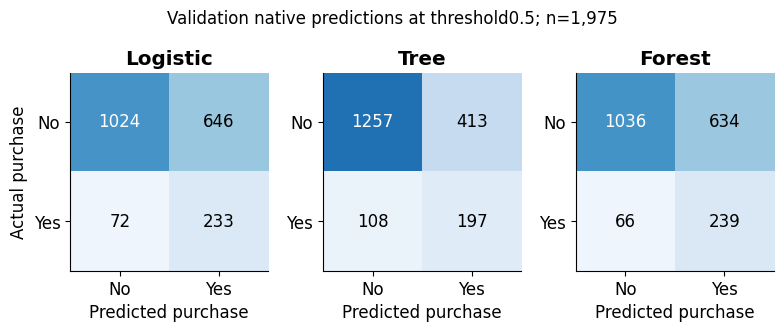

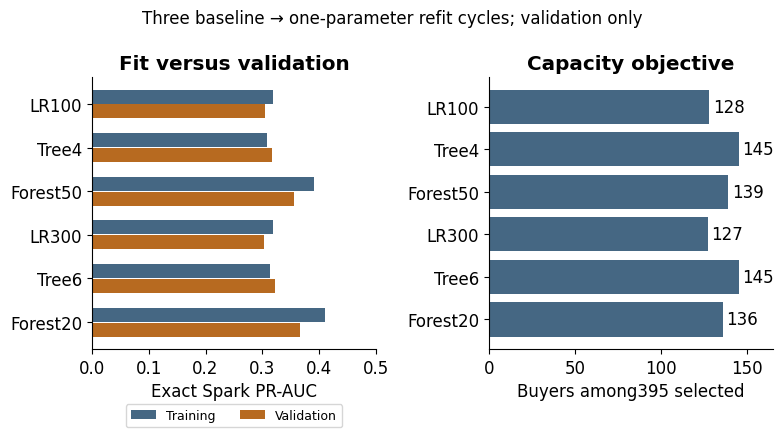

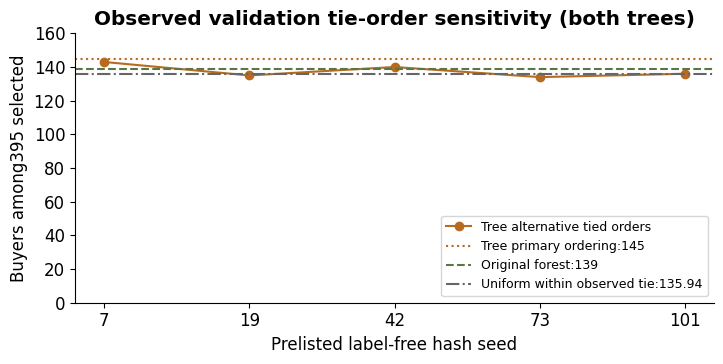

F07–F09 saved. Sensitivity values are not confidence intervals.


In [87]:
# E90 — Error counts, controlled refits and tied-order sensitivity
fig,axes=plt.subplots(1,3,figsize=(8,3.2))
for ax,variant in zip(axes,baseline_models):
    m=next(m for m in all_metrics if m['variant']==variant and m['split']=='validation')
    matrix=np.array([[m['TN'],m['FP']],[m['FN'],m['TP']]])
    ax.imshow(matrix,cmap='Blues',vmin=0,vmax=1670)
    for row in range(2):
        for col in range(2):ax.text(col,row,str(matrix[row,col]),ha='center',va='center',color=('white' if matrix[row,col]>1000 else 'black'),fontsize=12)
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No','Yes'],yticklabels=['No','Yes'],xlabel='Predicted purchase',title=model_labels[variant])
axes[0].set_ylabel('Actual purchase')
fig.suptitle('Validation native predictions at threshold0.5; n=1,975',fontsize=12)
preserve_chart('F07_validation_confusion',fig)
variants=list(all_models);labels=['LR100','Tree4','Forest50','LR300','Tree6','Forest20']
train_m=[next(m for m in all_metrics if m['variant']==v and m['split']=='train') for v in variants]
val_m=[next(m for m in all_metrics if m['variant']==v and m['split']=='validation') for v in variants]
fig,axes=plt.subplots(1,2,figsize=(8,4.6));y=np.arange(6)
axes[0].barh(y-.17,[m['areaUnderPR'] for m in train_m],height=.32,label='Training',color=COLORS['no'])
axes[0].barh(y+.17,[m['areaUnderPR'] for m in val_m],height=.32,label='Validation',color=COLORS['yes'])
axes[0].set(yticks=y,yticklabels=labels,xlabel='Exact Spark PR-AUC',xlim=(0,.5),title='Fit versus validation');axes[0].invert_yaxis();axes[0].legend(fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.18),ncol=2)
axes[1].barh(y,[m['selected_buyers'] for m in val_m],color=COLORS['no']);axes[1].set(yticks=y,yticklabels=labels,xlabel='Buyers among395 selected',title='Capacity objective',xlim=(0,165));axes[1].invert_yaxis()
for i,m in enumerate(val_m):axes[1].text(m['selected_buyers']+2,i,str(m['selected_buyers']),va='center')
fig.suptitle('Three baseline → one-parameter refit cycles; validation only',fontsize=12)
preserve_chart('F08_controlled_iterations',fig)
fig,ax=plt.subplots(figsize=(7.4,3.8));seed_rows=tie_sensitivity_table.filter(F.col('variant')=='decision_tree').orderBy('audit_seed').collect()
ax.plot(range(5),[r['selected_buyers'] for r in seed_rows],'o-',color=COLORS['dt'],label='Tree alternative tied orders')
ax.axhline(145,color=COLORS['dt'],ls=':',label='Tree primary ordering:145')
ax.axhline(139,color=COLORS['rf'],ls='--',label='Original forest:139')
ax.axhline(135.94426229508196,color='0.4',ls='-.',label='Uniform within observed tie:135.94')
ax.set(xticks=range(5),xticklabels=[r['audit_seed'] for r in seed_rows],xlabel='Prelisted label-free hash seed',ylabel='Buyers among395 selected',ylim=(0,160),title='Observed validation tie-order sensitivity (both trees)');ax.legend(fontsize=9,loc='lower right')
preserve_chart('F09_tie_order_sensitivity',fig)
print('F07–F09 saved. Sensitivity values are not confidence intervals.')

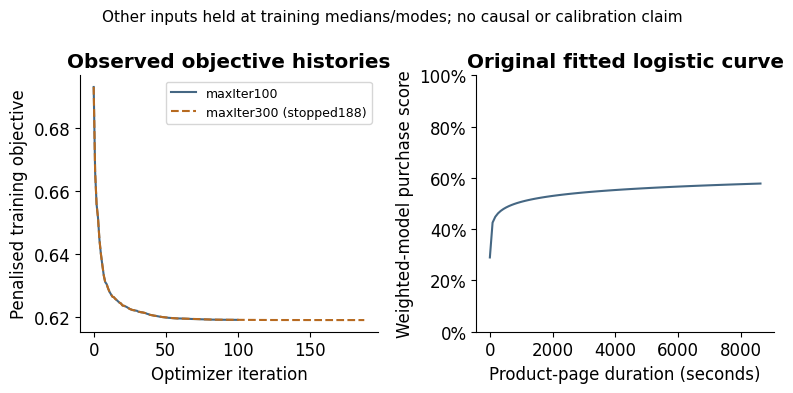

Training-reference values saved; duration curve ends at training99th percentile: 8622.38
LR100 / LR300 actual iterations: 100 / 188
+-------------------+-------------------+
|min(weighted_score)|max(weighted_score)|
+-------------------+-------------------+
| 0.2896666319832001| 0.5779365878312308|
+-------------------+-------------------+

Model path corrected to verified native folder; selected model and all parameters unchanged.


In [92]:
# E91 — Logistic optimizer history and fitted conditional score curve
selection_record['model_directory']=str(BASELINE_DIR/'random_forest_model')
assert Path(selection_record['model_directory']).is_dir()
(ITERATION_DIR/'adopted_candidate.json').write_text(json.dumps(selection_record,indent=2))
reference_numeric={c:float(prepared_train.approxQuantile(c,[.5],0)[0]) for c in numeric_cols}
reference_categories={c:prepared_train.groupBy(c).count().orderBy(F.desc('count'),c).first()[c] for c in categorical_cols}
duration_top=float(train_df.approxQuantile('ProductRelated_Duration',[.99],0)[0])
curve_input=[]
for seconds in np.linspace(0,duration_top,101):
    record={**reference_numeric,**reference_categories,'curve_seconds':float(seconds)}
    record['log_ProductRelated_Duration']=math.log1p(seconds)
    curve_input.append(record)
conditional_input=spark.createDataFrame(curve_input)
conditional_scores=lr_model.transform(preprocessing_model.transform(conditional_input)).select(
 'curve_seconds',vector_to_array('probability')[1].alias('weighted_score')).orderBy('curve_seconds')
preserve_table('lr_conditional_duration',conditional_scores)
(FIGURE_DIR/'lr_curve_reference.json').write_text(json.dumps(dict(numeric_training_medians=reference_numeric,
 categorical_training_modes=reference_categories,duration_training_p99=duration_top),indent=2))
fig,axes=plt.subplots(1,2,figsize=(8,4))
axes[0].plot(range(len(lr_objectives)),lr_objectives,color=COLORS['lr'],label='maxIter100')
axes[0].plot(range(len(lr300_model.summary.objectiveHistory)),lr300_model.summary.objectiveHistory,
 color=COLORS['yes'],ls='--',label=f'maxIter300 (stopped{lr300_model.summary.totalIterations})');axes[0].set(xlabel='Optimizer iteration',ylabel='Penalised training objective',title='Observed objective histories');axes[0].legend(fontsize=9)
cr=conditional_scores.collect();axes[1].plot([r['curve_seconds'] for r in cr],[r['weighted_score'] for r in cr],color=COLORS['lr'])
axes[1].set(xlabel='Product-page duration (seconds)',ylabel='Weighted-model purchase score',title='Original fitted logistic curve',ylim=(0,1));axes[1].yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Other inputs held at training medians/modes; no causal or calibration claim',fontsize=11)
preserve_chart('F10_logistic_history_curve',fig)
print('Training-reference values saved; duration curve ends at training99th percentile:',duration_top)
print('LR100 / LR300 actual iterations:',lr_model.summary.totalIterations,'/',lr300_model.summary.totalIterations)
conditional_scores.select(F.min('weighted_score'),F.max('weighted_score')).show()
print('Model path corrected to verified native folder; selected model and all parameters unchanged.')

In [93]:
# E92 — Inspect saved native tree-node schema for an exact model diagram
native_tree_nodes=spark.read.parquet(str(BASELINE_DIR/'decision_tree_model'/'data'))
native_tree_nodes.printSchema()
native_tree_nodes.orderBy('id').show(2,truncate=False)
preserve_table('decision_tree_native_nodes',native_tree_nodes.orderBy('id'))
print('Native fitted tree nodes:',native_tree_nodes.count(),'| expected:',dt_model.numNodes)
assert native_tree_nodes.count()==dt_model.numNodes==13
print('Diagram will use saved node topology and fitted thresholds, not a surrogate tree.')

root
 |-- id: integer (nullable = true)
 |-- prediction: double (nullable = true)
 |-- impurity: double (nullable = true)
 |-- impurityStats: array (nullable = true)
 |    |-- element: double (containsNull = true)
 |-- rawCount: long (nullable = true)
 |-- gain: double (nullable = true)
 |-- leftChild: integer (nullable = true)
 |-- rightChild: integer (nullable = true)
 |-- split: struct (nullable = true)
 |    |-- featureIndex: integer (nullable = true)
 |    |-- leftCategoriesOrThreshold: array (nullable = true)
 |    |    |-- element: double (containsNull = true)
 |    |-- numCategories: integer (nullable = true)

+---+----------+------------------+--------------------------------+--------+--------------------+---------+----------+----------------------------+
|id |prediction|impurity          |impurityStats                   |rawCount|gain                |leftChild|rightChild|split                       |
+---+----------+------------------+--------------------------------+--------

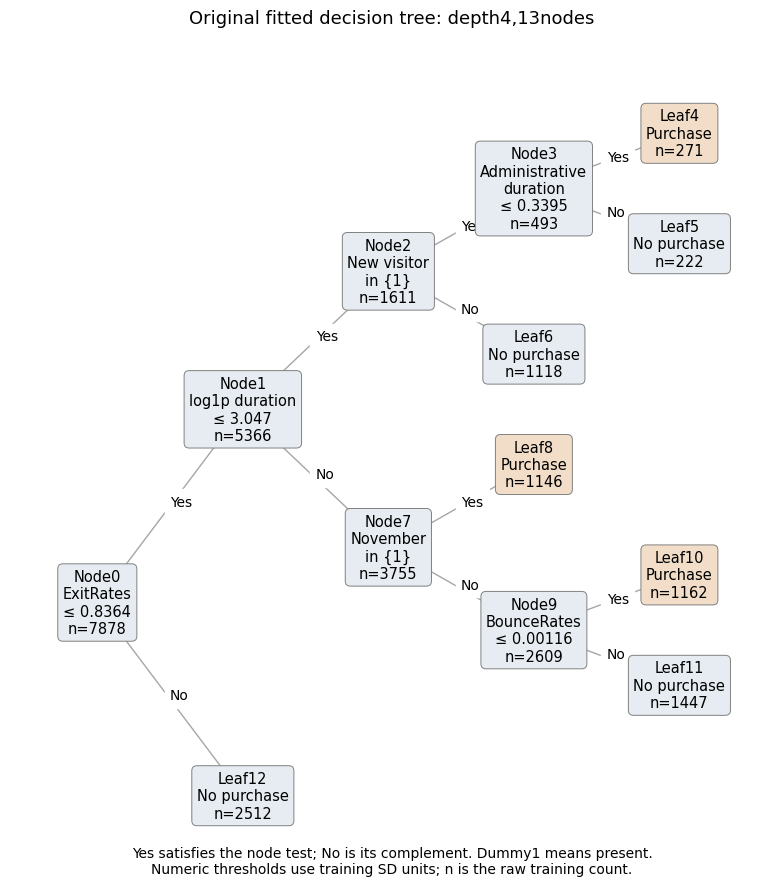

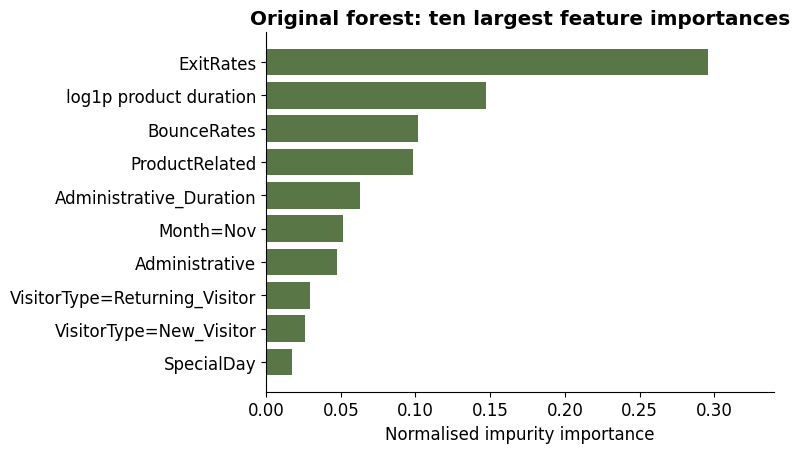

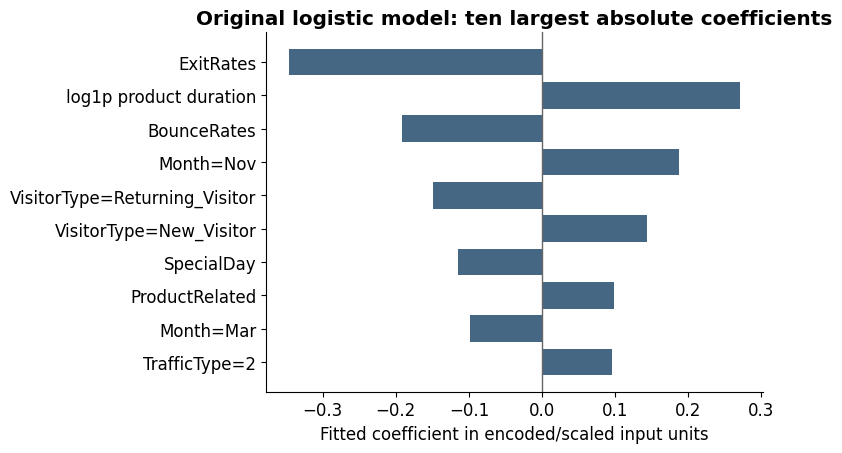

Native thirteen-node topology plotted exactly; all80coefficients/importances preserved.
These are fitted associations, not intervention effects or calibrated response estimates.


In [94]:
# E93 — Visualise the actual fitted tree, forest importances and LR coefficients
import textwrap
nodes={r['id']:r.asDict(recursive=True) for r in native_tree_nodes.collect()}
positions={};leaf_counter=[0]
def tree_position(node_id,depth=0):
    node=nodes[node_id]
    if node['leftChild']==-1:
        y=leaf_counter[0];leaf_counter[0]+=1
    else:
        y=(tree_position(node['leftChild'],depth+1)+tree_position(node['rightChild'],depth+1))/2
    positions[node_id]=(depth,y)
    return y
tree_position(0)
assert len(positions)==13 and leaf_counter[0]==7
fig,ax=plt.subplots(figsize=(8,9))
for node_id,node in nodes.items():
    x,y=positions[node_id]
    if node['leftChild']!=-1:
        for child,label in [(node['leftChild'],'Yes'),(node['rightChild'],'No')]:
            cx,cy=positions[child];ax.plot([x,cx],[y,cy],color='0.65',lw=1,zorder=0)
            ax.text((x+cx)/2,(y+cy)/2,label,fontsize=10,backgroundcolor='white')
        index=node['split']['featureIndex'];threshold=node['split']['leftCategoriesOrThreshold'][0]
        name=feature_name_map[index].replace('_ohe_','=').replace('VisitorType=New_Visitor','New visitor').replace('Month=Nov','November').replace('log_ProductRelated_Duration','log1p duration').replace('_Duration',' duration')
        split=node['split']
        condition=('≤ '+format(threshold,'.4g') if split['numCategories']==-1 else 'in {'+', '.join(format(v,'.4g') for v in split['leftCategoriesOrThreshold'])+'}')
        label='Node'+str(node_id)+'\n'+textwrap.fill(name,17)+'\n'+condition+'\nn='+str(node['rawCount'])
        fill='#E6ECF1'
    else:
        label='Leaf'+str(node_id)+'\n'+('Purchase' if node['prediction']==1 else 'No purchase')+'\nn='+str(node['rawCount'])
        fill=('#F2DEC8' if node['prediction']==1 else '#E6ECF1')
    ax.text(x,y,label,ha='center',va='center',fontsize=10.5,bbox=dict(boxstyle='round,pad=.35',fc=fill,ec='0.5',lw=.7))
ax.set(xlim=(-.6,4.65),ylim=(6.7,-.8));ax.axis('off')
fig.suptitle('Original fitted decision tree: depth4,13nodes',fontsize=13)
fig.text(.5,.02,'Yes satisfies the node test; No is its complement. Dummy1 means present.\nNumeric thresholds use training SD units; n is the raw training count.',ha='center',fontsize=10)
preserve_chart('F11_actual_decision_tree',fig)
importance_records=rf_importances.orderBy(F.desc('importance'),'index').limit(10).collect()
fig,ax=plt.subplots(figsize=(8,4.7));names=[r['feature'].replace('_ohe_','=').replace('log_ProductRelated_Duration','log1p product duration') for r in importance_records]
ax.barh(names[::-1],[r['importance'] for r in importance_records][::-1],color=COLORS['rf']);ax.set(xlabel='Normalised impurity importance',title='Original forest: ten largest feature importances',xlim=(0,.34))
preserve_chart('F12_forest_importance',fig)
coef_records=lr_coefficients_named.orderBy(F.desc(F.abs('coefficient')),'index').limit(10).collect()
fig,ax=plt.subplots(figsize=(8,4.7));names=[r['feature'].replace('_ohe_','=').replace('log_ProductRelated_Duration','log1p product duration') for r in coef_records]
ax.barh(names[::-1],[r['coefficient'] for r in coef_records][::-1],color=COLORS['lr']);ax.axvline(0,color='0.4',lw=1)
ax.set(xlabel='Fitted coefficient in encoded/scaled input units',title='Original logistic model: ten largest absolute coefficients')
preserve_chart('F13_logistic_coefficients',fig)
print('Native thirteen-node topology plotted exactly; all80coefficients/importances preserved.')
print('These are fitted associations, not intervention effects or calibrated response estimates.')

In [95]:
# E94 — Audit figure sources and preserve development evidence before final test
figures=sorted(FIGURE_DIR.glob('F*.png'))
assert len(figures)==13 and all(f.stat().st_size>0 for f in figures)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==source_sha256
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest()==assignment_sha256
assert selected_model is rf_model and selected_model.getNumTrees==100
assert selected_model.getMaxDepth()==6 and selected_model.getMinInstancesPerNode()==50
assert all(s in ['train','validation'] for v,s in all_predictions)
figure_receipt=dict(created_utc=datetime.now(timezone.utc).isoformat(),spark_version=spark.version,
 training_raw_rows=7878,validation_rows=1975,source_sha256=source_sha256,
 assignment_sha256=assignment_sha256,selected_variant=SELECTED_VARIANT,
 exact_curve_checks=curve_checks,final_test_predicted=False,
 figures=[dict(file=f.name,sha256=hashlib.sha256(f.read_bytes()).hexdigest(),bytes=f.stat().st_size) for f in figures],
 renderer='Matplotlib after actual Spark static-export failure; all aggregation/training/evaluation in Spark')
(FIGURE_DIR/'figure_receipt.json').write_text(json.dumps(figure_receipt,indent=2))
FIGURE_ZIP=CHECKPOINT_DIR/('figures-'+ITERATION_DIR.name+'.zip')
with zipfile.ZipFile(FIGURE_ZIP,'w',compression=zipfile.ZIP_DEFLATED) as bundle:
    for source_file in sorted(FIGURE_DIR.iterdir()):
        if source_file.is_file():bundle.write(source_file,source_file.name)
with zipfile.ZipFile(FIGURE_ZIP) as bundle:assert bundle.testzip() is None
print('Development figures:',len(figures),'| selected model parameters/source/allocation: PASS')
print('Figure archive:',FIGURE_ZIP.name,'| bytes:',FIGURE_ZIP.stat().st_size)
print('Final test remains unopened. A clean whole-notebook development run is next.')
files.download(str(FIGURE_ZIP))

Development figures: 13 | selected model parameters/source/allocation: PASS
Figure archive: figures-20261015T044301654002Z.zip | bytes: 3166439
Final test remains unopened. A clean whole-notebook development run is next.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [98]:
# E95 — Bounded repair of the actual Spark plotting static-export dependency
import importlib.metadata
if (FIGURE_DIR/'spark_plot_repair.json').exists() and not (FIGURE_DIR/'spark_plot_repair_attempt1.json').exists():
    (FIGURE_DIR/'spark_plot_repair_attempt1.json').write_text((FIGURE_DIR/'spark_plot_repair.json').read_text())
if (FIGURE_DIR/'spark_plot_repair.json').exists() and not (FIGURE_DIR/'spark_plot_repair_attempt2.json').exists():
    (FIGURE_DIR/'spark_plot_repair_attempt2.json').write_text((FIGURE_DIR/'spark_plot_repair.json').read_text())
repair=dict(started_utc=datetime.now(timezone.utc).isoformat(),
    native_api='Spark DataFrame.plot.bar',initial_error=plot_trial,
    scope='Rendering only: no fitting, scoring, selection or final-test access')
install=subprocess.run([sys.executable,'-m','pip','install','--quiet','--index-url',
    'https://pypi.org/simple','--upgrade','kaleido','plotly'],capture_output=True,text=True,timeout=120)
repair['installer_returncode']=install.returncode
repair['installer_stderr_tail']=install.stderr[-1200:]
repair['plot_methods']=[m for m in dir(class_chart.plot) if not m.startswith('_')]
try:
    repair['kaleido_version']=importlib.metadata.version('kaleido')
    repair['plotly_version']=importlib.metadata.version('plotly')
    native_figure=class_chart.plot.bar(x='Revenue',y='count',
        title='Raw training labels — Spark DataFrame.plot (n=7,878)',
        labels={'Revenue':'Purchase outcome','count':'Training records'})
    native_figure.update_layout(template=None) # Remove only the stale default visual template for current Plotly compatibility.
    native_figure.write_json(str(FIGURE_DIR/'spark_native_labels.json'))
    native_figure.write_html(str(FIGURE_DIR/'spark_native_labels.html'))
    export_code="import plotly.io as pio,sys; pio.read_json(sys.argv[1]).write_image(sys.argv[2],width=1000,height=600,scale=2)"
    export=subprocess.run([sys.executable,'-c',export_code,
        str(FIGURE_DIR/'spark_native_labels.json'),str(FIGURE_DIR/'spark_native_labels.png')],
        capture_output=True,text=True,timeout=60)
    repair['export_returncode']=export.returncode
    repair['export_stderr_head']=export.stderr[:1200]
    repair['export_stderr_tail']=export.stderr[-1800:]
    repair['static_export']='success' if export.returncode==0 else 'failed_after_dependency_repair'
except Exception as error:
    repair['static_export']='failed_after_dependency_repair'
    repair['error_type']=type(error).__name__;repair['error_message']=str(error)[:1800]
(FIGURE_DIR/'spark_plot_repair.json').write_text(json.dumps(repair,indent=2))
print(json.dumps(repair,indent=2))
print('Spark native HTML retained. Plot API has a tree method:',hasattr(class_chart.plot,'tree'))
print('The existing analytical figures use Spark-computed aggregates and native model outputs.')
print('Final-test features, scores and outcomes remain unopened.')


{
  "started_utc": "2026-10-15T05:10:59.784270+00:00",
  "native_api": "Spark DataFrame.plot.bar",
  "initial_error": {
    "spark_version": "4.0.4",
    "rows": 7878,
    "api": "Spark DataFrame.plot.bar",
    "documentation": "https://spark.apache.org/docs/4.0.1/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.plot.html",
    "static_export": "failed",
    "error_type": "ValueError",
    "error_message": "\nImage export using the \"kaleido\" engine requires the kaleido package,\nwhich can be installed using pip:\n    $ pip install -U kaleido\n"
  },
  "scope": "Rendering only: no fitting, scoring, selection or final-test access",
  "installer_returncode": 0,
  "installer_stderr_tail": "",
  "plot_methods": [
    "area",
    "bar",
    "barh",
    "box",
    "data",
    "hist",
    "kde",
    "line",
    "pie",
    "plot_data_map",
    "scatter"
  ],
  "kaleido_version": "1.5.0",
  "plotly_version": "7.1.0",
  "export_returncode": 1,
  "export_stderr_head": "Traceback (most 

In [99]:
# E96 — Define final preparation and assessment before opening test predictions
def prepare_frozen_input(frame):
    cats=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
    nums=['Administrative','Administrative_Duration','Informational','Informational_Duration',
          'ProductRelated','BounceRates','ExitRates','SpecialDay']
    return frame.select('profile_id','label',
        *[F.trim(F.col(c).cast('string')).alias(c) for c in cats],
        *[F.col(c).cast('double').alias(c) for c in nums],
        F.log1p(F.col('ProductRelated_Duration')).alias('log_ProductRelated_Duration'))

def assess_frozen_test(predictions):
    n=predictions.count()
    assert n==2477
    assert predictions.filter(F.col('score').isNull() | F.isnan('score') |
        (F.col('score')<0) | (F.col('score')>1)).count()==0
    counts={(int(r['label']),int(r['prediction'])):int(r['count'])
        for r in predictions.groupBy('label','prediction').count().collect()}
    tn,fp,fn,tp=[counts.get(p,0) for p in [(0,0),(0,1),(1,0),(1,1)]]
    purchases=tp+fn
    assert tn+fp+fn+tp==2477 and purchases==381
    precision=tp/(tp+fp) if tp+fp else 0.
    recall=tp/purchases
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.
    auc={m:BinaryClassificationEvaluator(labelCol='label',rawPredictionCol='score',
         metricName=m,numBins=0).evaluate(predictions) for m in ['areaUnderROC','areaUnderPR']}
    k=math.ceil(.20*n)
    top=predictions.orderBy(F.desc('score'),'profile_id').limit(k)
    selected_buyers=int(top.agg(F.sum('label')).first()[0])
    cutoff=min(r['score'] for r in top.select('score').collect())
    return dict(variant='random_forest',split='test',rows=n,purchases=purchases,
        TN=tn,FP=fp,FN=fn,TP=tp,precision=precision,recall=recall,F1=f1,accuracy=(tn+tp)/n,
        **auc,selected_rows=k,selected_buyers=selected_buyers,recall_at_20=selected_buyers/purchases,
        precision_at_20=selected_buyers/k,lift_at_20=(selected_buyers/k)/(purchases/n),
        cutoff_score=cutoff,cutoff_ties=predictions.filter(F.col('score')==cutoff).count(),
        score_tie_policy='score descending, profile_id ascending; no label used')
print('Final evaluator defined only: exact unweighted metrics, class1 score, ceil20%, unchanged ties.')
print('No test features transformed or scored in this cell.')

Final evaluator defined only: exact unweighted metrics, class1 score, ceil20%, unchanged ties.
No test features transformed or scored in this cell.


In [100]:
# E97 — Freeze verified model, preprocessing and assessment before final test
import inspect, marshal
assert SELECTED_VARIANT=='random_forest' and selected_model is rf_model
assert selected_model.getNumTrees==100 and selected_model.getMaxDepth()==6
assert selected_model.getMinInstancesPerNode()==50 and selected_model.getSeed()==42
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==source_sha256
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest()==assignment_sha256
assert all(s in ['train','validation'] for v,s in all_predictions)
FINAL_TEST_DIR=PROJECT_ROOT/'results'/'final_test'/'v1'
FINAL_TEST_DIR.mkdir(parents=True,exist_ok=True)
assert not (FINAL_TEST_DIR/'started.json').exists(),'Final test has already started: restore saved results; never tune or silently rerun.'
SELECTED_MODEL_PATH=BASELINE_DIR/'random_forest_model'
def fingerprint_folder(folder):
    records=[dict(file=str(p.relative_to(folder)),bytes=p.stat().st_size,
        sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in sorted(folder.rglob('*')) if p.is_file()]
    assert records
    return dict(files=records,sha256=hashlib.sha256(json.dumps(records,sort_keys=True).encode()).hexdigest())
model_fingerprint=fingerprint_folder(SELECTED_MODEL_PATH)
prep_fingerprint=fingerprint_folder(PREPROCESSOR_PATH)
assessment_source=inspect.getsource(assess_frozen_test)
(FINAL_TEST_DIR/'frozen_assessment.py').write_text(assessment_source)
preparation_source=inspect.getsource(prepare_frozen_input)
(FINAL_TEST_DIR/'frozen_preparation.py').write_text(preparation_source)
freeze_manifest=dict(frozen_at_utc=datetime.now(timezone.utc).isoformat(),selected_variant=SELECTED_VARIANT,
 source_sha256=source_sha256,assignment_sha256=assignment_sha256,
 selected_model_path=str(SELECTED_MODEL_PATH),preprocessor_path=str(PREPROCESSOR_PATH),
 model_fingerprint=model_fingerprint,preprocessor_fingerprint=prep_fingerprint,
 assessment_sha256=hashlib.sha256(assessment_source.encode()).hexdigest(),
 preparation_sha256=hashlib.sha256(preparation_source.encode()).hexdigest(),
 profile_columns_ordered=read_manifest['profile_columns_ordered'],
 fitted_parameters={p.name:v for p,v in selected_model.extractParamMap().items()},
 input_columns=model_input_cols,feature_dimensions=80,training_rows=7878,validation_rows=1975,
 class_weights=class_weights,capacity_fraction=.20,capacity_rounding='ceiling',
 interruption_policy='If started.json exists, never silently rescore. Restore a complete preserved predictions.parquet and finish assessment only; if predictions are absent or incomplete, stop and investigate. Do not delete the start record.',
 score_tie_policy='score descending, profile_id ascending; no label used',
 selection_record=selection_record,refit_on_validation=False,post_test_tuning=False,
 source_previously_explored=True,final_test_predicted=False)
FREEZE_PATH=FINAL_TEST_DIR/'freeze_manifest.json'
assert not FREEZE_PATH.exists(),'Existing freeze must be investigated; do not overwrite.'
with FREEZE_PATH.open('x') as handle:json.dump(freeze_manifest,handle,indent=2)
freeze_sha256=hashlib.sha256(FREEZE_PATH.read_bytes()).hexdigest()
print('WORKFLOW FROZEN before final test:',freeze_manifest['frozen_at_utc'])
print('Original forest100trees/depth6/minimum50/seed42; no validation refit.')
print('Freeze SHA-256:',freeze_sha256)
print('Saved model/preprocessor files fingerprinted; evaluator source preserved. No test score yet.')

WORKFLOW FROZEN before final test: 2026-10-15T05:14:22.284145+00:00
Original forest100trees/depth6/minimum50/seed42; no validation refit.
Freeze SHA-256: a9377b67d398fdc6a59488321ff0488e9e66aea9497b1573acd809f4853d14f2
Saved model/preprocessor files fingerprinted; evaluator source preserved. No test score yet.


In [101]:
# E98 — Single final-test phase using the frozen saved original forest
from pyspark.ml.classification import RandomForestClassificationModel
assert hashlib.sha256(FREEZE_PATH.read_bytes()).hexdigest()==freeze_sha256
assert fingerprint_folder(SELECTED_MODEL_PATH)==model_fingerprint
assert fingerprint_folder(PREPROCESSOR_PATH)==prep_fingerprint
assert hashlib.sha256((FINAL_TEST_DIR/'frozen_assessment.py').read_bytes()).hexdigest()==freeze_manifest['assessment_sha256']
assert hashlib.sha256(inspect.getsource(assess_frozen_test).encode()).hexdigest()==freeze_manifest['assessment_sha256']
assert hashlib.sha256(inspect.getsource(prepare_frozen_input).encode()).hexdigest()==freeze_manifest['preparation_sha256']
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==freeze_manifest['source_sha256']
assert hashlib.sha256(ASSIGNMENT_PATH.read_bytes()).hexdigest()==freeze_manifest['assignment_sha256']
assert not (FINAL_TEST_DIR/'started.json').exists(),'Test already started: use preserved outputs.'
with (FINAL_TEST_DIR/'started.json').open('x') as handle:
    json.dump(dict(started_at_utc=datetime.now(timezone.utc).isoformat(),freeze_sha256=freeze_sha256),handle,indent=2)
frozen_preprocessor=type(preprocessing_model).load(str(PREPROCESSOR_PATH))
frozen_forest=RandomForestClassificationModel.load(str(SELECTED_MODEL_PATH))
frozen_raw=spark.read.options(header=True,inferSchema=True,mode='FAILFAST').csv(str(DATA_PATH))
frozen_raw=frozen_raw.withColumn('label',F.col('Revenue').cast('double')).withColumn('profile_id',
    F.sha2(F.to_json(F.struct(*[F.col(c) for c in freeze_manifest['profile_columns_ordered']])),256))
frozen_assignment=spark.read.schema('profile_id string,label double,records long,split string').json(str(ASSIGNMENT_PATH)).select('profile_id','split')
test_raw=frozen_raw.join(frozen_assignment,'profile_id').filter(F.col('split')=='test')
assert test_raw.count()==2477
test_prepared=prepare_frozen_input(test_raw)
test_features=frozen_preprocessor.transform(test_prepared).select('profile_id','label','features').cache()
assert test_features.count()==2477
test_vector_check=test_features.select(vector_to_array('features').alias('values'))
assert test_vector_check.filter(F.exists('values',lambda x:x.isNull() | F.isnan(x) | (F.abs(x)==float('inf')))).count()==0
assert test_vector_check.filter(F.size('values')!=80).count()==0
final_predictions=frozen_forest.transform(test_features).select('profile_id','label','prediction',
    vector_to_array('probability')[1].alias('score')).cache()
assert final_predictions.count()==2477
final_predictions.write.mode('errorifexists').parquet(str(FINAL_TEST_DIR/'predictions.parquet'))
final_test_metrics=assess_frozen_test(final_predictions)
(FINAL_TEST_DIR/'metrics.json').write_text(json.dumps(final_test_metrics,indent=2))
print_metrics('FROZEN ORIGINAL FOREST FINAL TEST',final_test_metrics)
print('Final-test result saved. All model and evaluation choices remain frozen.')

FROZEN ORIGINAL FOREST FINAL TEST test | rows / purchases: 2477 / 381
areaUnderROC=0.765042 | areaUnderPR=0.351065
TN=1267 | FP=829 | FN=89 | TP=292
precision=0.260482 | recall=0.766404 | F1=0.388815 | accuracy=0.62939
selected_rows=496 | selected_buyers=175
recall_at_20=0.459318 | precision_at_20=0.352823 | lift_at_20=2.29381
Final-test result saved. All model and evaluation choices remain frozen.


In [102]:
# E99 — Independently check the preserved final-test output without refitting
saved_final=spark.read.parquet(str(FINAL_TEST_DIR/'predictions.parquet'))
assert saved_final.exceptAll(final_predictions).count()==final_predictions.exceptAll(saved_final).count()==0
records=[r.asDict() for r in saved_final.collect()]
direct=Counter((int(r['label']),int(r['prediction'])) for r in records)
assert [direct[p] for p in [(0,0),(0,1),(1,0),(1,1)]]==[final_test_metrics[k] for k in ['TN','FP','FN','TP']]
top=sorted(records,key=lambda r:(-r['score'],r['profile_id']))[:final_test_metrics['selected_rows']]
assert int(sum(r['label'] for r in top))==final_test_metrics['selected_buyers']
pos=[r['score'] for r in records if r['label']==1];neg=[r['score'] for r in records if r['label']==0]
direct_roc=sum((a>b)+.5*(a==b) for a in pos for b in neg)/(len(pos)*len(neg))
assert abs(direct_roc-final_test_metrics['areaUnderROC'])<1e-12
final_check=dict(rows=len(records),confusion_agrees=True,capacity_agrees=True,
 ROC_abs_difference=abs(direct_roc-final_test_metrics['areaUnderROC']),prediction_readback_exact=True,
 completed_at_utc=datetime.now(timezone.utc).isoformat(),freeze_sha256=freeze_sha256)
(FINAL_TEST_DIR/'independent_check.json').write_text(json.dumps(final_check,indent=2))
print(json.dumps(final_check,indent=2))
print('PASS: checking saved outcomes is not a second model-selection or tuning phase.')

{
  "rows": 2477,
  "confusion_agrees": true,
  "capacity_agrees": true,
  "ROC_abs_difference": 1.2212453270876722e-15,
  "prediction_readback_exact": true,
  "completed_at_utc": "2026-10-15T05:17:37.403906+00:00",
  "freeze_sha256": "a9377b67d398fdc6a59488321ff0488e9e66aea9497b1573acd809f4853d14f2"
}
PASS: checking saved outcomes is not a second model-selection or tuning phase.


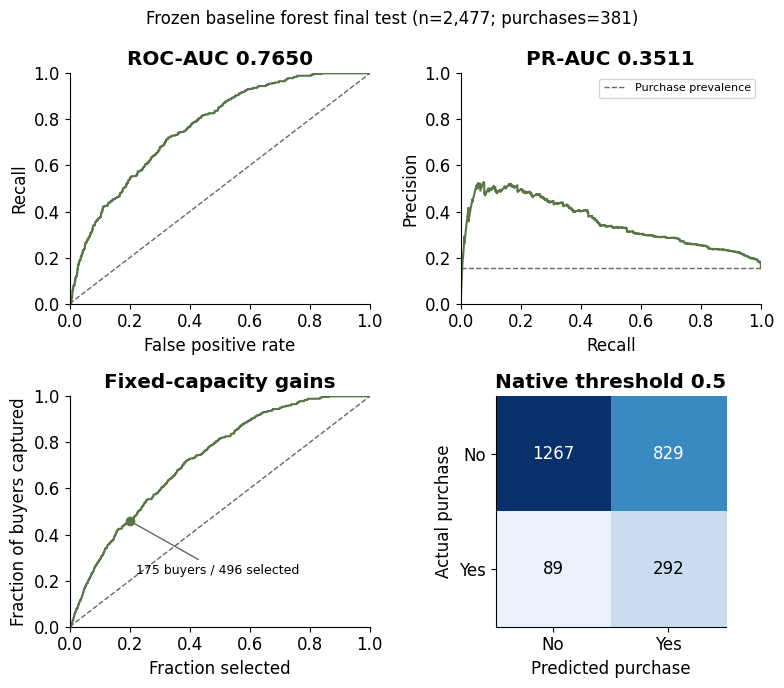

{
  "metrics": {
    "variant": "random_forest",
    "split": "test",
    "rows": 2477,
    "purchases": 381,
    "TN": 1267,
    "FP": 829,
    "FN": 89,
    "TP": 292,
    "precision": 0.2604817127564674,
    "recall": 0.7664041994750657,
    "F1": 0.38881491344873503,
    "accuracy": 0.6293903916027452,
    "areaUnderROC": 0.7650417743583566,
    "areaUnderPR": 0.351065359033528,
    "selected_rows": 496,
    "selected_buyers": 175,
    "recall_at_20": 0.45931758530183725,
    "precision_at_20": 0.3528225806451613,
    "lift_at_20": 2.2938097959529253,
    "cutoff_score": 0.6082756754987182,
    "cutoff_ties": 1,
    "score_tie_policy": "score descending, profile_id ascending; no label used"
  },
  "independent_check": {
    "rows": 2477,
    "confusion_agrees": true,
    "capacity_agrees": true,
    "ROC_abs_difference": 1.2212453270876722e-15,
    "prediction_readback_exact": true,
    "completed_at_utc": "2026-10-15T05:17:37.403906+00:00",
    "freeze_sha256": "a9377b67d398fdc6a5

In [103]:
# E100 — Visualise preserved final-test outcomes without changing the frozen workflow
assert (FINAL_TEST_DIR/'independent_check.json').exists()
saved_final=spark.read.parquet(str(FINAL_TEST_DIR/'predictions.parquet'))
assert saved_final.count()==final_test_metrics['rows']
n=final_test_metrics['rows'];p=final_test_metrics['purchases'];neg=n-p
by_score=saved_final.groupBy('score').agg(F.sum('label').alias('positive'),
    (F.count('*')-F.sum('label')).alias('negative'))
w=Window.orderBy(F.desc('score')).rowsBetween(Window.unboundedPreceding,Window.currentRow)
final_curve=by_score.withColumn('TP',F.sum('positive').over(w)).withColumn('FP',F.sum('negative').over(w))
final_curve=final_curve.withColumn('recall',F.col('TP')/p).withColumn('FPR',F.col('FP')/neg).withColumn('precision',F.col('TP')/(F.col('TP')+F.col('FP'))).orderBy(F.desc('score'))
cr=final_curve.collect()
roc_diff=abs(trapezoid_area([0]+[r['FPR'] for r in cr],[0]+[r['recall'] for r in cr])-final_test_metrics['areaUnderROC'])
pr_diff=abs(trapezoid_area([0]+[r['recall'] for r in cr],[cr[0]['precision']]+[r['precision'] for r in cr])-final_test_metrics['areaUnderPR'])
assert roc_diff<1e-10 and pr_diff<1e-10
order=Window.orderBy(F.desc('score'),'profile_id')
final_gains=saved_final.withColumn('selected',F.row_number().over(order)).withColumn('buyers',F.sum('label').over(order.rowsBetween(Window.unboundedPreceding,Window.currentRow)))
final_gains=final_gains.withColumn('contact_fraction',F.col('selected')/n).withColumn('capture',F.col('buyers')/p)
gains_rows=final_gains.select('selected','buyers','contact_fraction','capture').orderBy('selected').collect()
preserve_table('curve_final_test',final_curve)
preserve_table('gains_final_test',final_gains.select('selected','buyers','contact_fraction','capture').orderBy('selected'))
fig,axes=plt.subplots(2,2,figsize=(8,7))
axes[0,0].plot([0]+[r['FPR'] for r in cr],[0]+[r['recall'] for r in cr],color=COLORS['rf'])
axes[0,0].plot([0,1],[0,1],ls='--',color='0.4',lw=1)
axes[0,0].set(title='ROC-AUC '+format(final_test_metrics['areaUnderROC'],'.4f'),xlabel='False positive rate',ylabel='Recall',xlim=(0,1),ylim=(0,1))
axes[0,1].plot([0]+[r['recall'] for r in cr],[cr[0]['precision']]+[r['precision'] for r in cr],color=COLORS['rf'])
axes[0,1].axhline(p/n,ls='--',color='0.4',lw=1,label='Purchase prevalence')
axes[0,1].set(title='PR-AUC '+format(final_test_metrics['areaUnderPR'],'.4f'),xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1));axes[0,1].legend(fontsize=8)
axes[1,0].plot([0]+[r['contact_fraction'] for r in gains_rows],[0]+[r['capture'] for r in gains_rows],color=COLORS['rf'])
axes[1,0].plot([0,1],[0,1],ls='--',color='0.4',lw=1)
axes[1,0].scatter([final_test_metrics['selected_rows']/n],[final_test_metrics['recall_at_20']],color=COLORS['rf'],zorder=3)
axes[1,0].annotate('175 buyers / 496 selected',xy=(final_test_metrics['selected_rows']/n,final_test_metrics['recall_at_20']),xytext=(.22,.23),fontsize=9,arrowprops={'arrowstyle':'-','color':'0.4'})
axes[1,0].set(title='Fixed-capacity gains',xlabel='Fraction selected',ylabel='Fraction of buyers captured',xlim=(0,1),ylim=(0,1))
cm=np.array([[final_test_metrics['TN'],final_test_metrics['FP']],[final_test_metrics['FN'],final_test_metrics['TP']]])
axes[1,1].imshow(cm,cmap='Blues',vmin=0,vmax=cm.max())
for a in range(2):
    for b in range(2):axes[1,1].text(b,a,str(cm[a,b]),ha='center',va='center',color='white' if cm[a,b]>cm.max()/2 else 'black')
axes[1,1].set(xticks=[0,1],xticklabels=['No','Yes'],yticks=[0,1],yticklabels=['No','Yes'],xlabel='Predicted purchase',ylabel='Actual purchase',title='Native threshold 0.5')
fig.suptitle('Frozen baseline forest final test (n=2,477; purchases=381)',fontsize=12)
preserve_chart('F14_final_test_assessment',fig)
assert fingerprint_folder(SELECTED_MODEL_PATH)==model_fingerprint and fingerprint_folder(PREPROCESSOR_PATH)==prep_fingerprint
final_figure_receipt=dict(created_utc=datetime.now(timezone.utc).isoformat(),freeze_sha256=freeze_sha256,
    ROC_area_abs_difference=roc_diff,PR_area_abs_difference=pr_diff,
    file='F14_final_test_assessment.png',sha256=hashlib.sha256((FIGURE_DIR/'F14_final_test_assessment.png').read_bytes()).hexdigest(),
    plotting_only_after_test=True,model_or_rule_changes_after_test=False)
(FIGURE_DIR/'final_figure_receipt.json').write_text(json.dumps(final_figure_receipt,indent=2))
print(json.dumps(dict(metrics=final_test_metrics,independent_check=final_check,figure_check=final_figure_receipt),indent=2))
print('Only preserved outcomes were read; no model refit or second scoring was performed.')


In [104]:
# E101 — Preserve all native evidence after the single frozen final-test phase
assert fingerprint_folder(SELECTED_MODEL_PATH)==model_fingerprint
assert fingerprint_folder(PREPROCESSOR_PATH)==prep_fingerprint
assert hashlib.sha256(FREEZE_PATH.read_bytes()).hexdigest()==freeze_sha256
assert final_check['prediction_readback_exact'] and final_check['confusion_agrees'] and final_check['capacity_agrees']
handoff=dict(created_utc=datetime.now(timezone.utc).isoformat(),spark_version=spark.version,
    python_version=platform.python_version(),source_sha256=source_sha256,assignment_sha256=assignment_sha256,
    freeze_sha256=freeze_sha256,selected_model='baseline random forest:100trees/depth6/minimum50/seed42',
    final_test_metrics=final_test_metrics,final_check=final_check,
    no_post_test_model_or_rule_changes=True,
    colab_url='https://colab.research.google.com/drive/1_-sgqFxsJ5SUeWsVXR39i2mGhRhjpeA1',
    execution_note='Development E01–E94 executed in a fresh runtime; E91–E94 rerun for presentation labels. E95 export-only repair. E97 workflow freeze precedes E98 single test. E99–E100 inspect saved predictions only.',
    rerun_note='The saved executed outputs are the assessment evidence. Freeze/start guards intentionally prevent re-running the final test in the existing project. Restore saved final_test outcomes instead. Never delete these guards to tune or repeat assessment.')
(FINAL_TEST_DIR/'handoff_receipt.json').write_text(json.dumps(handoff,indent=2))
HANDOFF_ZIP=CHECKPOINT_DIR/'I4_BDAS_native_results_20261015.zip'
assert not HANDOFF_ZIP.exists(),'Preserve the existing final-phase archive; do not silently replace it.'
manifest=[]
with zipfile.ZipFile(HANDOFF_ZIP,'w',compression=zipfile.ZIP_DEFLATED) as bundle:
    with zipfile.ZipFile(NATIVE_ITERATION_ZIP) as previous:
        assert previous.testzip() is None
        for info in previous.infolist():
            if not info.is_dir():
                data=previous.read(info.filename);bundle.writestr(info.filename,data)
                manifest.append(dict(file=info.filename,bytes=len(data),sha256=hashlib.sha256(data).hexdigest()))
    for folder,prefix in [(FIGURE_DIR,'figures'),(FINAL_TEST_DIR,'final_test')]:
        for source_file in sorted(folder.rglob('*')):
            if source_file.is_file():
                name=str(Path(prefix)/source_file.relative_to(folder));bundle.write(source_file,name)
                manifest.append(dict(file=name,bytes=source_file.stat().st_size,sha256=hashlib.sha256(source_file.read_bytes()).hexdigest()))
    bundle.writestr('native_file_manifest.json',json.dumps(manifest,indent=2))
with zipfile.ZipFile(HANDOFF_ZIP) as bundle:
    assert bundle.testzip() is None
    print('Native evidence archive:',HANDOFF_ZIP.name,'| files:',len(bundle.namelist()))
print('Archive bytes:',HANDOFF_ZIP.stat().st_size)
print('Archive SHA-256:',hashlib.sha256(HANDOFF_ZIP.read_bytes()).hexdigest())
print('Includes original CSV/calendar source and licence, split/preparation/integration, six models, figures and frozen final-test outcomes.')
print('Export the executed notebook separately; the written report and student screenshots will be assembled locally.')
files.download(str(HANDOFF_ZIP))


Native evidence archive: I4_BDAS_native_results_20261015.zip | files: 343
Archive bytes: 9427684
Archive SHA-256: 26edb40418f16571ca81a2ea37aa29f1ae91e3f7c4d9e8a2c8c827221ec3ad14
Includes original CSV/calendar source and licence, split/preparation/integration, six models, figures and frozen final-test outcomes.
Export the executed notebook separately; the written report and student screenshots will be assembled locally.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>